# Within-pattern adaptive CV-MB-QRC: Lyapunov-spectrum and visibility preflight

## 1. Scientific scope and claim language

This notebook tests, rather than assumes, the dominance relation
$$R_{\mathrm{AD}}\succ\{R_{\mathrm{NA}},R_{\mathrm{CV}}\}.$$

| symbol | architecture |
|---|---|
| $R_{\mathrm{AD}}$ | **within-pattern adaptive** CV measurement-based quantum reservoir. Each clock is a layered CV cluster, and the homodyne angle of layer $j$ depends, through a bounded controller, on outcomes of layers $<j$ **of the same clock** |
| $R_{\mathrm{NA}}$ | the identical layered reservoir with every outcome-to-later-basis edge removed ($g=0$, same code path) |
| $R_{\mathrm{CV}}$ | conventional recurrent optical-loop CV-QRC (García-Beni *et al.* 2023, Piquasso) |

**Why a new notebook.** The predecessor (`adaptive_cv_mbqrc_advantage_preflight_colab.ipynb`) used an *inter-clock* feedback rule, $s_{k,i}=s^{(0)}_{k,i}+g\tanh(y_{k-1,i})$: a tap outcome of clock $k-1$ modified clock $k$. That is a feedback reservoir, not sequential MBQC adaptivity within one measurement pattern, and it returned `NO-GO`. Its negative result is preserved and audited in §5.

**Permitted wording.** The strongest description this notebook can ever print is

> *Adaptive measurement-based reservoir advantage over matched nonadaptive CV-MB-QRC and conventional CV-QRC architectures.*

No claim of quantum advantage over classical computation is made. Every model here uses only Gaussian states, Gaussian operations and homodyne measurements with classical feedforward. Each conditional trajectory therefore stays Gaussian and is efficiently classically simulable (Bartlett *et al.* 2002; this notebook's own adapter simulates each trajectory in time polynomial in the number of modes). An adaptive win would therefore be an *architectural* result about physical feature generation. It would not be a complexity-theoretic separation.

**Modes.**

| `RUN_MODE` | content | conclusions |
|---|---|---|
| `unit` | deterministic physics, engine, Lyapunov and statistics tests | none |
| `research_dryrun` | the entire research workflow at toy size (calibration → scan → lock → validation → spectra → kernels → task → ledger → robustness → claims) | control flow only |
| `preflight` | reduced-size structural study, structural-first stopping rule, task pilot only if every structural gate passes, power and runtime, go/no-go | never "advantage established" |
| `research` | 48–72 h locked run | full claim ladder |

**Labels.** Every operation is labelled as one of: *native engine operation*, *compiled through the engine*, *exact adapter*, *approximate adapter*, or *idealized model*. Every result is labelled as one of: *established literature*, *adaptation of literature*, *new definition*, *new conjecture*, or *numerical observation*.

## 2. User control panel
Every scientifically important setting is in the next cell. `PREREGISTERED` and the structural grid were fixed before any structural or task data were computed.

In [1]:
# ============================ USER CONTROL PANEL — CHANGE ONLY THIS CELL ============================
import os

RUN_MODE = "preflight"
# Valid:
# "unit"
# "research_dryrun"
# "preflight"
# "research"
RUN_MODE = os.environ.get("AWP_RUN_MODE", RUN_MODE)     # optional non-interactive override (batch execution); normally unset

RESUME_FROM_CHECKPOINT = True
PREFER_GPU = True
MASTER_SEED = 20261003

CHECKPOINT_DIR = "./adaptive_within_pattern_checkpoints"
RESULTS_DIR = "./adaptive_within_pattern_results"

AVAILABLE_RUNTIME_HOURS = 72.0
BLAS_THREADS = None                      # hardware knob only (results unaffected)

# ---------------- disjoint seed banks (realization indices) ----------------
CALIBRATION_SEEDS  = list(range(100_000, 100_200))
EXPLORATION_SEEDS  = list(range(200_000, 200_400))
VALIDATION_SEEDS   = list(range(300_000, 300_400))
PILOT_SEEDS        = list(range(400_000, 400_400))
CONFIRMATION_SEEDS = list(range(900_000, 900_400))

# ---------------- preregistered structural and statistical rules ----------------
PREREGISTERED = dict(
    theta_min=0.15,                   # safe homodyne-angle margin: theta in [theta_min, pi - theta_min]
    controller="nearest-neighbour causal flow",   # G[j, j-1] = 1 per wire; f = tanh; one global gain g
    witness_max_delay=2,              # K* = {c^(3,1)_{tc,tl}: 0 <= tc, tl <= D, tc != tl}, uniform weights
    escape_cov=1e6, escape_mean=1e3,  # a trajectory escapes if max|Gamma| > escape_cov or max|r| > escape_mean
    escape_pmax=0.01,                 # admissible only if the one-sided 95% Clopper-Pearson upper bound < escape_pmax
    channel_margin=0.02,              # admissible only if Lambda_1^ch <= -channel_margin
    snr_min=5.0,                      # visible-response resolution threshold (validation bank)
    whitening_eps_rel=1e-6,           # epsilon = eps_rel * tr(Sigma_noise) / dim (task-independent rule)
    ridge_struct_rel=1e-3,            # structural ridge lambda_R = ridge_struct_rel * mean feature eigenvalue
    zero_tol_rel=1e-9,                # exact-zero kernel test tolerance
    alpha=0.05, power_target=0.90,
    delta_min_floor=0.02,             # practical floor of the smallest effect of interest (see §15.1 for the rule)
)

# ---------------- physical base point (shared by AD, NA, CV) ----------------
BASE = dict(
    inter_wire="chain", inter_weight=1.0,   # C_Z couplings between neighbouring wires inside each layer
    squeezing_db=12.0,                      # cluster squeezing
    enc_scale=0.5,                          # layer-1 shear s1 = alpha_i u + beta_i, alpha, beta ~ U(-a, a)
    later_scale=0.5,                        # fixed later-layer shears beta_ij ~ U(-b, b)
    loop_transmissivity=1.0, detector_efficiency=1.0, homodyne_noise=0.0, angle_jitter=0.0, feedforward_gain_error=0.0,
    cv_input_squeezing=1.0,
)
FOCK_CUTOFF = None                          # not applicable: exactly Gaussian engines

_LAM = [float(10.0 ** e) for e in range(-8, 3)]
CONFIGS = {
    "unit": dict(N_main=2, N_second=3, L_depth=3, N_fss=[2], gain_grid=[0.0, 0.3], T_grid=[0.4],
                 n_calib=1, calib_paths=128, calib_clocks=60, n_explore=1, n_validate=1, stab_paths=32,
                 kernel_paths=128, kernel_clocks=12, kernel_fd_step=0.1, noise_samples=256, shots_primary=128, shots_list=[32, 128],
                 lyap_paths=2, lyap_burn=20, lyap_len=60, lyap_qr=5, lyap_ntan="all", chan_paths=128, chan_window=20, chan_dirs=3,
                 res_paths=32, res_clocks=200, washout=50, train=300, test=150, trajectories=64, n_pilot=0, n_confirm=0,
                 robust_realizations=0, squeezing_grid=[12.0], loss_grid=[1.0], eta_grid=[1.0], jitter_grid=[0.0], ff_grid=[0.0], resolution_grid=[0.0], pilot_reps=1,
                 ridge_grid=_LAM, poly_pca_dim=12, bootstrap=200, power_sims=300, native_shots=200),
    "research_dryrun": dict(N_main=2, N_second=3, L_depth=3, N_fss=[2, 3], gain_grid=[0.0, 0.2, 0.5], T_grid=[0.3, 0.6],
                 n_calib=1, calib_paths=128, calib_clocks=60, n_explore=2, n_validate=2, stab_paths=32,
                 kernel_paths=128, kernel_clocks=12, kernel_fd_step=0.1, noise_samples=256, shots_primary=64, shots_list=[32, 64],
                 lyap_paths=2, lyap_burn=20, lyap_len=60, lyap_qr=5, lyap_ntan="all", chan_paths=128, chan_window=20, chan_dirs=3,
                 res_paths=32, res_clocks=200, washout=50, train=300, test=150, trajectories=64, n_pilot=3, n_confirm=3,
                 robust_realizations=2, squeezing_grid=[9.0, 12.0], loss_grid=[1.0, 0.95], eta_grid=[1.0, 0.9], jitter_grid=[0.0, 0.02],
                 ff_grid=[0.0, 0.02], resolution_grid=[0.0, 0.01], pilot_reps=2, ridge_grid=_LAM, poly_pca_dim=12, bootstrap=200, power_sims=300, native_shots=100),
    "preflight": dict(N_main=3, N_second=4, L_depth=3, N_fss=[2, 3, 4], gain_grid=[0.0, 0.1, 0.2, 0.3, 0.5, 0.8], T_grid=[0.2, 0.4, 0.6, 0.8],
                 n_calib=3, calib_paths=512, calib_clocks=300, n_explore=2, n_validate=4, stab_paths=256,
                 kernel_paths=1024, kernel_clocks=16, kernel_fd_step=0.1, noise_samples=4096, shots_primary=512, shots_list=[64, 512],
                 lyap_paths=6, lyap_burn=100, lyap_len=400, lyap_qr=5, lyap_ntan="all", chan_paths=512, chan_window=30, chan_dirs=4,
                 res_paths=128, res_clocks=800, washout=200, train=2000, test=1000, trajectories=512, n_pilot=12, n_confirm=0,
                 robust_realizations=3, squeezing_grid=[9.0, 12.0, 15.0], loss_grid=[1.0, 0.95, 0.9], eta_grid=[1.0, 0.9],
                 jitter_grid=[0.0, 0.02], ff_grid=[0.0, 0.02], resolution_grid=[0.0, 0.01], pilot_reps=2, ridge_grid=_LAM, poly_pca_dim=24, bootstrap=2000, power_sims=4000,
                 native_shots=400),
    "research": dict(N_main=3, N_second=4, L_depth=3, N_fss=[2, 3, 4, 5], gain_grid=[0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.65, 0.8, 1.0],
                 T_grid=[0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], n_calib=10, calib_paths=1024, calib_clocks=500, n_explore=30, n_validate=30,
                 stab_paths=512, kernel_paths=4096, kernel_clocks=16, kernel_fd_step=0.1, noise_samples=16384, shots_primary=512,
                 shots_list=[128, 512, 2048], lyap_paths=16, lyap_burn=200, lyap_len=1500, lyap_qr=5, lyap_ntan="all",
                 chan_paths=2048, chan_window=40, chan_dirs=6, res_paths=256, res_clocks=2000, washout=200, train=6000, test=3000,
                 trajectories=1024, n_pilot=15, n_confirm=50, robust_realizations=20, squeezing_grid=[9.0, 12.0, 15.0],
                 loss_grid=[1.0, 0.95, 0.9], eta_grid=[1.0, 0.9, 0.8], jitter_grid=[0.0, 0.01, 0.03], ff_grid=[0.0, 0.02, 0.05], resolution_grid=[0.0, 0.01, 0.05], pilot_reps=2,
                 ridge_grid=_LAM, poly_pca_dim=48, bootstrap=5000, power_sims=10000, native_shots=2000),
}
assert RUN_MODE in CONFIGS, f"RUN_MODE must be one of {list(CONFIGS)}"
assert all(set(c) == set(CONFIGS["preflight"]) for c in CONFIGS.values()), "all configurations must define the same keys"
CFG = dict(CONFIGS[RUN_MODE])
print(f"RUN_MODE = {RUN_MODE!r}")

RUN_MODE = 'preflight'


## 3. Environment and reproducibility manifest

### 3.1 Installation with pinned versions
Piquasso is pinned to 8.0.1. PhotoGraphiQ is pinned to the commit used by the source notebooks (`6d49da06…`, branch `manuscript-experiments`). On Colab it is cloned and installed; locally an existing installation is used and its commit is recorded. PhotoGraphiQML is **not** needed: the readout is closed-form ridge regression, and PhotoGraphiQML's MuTA models are qubit ansätze.

In [2]:
import sys, subprocess, importlib, importlib.util, importlib.metadata as _md, platform, json, hashlib, time, uuid, math, zlib
import pickle, warnings, contextlib, itertools, shutil, copy, re
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content/sample_data")

def _ver(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None

def _sh(*cmd, check=True):
    return subprocess.run(cmd, check=check, capture_output=True, text=True).stdout.strip()

PG_URL, PG_COMMIT = "https://github.com/chinmoybiswasdeep/PhotoGraphiQ.git", "6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e"
_need = [] if _ver("piquasso") == "8.0.1" else ["piquasso==8.0.1"]
_need += [p for p, m in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("networkx", "networkx"), ("psutil", "psutil"),
                         ("scipy", "scipy"), ("threadpoolctl", "threadpoolctl")] if importlib.util.find_spec(m) is None]
if _need:
    print("pip install:", " ".join(_need))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)
if importlib.util.find_spec("photographiq") is None:
    _root = Path("/content/awp_repos" if IN_COLAB else "awp_repos").resolve() / "PhotoGraphiQ"
    if not (_root / ".git").exists():
        _root.parent.mkdir(parents=True, exist_ok=True)
        _sh("git", "-c", "core.longpaths=true", "clone", "--quiet", "--no-checkout", PG_URL, str(_root))
        _sh("git", "-C", str(_root), "config", "core.longpaths", "true")
        _sh("git", "-C", str(_root), "-c", "advice.detachedHead=false", "checkout", "--quiet", PG_COMMIT)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", str(_root)], check=True)
    importlib.invalidate_caches()
if IN_COLAB and importlib.util.find_spec("cupy") is None and shutil.which("nvidia-smi"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cupy-cuda12x"], check=False)

def _pg_commit():
    """Commit of the installed PhotoGraphiQ, from PEP 610 direct_url.json -> git, else 'unknown'."""
    try:
        url = json.loads(_md.distribution("photographiq").read_text("direct_url.json"))["url"]
        path = Path(re.sub(r"^file:/+", "", url).replace("%20", " "))
        path = path if path.exists() else Path("/" + str(path))
        return _sh("git", "-C", str(path), "rev-parse", "HEAD", check=False) or "unknown (no git metadata)", str(path)
    except Exception as exc:                                            # noqa: BLE001
        return f"unknown ({type(exc).__name__})", "?"
PG_INSTALLED_COMMIT, PG_SOURCE_PATH = _pg_commit()
print("PhotoGraphiQ commit:", PG_INSTALLED_COMMIT, "| pinned:", PG_COMMIT, "| match:", PG_INSTALLED_COMMIT == PG_COMMIT)

PhotoGraphiQ commit: 6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e | pinned: 6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e | match: True


### 3.2 Imports, machine and software provenance

In [3]:
# A fresh numba cache per session: re-loading Piquasso's cached numba functions in a second process crashed the kernel here
# ("LLVM ERROR: Symbol not found: ...hessenberg..."); compiling fresh in every session avoids it (costs a few seconds).
import tempfile
os.environ["NUMBA_CACHE_DIR"] = tempfile.mkdtemp(prefix="awp_numba_")
import numpy as np, scipy, scipy.linalg as sla, scipy.stats as sst, scipy.special as ssp
import pandas as pd, matplotlib, matplotlib.pyplot as plt, networkx as nx, psutil, threadpoolctl
from numpy.polynomial import legendre as npleg
from IPython.display import display, Markdown
import piquasso as pq
import photographiq as pg
from photographiq.backends import GaussianBackend

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # overflow/NaN from escaping trajectories: escapes are detected, counted and reported explicitly (test N11)
if BLAS_THREADS:
    _BLAS = threadpoolctl.threadpool_limits(int(BLAS_THREADS), user_api="blas")
SESSION_ID, NOTEBOOK_T0 = uuid.uuid4().hex[:12], time.perf_counter()
CKPT = Path(CHECKPOINT_DIR).resolve() / RUN_MODE
RES = Path(RESULTS_DIR).resolve() / RUN_MODE
for _d in (CKPT, RES, RES / "figures"):
    _d.mkdir(parents=True, exist_ok=True)

def _cpu_model():
    try:
        if platform.system() == "Windows":
            return _sh("powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name", check=False).splitlines()[0].strip()
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except Exception:                                                    # noqa: BLE001
        pass
    return platform.processor() or "unknown"

def _nvidia():
    exe = shutil.which("nvidia-smi")
    if not exe:
        return {}
    q = _sh(exe, "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader", check=False).split(",")
    cuda = re.search(r"CUDA Version:\s*([\d.]+)", _sh(exe, check=False))
    return dict(gpu=q[0].strip(), vram=q[1].strip(), driver=q[2].strip(), cuda_driver_api=cuda.group(1) if cuda else "?") if len(q) == 3 else {}

_vm = psutil.virtual_memory(); NV = _nvidia()
ENV = {"session": SESSION_ID, "run mode": RUN_MODE, "location": "Google Colab" if IN_COLAB else "local",
       "OS": platform.platform(), "python": platform.python_version(), "CPU": _cpu_model(),
       "cores (physical/logical)": f"{psutil.cpu_count(logical=False)}/{psutil.cpu_count()}", "RAM (GB)": round(_vm.total / 2**30, 1),
       "free disk at results dir (GB)": round(shutil.disk_usage(RES).free / 2**30, 1),
       "GPU": NV.get("gpu", "none detected"), "VRAM": NV.get("vram", "-"), "driver": NV.get("driver", "-"),
       "CUDA (driver API)": NV.get("cuda_driver_api", "-"),
       "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
       "Piquasso": pq.__version__, "PhotoGraphiQ": f"{pg.__version__} @ {PG_INSTALLED_COMMIT}",
       "CuPy": _ver("cupy-cuda12x") or _ver("cupy") or "not installed",
       "PyTorch": _ver("torch") or "not installed (not needed)", "JAX": _ver("jax") or "not installed (not needed)",
       "BLAS": ", ".join(f"{d['internal_api']}:{d['num_threads']}" for d in threadpoolctl.threadpool_info() if d["user_api"] == "blas")}
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(ENV.items(), columns=["item", "value"]).set_index("item"))

,value
item,
session,83d1c2b32b0c
run mode,preflight
location,local
OS,Windows-11-10.0.26200-SP0
python,3.12.14
CPU,12th Gen Intel(R) Core(TM) i5-12450HX
cores (physical/logical),8/12
RAM (GB),23.7
free disk at results dir (GB),30.7


### 3.3 GPU inventory and CuPy smoke test
The engine-level CPU/GPU benchmark and the numerical agreement test are in §5.6, once the actual engine exists. Here we only check that CUDA works. PyTorch and JAX are detected but not used: no derivative in this notebook needs automatic differentiation. Analytic derivatives come from Cauchy contour integrals (§8).

In [4]:
def _register_cuda_wheel_dlls():
    if platform.system() != "Windows":
        return
    import site
    for sp in site.getsitepackages() + [site.getusersitepackages()]:
        for d in Path(sp).glob("nvidia/*/bin"):
            os.add_dll_directory(str(d)); os.environ["PATH"] = str(d) + os.pathsep + os.environ.get("PATH", "")

CUPY_OK, CUPY_INFO = False, "not attempted (PREFER_GPU=False)"
if PREFER_GPU:
    try:
        _register_cuda_wheel_dlls()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import cupy as cp
        _a = cp.asarray(np.random.default_rng(0).normal(size=(64, 8, 8)))
        _err = float(np.abs(cp.asnumpy(cp.linalg.cholesky(_a @ _a.transpose(0, 2, 1) + 8 * cp.eye(8)))
                            - np.linalg.cholesky(cp.asnumpy(_a @ _a.transpose(0, 2, 1)) + 8 * np.eye(8))).max())
        props = cp.cuda.runtime.getDeviceProperties(0)
        CUPY_INFO = dict(device=props["name"].decode() if isinstance(props["name"], bytes) else str(props["name"]),
                         vram_gb=round(props["totalGlobalMem"] / 2**30, 2), cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),
                         cupy=cp.__version__, batched_cholesky_err=_err)
        CUPY_OK = _err < 1e-10
    except Exception as exc:                                              # noqa: BLE001
        CUPY_INFO = f"no usable GPU: {type(exc).__name__}: {str(exc)[:200]}"
print("CuPy usable:", CUPY_OK, "|", CUPY_INFO)

CuPy usable: True | {'device': 'NVIDIA GeForce RTX 4050 Laptop GPU', 'vram_gb': 6.0, 'cuda_runtime': 12090, 'cupy': '13.6.0', 'batched_cholesky_err': 8.881784197001252e-16}


### 3.4 Seeds, checkpoint store, test registry, timing and figure metadata
* **Seeds.** Every random stream is `default_rng([MASTER_SEED, crc32(tag)…])`. A realization is one integer from a seed bank, and every stream it uses (encoding, CV networks, inputs, innovations, angle jitter, CV shots) is derived from it. Innovations are drawn on the host, so CPU and GPU runs consume identical random numbers.
* **Checkpoints.** One pickle per finished unit (realization × parameter point), keyed by a hash of its parameters and the engine version. Writes are atomic (temporary file + `os.replace`). A failed unit is stored with its reason, so it is counted and never silently dropped.
* **Seed ledger.** `seed_ledger.json` records which bank indices each stage consumed. Before the confirmatory stage the ledger is checked for prior use of confirmatory seeds.

In [5]:
ENGINE_VERSION = "awp-1.0"      # within-pattern adaptive layered-cluster engine

def rng_for(*tags):
    return np.random.default_rng([MASTER_SEED] + [zlib.crc32(repr(t).encode()) for t in tags])

class CheckpointStore:
    def __init__(self, root, resume=True):
        self.root, self.resume = Path(root), resume
        self.root.mkdir(parents=True, exist_ok=True)
        self.hits = self.misses = self.failures = 0
        self.compute_s = 0.0

    @staticmethod
    def key(name, params):
        blob = json.dumps({"engine": ENGINE_VERSION, **params}, sort_keys=True, default=lambda o: o.tolist() if hasattr(o, "tolist") else repr(o))
        return f"{name}-{hashlib.sha256(blob.encode()).hexdigest()[:20]}"

    def cached(self, name, params, fn):
        p = self.root / (self.key(name, params) + ".pkl")
        if self.resume and p.exists():
            try:
                with open(p, "rb") as fh:
                    out = pickle.load(fh)
                if not (isinstance(out, dict) and out.get("failed")):     # failed units are retried on resume
                    self.hits += 1
                    return out
            except Exception:                                             # noqa: BLE001  (truncated write -> recompute)
                p.unlink(missing_ok=True)
        t0 = time.perf_counter()
        try:
            out = fn()
        except Exception as exc:                                          # noqa: BLE001  (recorded, never silently dropped)
            import traceback
            out = dict(failed=True, reason=f"{type(exc).__name__}: {str(exc)[:300]}", traceback=traceback.format_exc()[-1500:])
        dt = time.perf_counter() - t0; self.compute_s += dt
        if isinstance(out, dict) and out.get("failed"):
            self.failures += 1
        tmp = p.with_suffix(".tmp")
        with open(tmp, "wb") as fh:
            pickle.dump(out, fh, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, p); self.misses += 1
        return out

    def size_mb(self):
        return sum(f.stat().st_size for f in self.root.glob("*.pkl")) / 2**20

STORE = CheckpointStore(CKPT, resume=RESUME_FROM_CHECKPOINT)
LEDGER_PATH = RES / "seed_ledger.json"        # per mode: a research_dryrun can never mark real confirmatory seeds as used

def ledger_use(stage, bank_name, indices):
    led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
    led.setdefault(bank_name, {}).setdefault(stage, [])
    led[bank_name][stage] = sorted(set(led[bank_name][stage]) | set(int(i) for i in indices))
    LEDGER_PATH.write_text(json.dumps(led, indent=1))
    return led

TESTS, FAILED_UNITS, SECTION_TIMES, TIMERS = [], [], {}, {"native_s": 0.0, "adapter_s": 0.0, "adapter_gpu_s": 0.0}

def record_test(tid, category, description, value, criterion, passed, critical=True):
    TESTS.append(dict(id=tid, category=category, description=description, value=value if isinstance(value, str) else f"{value:.3g}",
                      criterion=criterion, passed=bool(passed), critical=critical))
    print(f"{'PASS' if passed else 'FAIL'} [{tid}]{' (critical)' if critical else ''} {description}: {TESTS[-1]['value']} (criterion {criterion})")

def peak_rss_mb():
    mi = psutil.Process().memory_info()
    return getattr(mi, "peak_wset", mi.rss) / 2**20

@contextlib.contextmanager
def section(name):
    t0 = time.perf_counter()
    yield
    SECTION_TIMES[name] = time.perf_counter() - t0
    print(f"[{name}] {SECTION_TIMES[name]:.1f} s | peak RSS {peak_rss_mb():.0f} MB")

FIGS = []
def show_fig(fig, name, caption):
    """Save, show, and caption a figure; every caption states sample counts and the uncertainty definition."""
    path = RES / "figures" / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight"); plt.show(); plt.close(fig)
    FIGS.append(dict(figure=name, caption=caption, file=str(path)))
    display(Markdown(f"**{name}.** {caption}"))

plt.rcParams.update({"figure.constrained_layout.use": True, "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"AD": "#c0392b", "NA": "#2471a3", "CV": "#7d8b2e", "ctrl": "#7f8c8d"}
print(f"checkpoints: {CKPT} (existing units: {len(list(CKPT.glob('*.pkl')))}) | results: {RES}")

checkpoints: D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_within_pattern_checkpoints\preflight (existing units: 0) | results: D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_within_pattern_results\preflight


## 4. Literature foundation: what each source establishes and what is new here

| # | source | what it establishes (and only that) | use here | label |
|---|---|---|---|---|
| 1 | Browne, Elliott, Flammia, Merkel, Miyake, Short, *New J. Phys.* **10**, 023010 (2008) | For 2D **qubit** cluster states with heralded qubit loss: above the percolation threshold a universal cluster can be concentrated in polynomial time; below it, single-qubit measurements are efficiently classically simulable. This is a transition in the computational power of a *resource state*. | motivation only; no percolation transition is assumed for a CV Gaussian cluster | established literature |
| 2 | Darmawan, Brennen, Bartlett, *New J. Phys.* **14**, 013023 (2012) | The spin-3/2 AKLT ground state on the honeycomb lattice supports MBQC, and that state lies in an extended disordered (valence-bond-solid) phase of a Hamiltonian family. | concept: computational power as a property of a phase | established literature |
| 3 | Raussendorf, Okay, Wang, Stephen, Poulsen Nautrup, *Phys. Rev. Lett.* **122**, 090501 (2019) | A 2D symmetry-protected phase protected by line-like symmetries in which every ground state is a universal MBQC resource. | concept only; universality does **not** imply reservoir advantage | established literature |
| 4 | Iaconis, Lucas, Chen, *Phys. Rev. B* **102**, 224311 (2020) | Measurement-induced transitions in quantum automaton circuits map to a classical bit-string model in the directed-percolation class (purification and entanglement growth). | concept: monitored dynamics can have transitions; nothing is assumed about QRC | established literature |
| 5 | Mochizuki, Hamazaki, *Phys. Rev. Lett.* **134**, 010410 (2025) | Noisy dynamics under generalized measurements shows a spectral transition between gapless and gapped Lyapunov spectra, tied to volume- and area-law entanglement of the dominant Lyapunov vector. | motivates the spectral-gap observables $\Delta_\lambda$, $N_0(\epsilon)$ (§9). A Lyapunov transition is **not** assumed to activate a task-visible kernel | established literature → adaptation |
| 6 | Morguí-Sancho, Giorgi, Manzano, Zambrini, arXiv:2607.14311 (2026) | A general theory of monitored QRC built on indirect measurements, unifying projective, weak, partial and dissipative monitoring. Measurement back-action can supply the dissipation and non-unital dynamics QRC needs. | framing of the monitoring tap and of conditional versus unconditional maps | established literature (preprint) |
| 7 | Cao, Gong, Lin, Zeng, Xiang, arXiv:2609.23429 (2026) | A response-to-performance framework that decomposes observable Volterra weights into internal input-history pathways and readout visibility. A response contributes to a task only if it is input-generated, readout-visible, target-correlated and resolvable above the regularization scale. | adapted as the $\chi_{\rm int}\to\chi_{\rm vis}\to\chi^{\rm wh}_{\rm vis}\to\chi_{\rm res}$ chain and the failure taxonomy of §10 | adaptation of literature |
| 8 | Wu *et al.*, *Phys. Rev. Lett.* **137**, 010401 (2026) | On a superconducting processor with mid-circuit measurement and feedback (200 ns latency), an absorbing-state transition of the channel coexists with a measurement-induced entanglement transition of individual trajectories. | motivates keeping the channel spectrum separate from the trajectory spectra. Feedback is **not** assumed to give any advantage | established literature |
| 9 | García-Beni, Giorgi, Soriano, Zambrini, *Phys. Rev. Applied* **20**, 014051 (2023) | A photonic optical-loop CV-QRC proposal with squeezed-vacuum encoding, analysed numerically. | $R_{\rm CV}$, Piquasso implementation | established literature |
| 10 | García-Beni *et al.*, *EPJ Quantum Technol.* **12**, 63 (2025); PhotoGraphiQ manuscript draft (10 Sep 2026) and documentation | The nonadaptive MB-QRC (cluster teleportation with an input-dependent shear and beam-splitter monitoring). PhotoGraphiQ supports adaptive quadrature measurements, displacement feedforward, causal validation and CV-flow certificates (Booth & Markham, *Quantum* **7**, 1146 (2023)). | engine and the base architecture | established literature / software |
| 11 | Bartlett, Sanders, Braunstein, Nemoto, *Phys. Rev. Lett.* **88**, 097904 (2002); Mari, Eisert, *Phys. Rev. Lett.* **109**, 230503 (2012) | Gaussian operations, Gaussian measurements and classical feedforward on Gaussian states are efficiently classically simulable. Positive Wigner functions throughout imply efficient simulability. | basis of the "no quantum advantage" statement | established literature |
| — | this notebook | the layered within-pattern adaptive MB-QRC; the bounded angle controller; the re-derived selection rules (Theorems 1–3); $\chi^{\rm wh}_{\rm vis}$ and $\chi_{\rm res}$ for this model; the $(g,T)$ structural lock | — | new definitions; any boundary is a **new conjecture** until finite-size scaling supports it; every number is a **numerical observation** |

**Explicitly not claimed:**
- a qubit percolation transition carries over to CV Gaussian clusters;
- a measurement-induced entanglement transition optimizes QRC;
- computational universality implies reservoir advantage;
- a Lyapunov spectral transition activates a task-visible kernel;
- feedback provides quantum advantage.

## 5. Audit of the failed predecessor and of the source notebooks

The predecessor's stored outputs are parsed programmatically below. A frozen copy of the same values, taken by the audit of 2026-10-03, is embedded so the audit still shows when the file is absent (for example on Colab). All source notebooks are hashed.

**Why the predecessor did not test MBQC adaptivity.** Its rule $s_{k,i}=s^{(0)}_{k,i}+g\tanh(y_{k-1,i})$ fed a monitoring-tap outcome of clock $k-1$ into the shear of clock $k$. That is classical *feedback across clocks*. The basis of a measurement was never chosen from an earlier outcome inside the same measurement pattern, which is the defining feature of MBQC adaptivity and flow.

In [6]:
PRED = "adaptive_cv_mbqrc_advantage_preflight_colab.ipynb"
FROZEN_PRED = dict(g_star=0.2, chi_snr=0.79, delta_A=-0.00033, delta_B=-0.00174, nmse_AD=1.0077, nmse_NA=1.0072, nmse_CV=1.0054,
                   escapes_at_g_star="2 pilot units (realization 10006, input 1) escaped", g_edge_channel=None, g_edge_traj_CI=0.798,
                   D1_quadratic_NA=0.9147, D1_AD=1.0082, decision="NO-GO")
FROZEN_HASHES = {
    "adaptive_cv_mbqrc_advantage_preflight_colab.ipynb": None,      # recorded at run time (the file is the predecessor deliverable)
    "cv_mbqrc_photographiqml_colab.ipynb": "f5ed39556c98cae4164cd60893893758b935ae8793599f7cd95151916175a174",
    "garcia_beni_cv_qrc_piquasso_colab.ipynb": "609243ce5bcbfaef584730ad272b75cce60150a8b292348cda8d396edb2eaee3",
    "unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb": "3a1da5f1859e72b5b72c7927cddf840bf496f5391725e14f3833782e38b4e11b",
    "dv_qrc_perceval_colab.ipynb": "8f4562977056b7aac4d0360a1ce10cc15886578fe229ade42b6fdda6f52232f0",
}
def _find(name):
    for root in [Path(".").resolve()] + ([Path("/content")] if IN_COLAB else []):
        for p in [root / name] + list(root.glob(f"*/{name}")):
            if p.exists():
                return p
    return None

hash_rows = []
for name, frozen in FROZEN_HASHES.items():
    p = _find(name); h = hashlib.sha256(p.read_bytes()).hexdigest() if p else None
    hash_rows.append(dict(notebook=name, present=p is not None, sha256=(h[:20] + "…") if h else "-",
                          matches_frozen=(None if frozen is None or h is None else h == frozen)))
HASH_DF = pd.DataFrame(hash_rows); display(HASH_DF)

def _stream_text(nb):
    out = []
    for c in nb["cells"]:
        for o in c.get("outputs", []) if c["cell_type"] == "code" else []:
            out.append("".join(o.get("text", "")) if o["output_type"] == "stream" else "".join(o.get("data", {}).get("text/plain", "")))
    return "\n".join(out)

EXTRACTED = {}
pp = _find(PRED)
if pp is not None:
    txt = _stream_text(json.loads(pp.read_text(encoding="utf-8")))
    grab = lambda pat, f=float: (lambda m: f(m.group(1)) if m else None)(re.search(pat, txt))
    EXTRACTED = dict(
        g_star=grab(r'"g_star":\s*([0-9.]+)'), chi_snr=grab(r"chi_ad SNR at g\* = ([0-9.]+)"),
        delta_A=grab(r"H_A primary: NA - AD \(raw\)\s+[0-9.]+\s+(-?[0-9.]+)"), delta_B=grab(r"H_B primary: CV - AD \(raw\)\s+[0-9.]+\s+(-?[0-9.]+)"),
        nmse_AD=grab(r"\nAD\s+([0-9.]+)\s+-?[0-9.]+\s+[0-9.]"), nmse_NA=grab(r"\nNA\s+([0-9.]+)\s+-?[0-9.]+\s+[0-9.]"),
        nmse_CV=grab(r"\nCV\s+([0-9.]+)\s+-?[0-9.]+\s+[0-9.]"),
        escapes_at_g_star=grab(r"units excluded from the analysis[^:]*: (\d+)", int),
        g_edge_channel=grab(r'"g_edge_channel":\s*([0-9.]+|null)', lambda s: None if s == "null" else float(s)),
        g_edge_traj_CI=grab(r'"g_edge_traj_CI":\s*([0-9.]+)'),
        D1_quadratic_NA=grab(r"D1_NA_quadratic_postprocessing\s+([0-9.]+)"), decision=grab(r"PREFLIGHT DECISION: ([A-Z\- ]+) ===", str))
SRC = EXTRACTED if EXTRACTED.get("g_star") is not None else FROZEN_PRED
PRED_DF = pd.DataFrame({"extracted from file": {k: EXTRACTED.get(k) for k in FROZEN_PRED}, "frozen audit": FROZEN_PRED})
display(PRED_DF)
PRED_FOUND = pp is not None

AUDIT_TABLE = pd.DataFrame([
    ("adaptive rule", "inter-clock feedback: s_k = s0 + g tanh(y_{k-1}) (tap outcome of the previous clock)", f"chi_ad SNR {SRC['chi_snr']} at g*={SRC['g_star']}",
     "feedback reservoir, not within-pattern MBQC adaptivity; teleportation bases never depended on same-pattern outcomes", "replace",
     "layered cluster, L>=3 layers per clock; layer-j angle from layer-(j-1) outcomes of the same clock"),
    ("controller variable", "shear s = cot(theta) adapted, angle only implicitly bounded", "escapes at g >= 0.3",
     "unbounded shear excursions; physical angle not controlled", "replace", "direct bounded angle controller with safe margin theta_min"),
    ("operating range", "one T, gain scan only", "admissible only g <= 0.2, no channel-edge crossing", "1D scan could not locate a stable adaptive region",
     "replace", "2D (g, T) scan selected before task data"),
    ("stability", "escape screen added after first preflight", f"{SRC['escapes_at_g_star']} escaped units at g*", "screen on a different input than the pilot",
     "retain + strengthen", "full-horizon screen on every candidate; Clopper-Pearson upper bound on escape probability"),
    ("exponents", "scalar Benettin distances (CI, CR) and finite-window ensemble slope", f"trajectory crossing near g={SRC['g_edge_traj_CI']}",
     "scalar slopes, not spectra", "replace (scalar kept as a check)", "full QR spectra of exact complex-step Jacobians (CI, CR); ensemble-tangent channel spectrum"),
    ("response measure", "internal derivative-kernel norm chi_ad (normalized by feature variance)", f"SNR {SRC['chi_snr']}", "did not separate generation from visibility or shot noise",
     "replace", "chi_int, chi_vis, noise-whitened chi_vis^wh, regularization-resolvable chi_res"),
    ("readout", "linear ridge only", f"quadratic post-processing of NA features: NMSE {SRC['D1_quadratic_NA']} < AD {FROZEN_PRED['D1_AD']}",
     "readout-class dependence ignored", "replace", "matched linear AND matched degree-2 readout families"),
    ("primary task result", "witness NMSE", f"AD {SRC['nmse_AD']}, NA {SRC['nmse_NA']}, CV {SRC['nmse_CV']}; Delta_A {SRC['delta_A']}, Delta_B {SRC['delta_B']}",
     "no advantage; futility", "preserved as negative result", "task stage only after all structural gates pass"),
    ("Gaussian conventions, PhotoGraphiQ channel, Piquasso CV-QRC, exact conditioning, physicality tests, CRN, CPU/GPU, checkpoints, statistics", "validated (42 tests)",
     "all passed", "-", "retain (re-validated here)", "same, extended to layered patterns"),
], columns=["Component", "Previous implementation", "Previous evidence", "Why it failed", "Retain or replace", "New method"])
with pd.option_context("display.max_colwidth", 70, "display.width", 300):
    display(AUDIT_TABLE)
SOURCE_AUDIT_OK = all(r["present"] and r["matches_frozen"] is not False for r in hash_rows if r["notebook"] != "dv_qrc_perceval_colab.ipynb")
print("predecessor found:", PRED_FOUND, "| previous decision:", SRC.get("decision"), "| all key source notebooks present:",
      all(r["present"] for r in hash_rows if r["notebook"] != "dv_qrc_perceval_colab.ipynb"))

,notebook,present,sha256,matches_frozen
0,adaptive_cv_mbqrc_advantage_preflight_colab.ipynb,True,81c8615bd6d79bfe3602…,None
1,cv_mbqrc_photographiqml_colab.ipynb,True,f5ed39556c98cae4164c…,True
2,garcia_beni_cv_qrc_piquasso_colab.ipynb,True,609243ce5bcbfaef5847…,True
3,unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb,True,3a1da5f1859e72b5b72c…,True
4,dv_qrc_perceval_colab.ipynb,True,8f4562977056b7aac4d0…,True


,extracted from file,frozen audit
g_star,0.2,0.2
chi_snr,0.79,0.79
delta_A,-0.00033,-0.00033
delta_B,-0.00174,-0.00174
nmse_AD,1.0077,1.0077
nmse_NA,1.0072,1.0072
nmse_CV,1.0054,1.0054
escapes_at_g_star,2,"2 pilot units (realization 10006, input 1) esc..."
g_edge_channel,None,None
g_edge_traj_CI,0.798031,0.798


,Component,Previous implementation,Previous evidence,Why it failed,Retain or replace,New method
0,adaptive rule,inter-clock feedback: s_k = s0 + g tanh(y_{k-1}) (tap outcome of t...,chi_ad SNR 0.79 at g*=0.2,"feedback reservoir, not within-pattern MBQC adaptivity; teleportat...",replace,"layered cluster, L>=3 layers per clock; layer-j angle from layer-(..."
1,controller variable,"shear s = cot(theta) adapted, angle only implicitly bounded",escapes at g >= 0.3,unbounded shear excursions; physical angle not controlled,replace,direct bounded angle controller with safe margin theta_min
2,operating range,"one T, gain scan only","admissible only g <= 0.2, no channel-edge crossing",1D scan could not locate a stable adaptive region,replace,"2D (g, T) scan selected before task data"
3,stability,escape screen added after first preflight,2 escaped units at g*,screen on a different input than the pilot,retain + strengthen,full-horizon screen on every candidate; Clopper-Pearson upper boun...
4,exponents,"scalar Benettin distances (CI, CR) and finite-window ensemble slope",trajectory crossing near g=0.7980307812558983,"scalar slopes, not spectra",replace (scalar kept as a check),"full QR spectra of exact complex-step Jacobians (CI, CR); ensemble..."
5,response measure,internal derivative-kernel norm chi_ad (normalized by feature vari...,SNR 0.79,did not separate generation from visibility or shot noise,replace,"chi_int, chi_vis, noise-whitened chi_vis^wh, regularization-resolv..."
6,readout,linear ridge only,quadratic post-processing of NA features: NMSE 0.9147 < AD 1.0082,readout-class dependence ignored,replace,matched linear AND matched degree-2 readout families
7,primary task result,witness NMSE,"AD 1.0077, NA 1.0072, CV 1.0054; Delta_A -0.00033, Delta_B -0.00174",no advantage; futility,preserved as negative result,task stage only after all structural gates pass
8,"Gaussian conventions, PhotoGraphiQ channel, Piquasso CV-QRC, exact...",validated (42 tests),all passed,-,retain (re-validated here),"same, extended to layered patterns"


predecessor found: True | previous decision: NO-GO | all key source notebooks present: True


## 6. The corrected within-pattern adaptive architecture (mathematics before code)

Conventions follow PhotoGraphiQ and Piquasso (`hbar=2`): $\hat{\mathbf r}=(\hat x_1,\hat p_1,\dots)$, vacuum $\Gamma=I$, physicality $\Gamma+i\Omega\succeq0$, and squeezing $\mathrm{Var}(\hat p)=10^{-\mathrm{dB}/10}=e^{-2r}$.

### 6.1 One reservoir clock
The reservoir state is held in $N$ logical modes (wires). Clock $k$ consumes a layered cluster of $L\ge3$ layers of $N$ fresh momentum-squeezed modes $C_{j,i}$. Within each layer, neighbouring wires are coupled by $C_Z^{(w)}$ (chain topology).

For $j=1,\dots,L$:

1. **Prepare and entangle.** Prepare layer $j$, apply $C_Z(A_i,C_{j,i})$ with $A_i$ the current logical mode of wire $i$, and apply the in-layer couplings $C_Z^{(w)}(C_{j,i},C_{j,i+1})$.
2. **Measure.** Homodyne $A_i$ at angle $\theta_{k,j,i}$, i.e. the quadrature $\cos\theta\,\hat x+\sin\theta\,\hat p$ (detector efficiency $\eta$). The outcome is $h_{k,j,i}$ and the teleportation variable is $m_{k,j,i}=h_{k,j,i}/\sin\theta_{k,j,i}$.
3. **Byproduct feedforward.** `Displace(C_{j,i}, q=-f m_i, p=-f Σ_l A^{(w)}_{il} m_l)` with $f=1+\epsilon_{\rm ff}$. This is Pauli-frame correction, not adaptation. Then $C_{j,i}$ becomes the logical mode.

After layer $L$, a monitoring beam splitter $B(T)$ mixes each logical mode with vacuum. The tap is homodyned in $\hat x$, giving the features. The **retained** logical modes, after loop transmissivity $\eta_L$, are the recurrent state of clock $k+1$; nothing is reset.

**Causal order inside the clock:** $\rho_k\to m_{k,1}\to\theta_{k,2}(m_{k,1})\to m_{k,2}\to\theta_{k,3}(m_{k,2})\to\dots\to m_{k,L}\to y_k\to\rho_{k+1}$.

**Conditional and unconditional recurrent maps.** Given the full clock record $\mathbf m_k=(h_{k,\cdot,\cdot},y_k)$,
$$\rho^{(\mathbf m_k)}_{k+1}=\mathcal M_{\mathbf m_k,u_k,g}\big(\rho_k\otimes\rho_{\rm cluster}\big)/p(\mathbf m_k\mid\rho_k,u_k,g),\qquad \bar\rho_{k+1}=\int d\mathbf m_k\,p(\mathbf m_k\mid\bar\rho_k,u_k,g)\,\rho^{(\mathbf m_k)}_{k+1}.$$
Every operation is Gaussian once the outcomes are fixed, so each $\rho^{(\mathbf m)}$ is Gaussian, with mean $\mathbf r$ and covariance $\Gamma$. For $g\neq0$, $\bar\rho$ is a non-Gaussian mixture.

### 6.2 Input encoding and the bounded angle controller
* **Layer 1 (input).** Shear $s_{k,1,i}=\alpha_iu_k+\beta_i$ and angle $\theta_{k,1,i}=\operatorname{atan2}(1,s_{k,1,i})$. Layer 1 has no earlier in-clock outcome, so it is identical for AD and NA.
* **Layers $j\ge2$.** The fixed baseline angle is $\theta^{(0)}_{j,i}=\operatorname{atan2}(1,\beta_{ij})$, with input-independent $\beta_{ij}$, and
$$\theta_{k,j,i}=\theta_{\rm mid}+\Delta\theta_{\max}\tanh\Big[z^{(0)}_{j,i}+g\sum_{\ell<j}G_{j\ell}\tanh\big(m_{k,\ell,i}/\sigma_\ell\big)\Big],\qquad z^{(0)}_{j,i}=\operatorname{artanh}\frac{\theta^{(0)}_{j,i}-\theta_{\rm mid}}{\Delta\theta_{\max}},$$
with $\theta_{\rm mid}=\pi/2$ and $\Delta\theta_{\max}=\pi/2-\theta_{\min}$. Hence $\theta\in(\theta_{\min},\pi-\theta_{\min})$ and $|\sin\theta|>\sin\theta_{\min}>0$ by construction, and **$g=0$ returns $\theta^{(0)}$ exactly**.
* **Controller.** Primary $G$ is nearest-neighbour causal flow, $G_{j,j-1}=1$: layer $j$ of wire $i$ reads only layer $j-1$ of wire $i$. There is one global gain, $f=\tanh$, and fixed scales $\sigma_\ell$ frozen from an independent nonadaptive calibration bank. Nothing is trained.
* **Resources per clock.** $N(L-1)$ multiply-adds, $2N(L-1)$ $\tanh$ evaluations, storage of $N$ outcomes, and a feedforward latency shorter than one layer period. No controller memory crosses clocks, so the conditional state $(\mathbf r,\Gamma)$ is Markovian by itself ($\mathbf c_k=\varnothing$).

### 6.3 Re-derived selection rules (not inherited)
Features are linear functionals of second moments. $c^{(p,q)}_{a,b}=\frac{1}{p!q!}\partial^p_{u_{k-a}}\partial^q_{u_{k-b}}x_k|_{\mathbf u=0}$.

* **Theorem 1 (CV-QRC).** As in the predecessor, $R_{\rm CV}$ features are additively separable across delays, so every cross-delay kernel vanishes. *Assumption:* exact or conditionally unbiased second-moment features. *Breaks with:* nonlinear post-processing.
* **Theorem 2 (layered NA).** Suppose (i) the input enters only the layer-1 shear, affinely; (ii) the later angles are fixed (any fixed values); (iii) byproduct corrections are affine; (iv) the noise is $s$-independent; (v) features are linear in second moments. Then the unconditional clock map is $\mathcal M\mapsto X(s_1)\mathcal MX(s_1)^T+Y$ with $X$ affine in each $s_{1,i}$. Hence features are polynomials of degree $\le2$ in **each** $u_{k-\tau}$: every monomial with a delay of multiplicity $\ge3$ is exactly zero.
  *Proof:* $X=A_{\rm fixed}\,(F D(s_1))$ with $A_{\rm fixed}$ the product of the fixed layers and the tap, and the outcome average restores the unconditional channel (law of total variance). Then induction as in the predecessor. $\square$
  *Engine tests:* affinity and noise independence of the native layered channel (V2); exact Cauchy zeros (V8).
  *Breaks with:* angle jitter on layer 1 (an $O(\sigma^2)$ Möbius term); a nonlinear angle encoding; nonlinear post-processing.
* **Corollary 2a (no fixed-basis shortcut).** Any **fixed** nonadaptive choice of later-layer angles, including an "optimized" one, keeps the zeros exactly. So does any **input- and state-independent random** choice, such as i.i.d. angles with the AD marginal. *Proof:* the randomness enters only $A_{\rm fixed}$ and $Y$, independently of $s_1$ and of the state, and averaging over it preserves the affine-in-$s_1$ structure. $\square$
* **Theorem 3 (within-pattern AD).** $u_k$ now enters through $s_1$ *and* through $m_{k,1}=s_1x_A+p_A+x_C$, which sets $\theta_{k,2}$ non-polynomially. No degree bound holds at any delay, including delay 0. So the theorems permit $\mathcal K_\star$ for AD, but they do not force it to be non-zero. Whether it is non-zero, and whether it is visible, is **tested**. Note also that $m_{k,1}$ contains the anti-squeezed resource quadrature $x_C$, with variance $e^{2r}$: the state-dependent fraction of the outcome is small at high squeezing. This is a structural reason to expect a weak adaptive response.

**Adaptive response family (fixed before data):** $\mathcal K_\star=\{c^{(3,1)}_{\tau_c,\tau_l}:0\le\tau_c,\tau_l\le D,\ \tau_c\ne\tau_l\}$ with $D=2$. That is 6 components with uniform weights. It is the lowest-order family excluded for both baselines (two distinct delays, Theorem 1; a delay of multiplicity 3, Theorem 2), with $\tau_c=0$ now allowed by Theorem 3. **Witness:** $y^\star_k=\frac1{\sqrt6}\sum_{(\tau_c,\tau_l)\in\mathcal K_\star}\hat P_3(u_{k-\tau_c})\hat P_1(u_{k-\tau_l})$.

### 6.4 Internal, visible, noise-whitened and resolvable responses
* **Internal.** $H_\alpha$ is the Volterra coefficient (component $\alpha\in\mathcal K_\star$) of the internal coordinate, the ensemble second-moment matrix of the logical modes after layer $L$ and before the tap, $\mathrm{vech}\,\overline{\mathcal M}_{\rm post}$. Then $\chi_{\rm int}=\sum_\alpha\|H_\alpha\|^2$.
* **Measurement map.** The tap is fixed and nonadaptive, so the features are exactly affine in $\overline{\mathcal M}_{\rm post}$: $\mathbf x=(1-T)\,[\overline{\mathcal M}_{\rm post}]_{xx}+T+\sigma^2_\eta$. Hence $B_{\rm meas}$ is the *exact linear* map "$(1-T)\times$ the $xx$ block". The $\hat p$ and $\hat x\hat p$ moments are measurement-dark. $K^{\rm vis}_\alpha=B_{\rm meas}H_\alpha$ and $\chi_{\rm vis}=\sum_\alpha\|K^{\rm vis}_\alpha\|^2$. $B_{\rm meas}$ is distinct from the trained readout $\mathbf w_{\rm out}$.
* **Noise-whitened (primary structural coordinate).**
$$\chi^{\rm wh}_{\rm vis}=\sum_\alpha K^{{\rm vis}\,T}_\alpha(\Sigma_{\rm noise}+\epsilon I)^{-1}K^{\rm vis}_\alpha,$$
where $\Sigma_{\rm noise}$ is the covariance of the finite-shot feature estimator (`shots_primary` shots) at fixed input history, from repeated trajectories. The rule $\epsilon=10^{-6}\,\mathrm{tr}\Sigma/d$ is fixed in advance, and its sensitivity is reported.
* **Regularization-resolvable.** $\chi_{\rm res}=\sum_\alpha\sum_ir_i(\lambda_R)^2|[V^TK^{\rm vis}_\alpha]_i|^2$ with $r_i=\sigma_i^2/(\sigma_i^2+\lambda_R)$, from the model's own feature covariance and the fixed structural ridge $\lambda_R=10^{-3}\times$ the mean eigenvalue.
* **Estimators.** Pathwise common-random-number finite differences give per-path coefficients over 16 independent path blocks. Every squared norm is an **unbiased U-statistic**, $\sum_{b\ne b'}K_b^TWK_{b'}/(B(B-1))$, so it can be negative at finite sample size. The raw value, the constrained value $\max(0,\cdot)$ and a jackknife CI are all reported. A negative value is not a physical norm.

### 6.5 Spectra
* **Extended trajectory state.** $\mathbf z_k=(\mathbf r_k,\mathrm{vech}\,\Gamma_k)$, of dimension $d=2N+N(2N+1)$. The update is $\mathbf z_{k+1}=\mathcal F(\mathbf z_k,u_k,\boldsymbol\xi_k)$ with outcomes $\mathbf h=\boldsymbol\mu(\mathbf z)+L(\mathbf z)\boldsymbol\xi$, $LL^T=\Sigma_h$.
* **Common innovation (CI).** $J^{\rm CI}_k=\partial\mathcal F/\partial\mathbf z$ at fixed $\boldsymbol\xi$. It includes the state dependence of $\boldsymbol\mu$, of $\Sigma_h$ and of its Cholesky factor, of the sampled and normalized outcomes, of the adaptive angles, of the byproduct corrections and of the retained update.
* **Common record (CR).** $J^{\rm CR}_k$ at fixed outcomes. This is filter stability under one observed record. CI measures sensitivity of *coupled stochastic trajectories*. The two are different physical questions.
* **Exact Jacobian–vector products.** $\mathcal F$ is real-analytic in $\mathbf z$ (matrix products, solves, a complex-symmetric Cholesky, $\sin$, $\cos$, $\tanh$). So $J\mathbf v=\mathrm{Im}\,\mathcal F(\mathbf z+ih\mathbf v)/h$ with $h=10^{-30}$, exact to rounding (complex-step differentiation). For CR the outcomes are held at their real parts.
* **QR/Benettin.** $Z_k=J_kQ_k=Q_{k+1}R_k$ with a positive-diagonal sign convention, every `lyap_qr` clocks. $\lambda_i=\frac1K\sum\log[R_k]_{ii}$ after burn-in. Uncertainty comes from block × path × realization resampling.
* **Unconditional channel $\{\Lambda^{\rm ch}_i\}$.** For $g=0$ it is exact: the native channel's linear moment map. For $g\ne0$ the ensemble does not close on Gaussian moments, so it is labelled an **ensemble-tangent estimate**: the path-averaged tangent of the ensemble moments over a finite window, with singular-value slopes fitted only above a jackknife Monte Carlo floor.
* **Observables.** $\lambda_1,\dots,\lambda_d$; gap $\Delta_\lambda=\lambda_1-\lambda_2$; $N_0(\epsilon)=\#\{|\lambda_i|<\epsilon\}$; participation $P_\lambda=(\sum w_i)^2/\sum w_i^2$ with $w_i=e^{-(\lambda_i/\epsilon)^2}$ and $\epsilon=0.05$. $\sum_{\lambda_i>0}\lambda_i$ is reported only as a chaos-rate proxy, not as Kolmogorov–Sinai entropy.
* **Boundaries, defined before task data.** $g_{\rm traj}$: $\lambda^{\rm CI}_1=0$ (**primary**). $g_{\rm contract}$: $\Lambda^{\rm ch}_1=0$. $g_{\rm gap}$: $\Delta_\lambda\le0.02$. $g_{\rm purification}$: the CR purification e-folding time exceeds 50 clocks. Their differences are reported, never chosen post hoc.

## 7. Engines

| component | implementation | label |
|---|---|---|
| layered clock pattern (cluster preparation, $C_Z$, homodyne with `Outcome`-dependent angle expressions, byproduct `Displace`, monitoring beam splitter, loss) | `native_clock_pattern` → `pg.simulate` / `pg.run_shots` (GaussianBackend, PiquassoBackend) | native engine operation |
| unconditional NA channel of one clock (constant angles) | `pg.gaussian_channel(native_clock_pattern(...))` | compiled through the engine |
| batched adaptive trajectories, complex-step tangents | `clock` / `simulate`: joint Gaussian conditioning per layer, built from the native gate matrices (`photographiq.gaussian.cz`, `.beamsplitter`) | exact adapter |
| independent reference | `RefInterpreter`: walks the native pattern's command list with its own explicit Gaussian algebra (scalar Schur complements), never calling the adapter | exact adapter (independent) |
| homodyne-angle jitter | random angle offsets added in the adapter (no native equivalent) | exact adapter (noise model) |
| conventional CV-QRC | Piquasso round trip (validation) + covariance recursion | native engine operation / exact adapter |

In [7]:
from photographiq import gaussian as gm
from photographiq.states import GaussianInput
TH_MID = np.pi / 2
DTH = np.pi / 2 - PREREGISTERED["theta_min"]

def r_pg_from_db(db):
    return np.inf if not np.isfinite(db) else float(db) * np.log(10) / 20

def wire_adjacency(N, topo="chain", w=1.0):
    A = np.zeros((N, N))
    if topo in ("chain", "ring"):
        for i in range(N - 1):
            A[i, i + 1] = A[i + 1, i] = w
        if topo == "ring" and N > 2:
            A[0, N - 1] = A[N - 1, 0] = w
    return A

def _embed(m4, i, j, nmodes):
    S = np.eye(2 * nmodes); idx = [2 * i, 2 * i + 1, 2 * j, 2 * j + 1]; S[np.ix_(idx, idx)] = m4; return S

def vech_idx(n):
    return np.triu_indices(n)

class LayeredMB:
    """One realization of the layered MB reservoir (AD and NA share it; they differ only in g)."""

    def __init__(self, N, L, T, alpha, beta, beta_later, sigma, cond, dummy=False):
        self.N_read, self.N, self.L, self.T = N, N + int(dummy), L, float(T)
        Nt = self.N
        self.alpha = np.r_[np.asarray(alpha, float), np.zeros(Nt - N)]; self.beta = np.r_[np.asarray(beta, float), np.zeros(Nt - N)]
        bl = np.zeros((Nt, L - 1)); bl[:N] = np.asarray(beta_later, float).reshape(N, L - 1); self.beta_later = bl
        self.theta0 = np.arctan2(1.0, bl)                                         # fixed later-layer angles
        self.z0 = np.arctanh((self.theta0 - TH_MID) / DTH)
        self.sigma = np.asarray(sigma, float) if sigma is not None else np.ones(L - 1)
        self.cond = dict(cond); self.r_pg = r_pg_from_db(cond["squeezing_db"])
        self.eta, self.loss, self.ff = float(cond["detector_efficiency"]), float(cond["loop_transmissivity"]), float(cond["feedforward_gain_error"])
        self.hnoise = float(cond.get("homodyne_noise", 0.0)); self.sig2 = (1 - self.eta) / self.eta + self.hnoise
        A = wire_adjacency(N, cond["inter_wire"], cond["inter_weight"]); Aw = np.zeros((Nt, Nt)); Aw[:N, :N] = A; self.Aw = Aw
        n2 = 2 * Nt
        S = np.eye(2 * n2)
        for i in range(Nt):
            S = _embed(gm.cz(1.0), i, Nt + i, 2 * Nt) @ S
        for i in range(Nt):
            for j in range(i + 1, Nt):
                if Aw[i, j]:
                    S = _embed(gm.cz(Aw[i, j]), Nt + i, Nt + j, 2 * Nt) @ S
        sq = GaussianInput.squeezed(-self.r_pg).state("c").covariance
        Sq = np.kron(np.eye(Nt), sq)
        self.P, self.Q0 = S[:, :n2], S[:, n2:] @ Sq @ S[:, n2:].T
        Bm = np.eye(2 * n2); thT = -math.asin(math.sqrt(1.0 - self.T))
        for i in range(Nt):
            Bm = _embed(gm.beamsplitter(thT), i, Nt + i, 2 * Nt) @ Bm
        self.BmL, self.Bc = Bm[:, :n2], Bm[:, n2:] @ Bm[:, n2:].T
        self.ix_tap = n2 + 2 * np.arange(Nt)
        self.iu = np.triu_indices(N)                                              # read-out features: first N wires only
        self.iu_int = vech_idx(2 * N)
        self._dev = {}

    def dev(self, xp):
        if xp not in self._dev:
            self._dev[xp] = {k: xp.asarray(getattr(self, k)) for k in ("P", "Q0", "BmL", "Bc", "Aw", "alpha", "beta", "z0", "theta0", "sigma")}
        return self._dev[xp]

    @property
    def d_state(self):
        return 2 * self.N + self.N * (2 * self.N + 1)

def _sw(a):
    return a.swapaxes(-1, -2)

def _chol(xp, A):
    if not np.iscomplexobj(A):
        return xp.linalg.cholesky(A)
    n = A.shape[-1]; L_ = xp.zeros_like(A)                                       # complex-symmetric (analytic) Cholesky for complex steps
    for j in range(n):
        dg = xp.sqrt(A[..., j, j] - (L_[..., j, :j] ** 2).sum(-1)); L_[..., j, j] = dg
        if j + 1 < n:
            L_[..., j + 1:, j] = (A[..., j + 1:, j] - (L_[..., j + 1:, :j] * L_[..., j:j + 1, :j]).sum(-1)) / dg[..., None]
    return L_

def theta_layer1(model, u, xp):
    """Input angles: theta = atan2(1, alpha u + beta) (real; u scalar or (B,))."""
    s1 = model.alpha * np.asarray(u, float)[..., None] + model.beta
    return xp.asarray(np.arctan2(1.0, s1))

def clock(model, xp, r, G, u, g, xi_t=None, xi_y=None, *, mode="normal", h_given=None, y_given=None, perm=None, m_drive=None,
          theta_override=None, jitter=None, route_dummy=False, want_internal=False, want_logL=False):
    """One clock of the layered reservoir (batched over paths, real or complex). mode: 'normal' / 'CI' sample from innovations;
    'CR' holds outcomes at their real parts (common record); h_given / y_given replay recorded outcomes."""
    D = model.dev(xp); Nt, L = model.N, model.L; n2 = 2 * Nt; B = r.shape[0]; ar = np.arange(Nt)
    f = 1.0 + model.ff; th1 = theta_layer1(model, u, xp); th1 = xp.broadcast_to(th1, (B, Nt))
    m_prev, logL, m_all, th_all, white = None, 0.0, [], [], []
    for j in range(L):
        if j == 0:
            th = th1
        elif theta_override is not None:
            th = xp.asarray(theta_override(j))
        else:
            src = m_prev if m_drive is None else xp.asarray(m_drive(j))
            if perm is not None:
                src = src[perm]
            ctl = g * xp.tanh(src / D["sigma"][j - 1])
            if route_dummy:                                                       # controller output goes to the decoupled extra wire only
                th = D["theta0"][:, j - 1] + 0 * ctl
                th[:, -1] = TH_MID + DTH * xp.tanh(D["z0"][-1, j - 1] + ctl[:, :-1].mean(1))
            else:
                th = TH_MID + DTH * xp.tanh(D["z0"][:, j - 1] + ctl)
        if jitter is not None:
            th = th + xp.asarray(jitter[:, j])
        Sig = D["P"] @ G @ _sw(D["P"]) + D["Q0"]; mu = (D["P"] @ r[..., None])[..., 0]
        c, s = xp.cos(th), xp.sin(th)
        H = xp.zeros((B, Nt, 2 * n2), dtype=xp.result_type(Sig.dtype, th.dtype))
        H[:, ar, 2 * ar] = c; H[:, ar, 2 * ar + 1] = s
        HS = H @ Sig; Sh = HS @ _sw(H) + model.sig2 * xp.eye(Nt); hm = (H @ mu[..., None])[..., 0]
        if h_given is not None:
            h = xp.asarray(h_given[j])
        else:
            h = hm + (_chol(xp, Sh) @ xi_t[:, j][..., None])[..., 0]
            if mode == "CR":
                h = h.real + 0j * h
        if want_logL:
            res_ = h - hm
            logL = logL - 0.5 * ((res_ * xp.linalg.solve(Sh, res_[..., None])[..., 0]).sum(-1) + xp.linalg.slogdet(Sh)[1] + Nt * math.log(2 * math.pi))
            white.append(xp.linalg.solve(_chol(xp, Sh), res_[..., None])[..., 0])
        Kt =_sw(xp.linalg.solve(Sh, HS[:, :, n2:]))
        muC = mu[:, n2:] + (Kt @ (h - hm)[..., None])[..., 0]; SigC = Sig[:, n2:, n2:] - Kt @ HS[:, :, n2:]
        m = h / s
        muC[:, 0::2] = muC[:, 0::2] - f * m; muC[:, 1::2] = muC[:, 1::2] - f * (m @ _sw(D["Aw"]))
        r, G = muC, 0.5 * (SigC + _sw(SigC)); m_prev = m; m_all.append(m); th_all.append(th)
    out = dict(m=xp.stack(m_all, 1), theta=xp.stack(th_all, 1))
    out["h"] = out["m"] * xp.sin(out["theta"])
    if want_internal:
        out["internal"] = G + r[:, :, None] * r[:, None, :]
    SigT = D["BmL"] @ G @ _sw(D["BmL"]) + D["Bc"]; muT = (D["BmL"] @ r[..., None])[..., 0]; ix = model.ix_tap
    Sy = SigT[:, ix][:, :, ix] + model.sig2 * xp.eye(Nt); ym = muT[:, ix]
    iu0, iu1 = model.iu
    out["rb"] = (Sy + ym[:, :, None] * ym[:, None, :])[:, iu0, iu1]
    out["Sy"], out["ym"] = Sy, ym
    if y_given is not None:
        y = xp.asarray(y_given)
    else:
        y = ym + (_chol(xp, Sy) @ xi_y[..., None])[..., 0]
        if mode == "CR":
            y = y.real + 0j * y
    if want_logL:
        res_ = y - ym
        logL = logL - 0.5 * ((res_ * xp.linalg.solve(Sy, res_[..., None])[..., 0]).sum(-1) + xp.linalg.slogdet(Sy)[1] + Nt * math.log(2 * math.pi))
        out["logL"] = logL; out["white"] = xp.concatenate(white, -1)
    Krt = _sw(xp.linalg.solve(Sy, SigT[:, ix, :n2]))
    r = muT[:, :n2] + (Krt @ (y - ym)[..., None])[..., 0]; G = SigT[:, :n2, :n2] - Krt @ SigT[:, ix, :n2]
    r = math.sqrt(model.loss) * r; G = model.loss * G + (1 - model.loss) * xp.eye(n2)
    out["y"] = y
    return r, 0.5 * (G + _sw(G)), out

def escaped_mask(xp, r, G):
    rr, GG = r.real, G.real
    return ~(xp.isfinite(rr).all(1) & xp.isfinite(GG).all((1, 2))) | (xp.abs(GG).max((1, 2)) > PREREGISTERED["escape_cov"]) | \
        (xp.abs(rr).max(1) > PREREGISTERED["escape_mean"])

def simulate(model, u, g, z_rng, M, *, xp=np, tile=1, shots_list=(), keep_y=False, keep_m=False, final_per_path=False, final_internal=False,
             jitter_std=0.0, jitter_rng=None, perm=None, m_drive=None, theta_override=None, route_dummy=False, dtype=np.float64,
             track=False, physicality_every=0):
    """Batched trajectories over the input sequence u ((K,) or (K,B)). Innovations are drawn on the host (M paths) and tiled `tile`
    times (common random numbers). Escaped paths are counted, frozen to vacuum and excluded from every average (never silently)."""
    t0 = time.perf_counter(); Nt, L, n2 = model.N, model.L, 2 * model.N; B = M * tile; u = np.asarray(u); K = u.shape[0]
    r = xp.zeros((B, n2), dtype=dtype); G = xp.broadcast_to(xp.eye(n2, dtype=dtype), (B, n2, n2)).copy()
    esc = xp.zeros(B, dtype=bool); first_escape = None
    rb = np.full((K, len(model.iu[0])), np.nan); raw = {S: np.full((K, len(model.iu[0])), np.nan) for S in shots_list}
    ys = np.empty((K, B, Nt)) if keep_y else None; ms = np.empty((K, B, L, Nt)) if keep_m else None
    stats = dict(min_abs_sin=1.0, saturation=0.0, max_r=0.0, max_eig=0.0, min_phys=np.inf)
    final = None; sat_n = 0
    for k in range(K):
        xi_t = xp.asarray(np.tile(z_rng.standard_normal((M, L, Nt)), (tile, 1, 1)), dtype=dtype)
        xi_y = xp.asarray(np.tile(z_rng.standard_normal((M, Nt)), (tile, 1)), dtype=dtype)
        jit = (np.tile(jitter_rng.standard_normal((M, L, Nt)), (tile, 1, 1)) * jitter_std) if jitter_std else None   # every layer, incl. input
        uk = u[k] if u.ndim == 1 else u[k]
        r, G, out = clock(model, xp, r, G, uk, g, xi_t, xi_y, perm=perm, m_drive=(lambda j, k=k: m_drive(k, j)) if m_drive else None,
                          theta_override=(lambda j, k=k: theta_override(k, j)) if theta_override else None, jitter=jit,
                          route_dummy=route_dummy, want_internal=final_internal and k == K - 1)
        bad = escaped_mask(xp, r, G)
        if bool(bad.any()):
            newly = bad & ~esc
            if bool(newly.any()) and first_escape is None:
                first_escape = k
            esc = esc | bad
            r = xp.where(esc[:, None], 0.0, r); G = xp.where(esc[:, None, None], xp.eye(n2, dtype=dtype), G)
        ok = ~esc
        nok = int(ok.sum())
        if nok:
            rb_k = out["rb"][ok].mean(0); rb[k] = (rb_k if xp is np else xp.asnumpy(rb_k)).real
            for S in shots_list:
                yy = out["y"][:S][ok[:S]]
                if len(yy):
                    o = (yy[:, model.iu[0]] * yy[:, model.iu[1]]).mean(0); raw[S][k] = (o if xp is np else xp.asnumpy(o)).real
        if keep_y:
            ys[k] = (out["y"] if xp is np else xp.asnumpy(out["y"])).real
        if keep_m:
            ms[k] = (out["m"] if xp is np else xp.asnumpy(out["m"])).real
        if track:
            th = out["theta"][ok].real
            if th.size:
                stats["min_abs_sin"] = min(stats["min_abs_sin"], float(xp.abs(xp.sin(th)).min()))
                if L > 1:
                    zz = (th[:, 1:] - TH_MID) / DTH; stats["saturation"] += float((xp.abs(zz) > 0.95).mean()); sat_n += 1
                stats["max_r"] = max(stats["max_r"], float(xp.abs(r[ok].real).max()) if nok else 0.0)
            if physicality_every and k % physicality_every == 0 and nok:
                sub = (G[ok][:16].real if xp is np else xp.asnumpy(G[ok][:16].real))
                ev = np.linalg.eigvalsh(sub + 1j * np.kron(np.eye(Nt), np.array([[0, 1], [-1, 0]])))
                stats["min_phys"] = min(stats["min_phys"], float(ev.min())); stats["max_eig"] = max(stats["max_eig"], float(np.linalg.eigvalsh(sub).max()))
        if final_per_path and k == K - 1:
            final = dict(rb=out["rb"], internal=out.get("internal"), Sy=out["Sy"], ym=out["ym"], ok=ok)
    if sat_n:
        stats["saturation"] /= sat_n
    dt = time.perf_counter() - t0; TIMERS["adapter_s"] += dt
    if xp is not np:
        TIMERS["adapter_gpu_s"] += dt
    return dict(rb=rb, raw=raw, y=ys, m=ms, final=final, n_escaped=int(esc.sum()), n_paths=B, first_escape=first_escape, stats=stats, seconds=dt)

In [8]:
def tanh_expr(x):
    return 1 - 2 / (pg.exp(2 * x) + 1)

def native_clock_pattern(model, u_seq, g, include_tap=True, tap_mode="measure"):
    """K clocks of the layered reservoir as ONE native PhotoGraphiQ pattern; angles of layers >= 2 are Outcome expressions for g != 0."""
    Nt, L, A, f = model.N, model.L, model.Aw, 1.0 + model.ff
    pat = pg.Pattern(inputs=tuple(("R", 0, i) for i in range(Nt))); logical = [("R", 0, i) for i in range(Nt)]
    thT = -math.asin(math.sqrt(1.0 - model.T))
    for k, u in enumerate(u_seq):
        m_prev, th_prev = None, None
        for j in range(L):
            for i in range(Nt):
                pat.append(pg.Prepare(("C", k, j, i), float(model.r_pg)))
            for i in range(Nt):
                for l in range(i + 1, Nt):
                    if A[i, l]:
                        pat.append(pg.Entangle(("C", k, j, i), ("C", k, j, l), float(A[i, l])))
            for i in range(Nt):
                pat.append(pg.Entangle(logical[i], ("C", k, j, i), 1.0))
            ths = []
            for i in range(Nt):
                if j == 0:
                    th = float(np.arctan2(1.0, model.alpha[i] * u + model.beta[i]))
                elif g == 0:
                    th = float(model.theta0[i, j - 1])
                else:
                    th = TH_MID + DTH * tanh_expr(float(model.z0[i, j - 1]) + g * tanh_expr(m_prev[i] / float(model.sigma[j - 1])))
                pat.measure(logical[i], pg.Homodyne(th, efficiency=model.eta, noise=model.hnoise)); ths.append(th)
            m = [pg.Outcome(logical[i]) / (pg.sin(ths[i]) if isinstance(ths[i], pg.expressions.Expr) else math.sin(ths[i])) for i in range(Nt)]
            for i in range(Nt):
                zp = sum(float(A[i, l]) * m[l] for l in range(Nt) if A[i, l] != 0)
                pat.displace(("C", k, j, i), q=-f * m[i], p=(-f * zp if not isinstance(zp, (int, float)) else 0.0))
            logical = [("C", k, j, i) for i in range(Nt)]; m_prev = m
        if include_tap:
            for i in range(Nt):
                pat.append(pg.Prepare(("V", k, i), 0.0)); pat.append(pg.BeamSplitter(logical[i], ("V", k, i), thT))
                if model.loss < 1:
                    pat.append(pg.Loss(logical[i], float(model.loss)))
                if tap_mode == "measure":
                    pat.measure(("V", k, i), pg.Homodyne(0.0, efficiency=model.eta, noise=model.hnoise))
    taps = tuple(("V", len(u_seq) - 1, i) for i in range(Nt)) if include_tap and tap_mode == "output" else ()
    pat.append(pg.Output(tuple(logical) + taps))
    return pat.validate()

class RefInterpreter:
    """Independent reference: executes a PhotoGraphiQ pattern's commands with explicit Gaussian algebra (scalar Schur complements,
    explicit gate matrices), given recorded outcomes. Never calls the adapter. Returns the final state and the log-likelihood."""

    def __init__(self):
        self.nodes, self.mean, self.cov, self.records, self.logL = [], np.zeros(0), np.zeros((0, 0)), {}, 0.0

    def _ix(self, n):
        i = self.nodes.index(n); return [2 * i, 2 * i + 1]

    def _apply(self, nodes, M):
        idx = sum((self._ix(n) for n in nodes), []); S = np.eye(len(self.mean)); S[np.ix_(idx, idx)] = M
        self.mean, self.cov = S @ self.mean, S @ self.cov @ S.T

    def run(self, pattern, outcomes, initial=None):
        for n in pattern.inputs:
            self.nodes.append(n)
        k = len(pattern.inputs)
        self.mean = np.zeros(2 * k) if initial is None else initial[0].copy(); self.cov = np.eye(2 * k) if initial is None else initial[1].copy()
        val = lambda x: pg.expressions.resolve(x, self.records, {})
        for c in pattern.commands:
            name = type(c).__name__
            if name == "Prepare":
                r_ = val(c.squeezing); blk = np.diag([math.exp(2 * r_), math.exp(-2 * r_)])        # momentum-squeezed vacuum
                self.nodes.append(c.node); self.mean = np.r_[self.mean, 0.0, 0.0]; self.cov = sla.block_diag(self.cov, blk)
            elif name == "Entangle":
                w = val(c.weight); self._apply((c.u, c.v), np.array([[1, 0, 0, 0], [0, 1, w, 0], [0, 0, 1, 0], [w, 0, 0, 1.0]]))
            elif name == "BeamSplitter":
                t = val(c.theta); cc, ss = math.cos(t), math.sin(t)
                self._apply((c.u, c.v), np.block([[cc * np.eye(2), -ss * np.eye(2)], [ss * np.eye(2), cc * np.eye(2)]]))
            elif name == "Loss":
                eta = val(c.transmissivity); ix = self._ix(c.node); S = np.eye(len(self.mean)); S[ix, ix] = math.sqrt(eta)
                self.mean, self.cov = S @ self.mean, S @ self.cov @ S.T; self.cov[np.ix_(ix, ix)] += (1 - eta) * np.eye(2)
            elif name == "Displace":
                ix = self._ix(c.node); self.mean[ix[0]] += val(c.q); self.mean[ix[1]] += val(c.p)
            elif name == "Measure":
                th = val(c.measurement.angle); eff = c.measurement.efficiency; ix = self._ix(c.node)
                v = np.zeros(len(self.mean)); v[ix[0]], v[ix[1]] = math.cos(th), math.sin(th)
                var = v @ self.cov @ v + (1 - eff) / eff + c.measurement.noise; mu_h = v @ self.mean; key = c.key if c.key is not None else c.node
                h = outcomes[key]; self.logL += -0.5 * ((h - mu_h) ** 2 / var + math.log(2 * math.pi * var))
                g_ = self.cov @ v; self.mean = self.mean + g_ * (h - mu_h) / var; self.cov = self.cov - np.outer(g_, g_) / var
                keep = [q for q in range(len(self.mean)) if q not in ix]
                self.mean, self.cov = self.mean[keep], self.cov[np.ix_(keep, keep)]; self.nodes.remove(c.node); self.records[key] = h
            elif name == "Output":
                pass
            else:
                raise NotImplementedError(name)
        return self.mean, 0.5 * (self.cov + self.cov.T), self.logL

In [9]:
# ---------------------------------------------------------------- realizations, NA channel, calibration scales, CV reservoir
def na_channel(model, s_shift=None, include_tap=True):
    """Native compiled unconditional channel of one NA clock (constant angles), outputs: retained logical (2N) [+ taps]."""
    m2 = copy.copy(model)
    if s_shift is not None:
        m2 = copy.copy(model); m2.beta = model.beta + s_shift; m2.alpha = np.zeros_like(model.alpha)
    t0 = time.perf_counter(); ch = pg.gaussian_channel(native_clock_pattern(m2, [0.0], 0.0, include_tap=include_tap, tap_mode="output"))
    TIMERS["native_s"] += time.perf_counter() - t0
    return ch

class NAExact:
    """Exact NA ensemble map from the native channel: X(s1) = X0 + sum_i (s1_i - beta_i) dX_i (affine, test V2)."""

    def __init__(self, model):
        Nt, n2 = model.N, 2 * model.N
        self.model = model
        ch0 = na_channel(model, np.zeros(Nt)); X0, Y = ch0.matrix, ch0.noise
        dX = np.stack([na_channel(model, np.eye(Nt)[i]).matrix - X0 for i in range(Nt)])
        pre0 = na_channel(model, np.zeros(Nt), include_tap=False); Xp0 = pre0.matrix
        dXp = np.stack([na_channel(model, np.eye(Nt)[i], include_tap=False).matrix - Xp0 for i in range(Nt)])
        xr = n2 + 2 * np.arange(Nt)
        self.XC0, self.dXC, self.XV0, self.dXV = X0[:n2], dX[:, :n2], X0[xr], dX[:, xr]
        self.YCC, self.YVV = Y[:n2, :n2], Y[np.ix_(xr, xr)] + model.sig2 * np.eye(Nt)
        self.Xp0, self.dXp, self.Yp = Xp0, dXp, pre0.noise
        self.iu, self.iu_int = model.iu, model.iu_int

    def features(self, u, internal=False, final_only=False):
        """u (K,) or (K,B) real or complex -> visible features (and internal post-wire second moments)."""
        u = np.asarray(u); K = u.shape[0]; B = 1 if u.ndim == 1 else u.shape[1]; m = self.model; n2 = 2 * m.N
        dt = np.result_type(u.dtype, float); M = np.broadcast_to(np.eye(n2, dtype=dt), (B, n2, n2)).copy()
        vis, inn = [], []
        for k in range(K):
            ds = m.alpha * np.atleast_1d(u[k])[:, None]
            XC = self.XC0 + np.tensordot(ds, self.dXC, 1); XV = self.XV0 + np.tensordot(ds, self.dXV, 1)
            O = XV @ M @ _sw(XV) + self.YVV; vis.append(O[:, self.iu[0], self.iu[1]])
            if internal:
                Xp = self.Xp0 + np.tensordot(ds, self.dXp, 1); Mi = Xp @ M @ _sw(Xp) + self.Yp; inn.append(Mi[:, self.iu_int[0], self.iu_int[1]])
            M = XC @ M @ _sw(XC) + self.YCC
        vis = np.stack(vis); inn = np.stack(inn) if internal else None
        if final_only:
            return (vis[-1], inn[-1]) if internal else vis[-1]
        return (vis[:, 0], inn[:, 0] if internal else None) if u.ndim == 1 else (vis, inn)

def channel_exponent_exact(na, u):
    """Top exponent of the exact NA second-moment channel (renormalized)."""
    n2 = 2 * na.model.N; dM = np.eye(n2) / np.sqrt(n2); logs = []
    for k in range(len(u)):
        XC = na.XC0 + np.tensordot(na.model.alpha * u[k], na.dXC, 1); dM = XC @ dM @ XC.T; nr = np.linalg.norm(dM); logs.append(math.log(nr)); dM /= nr
    return float(np.mean(logs[len(u) // 4:]))

_ENC = {}
def screened_draw(rid, N, L):
    """(alpha, beta, beta_later) redrawn until the exact NA channel exponent at the LARGEST scanned T is <= -channel_margin
    (echo-state screening; fading at T_max implies fading at every smaller T because X_C scales with sqrt(T))."""
    key = (rid, N, L)
    if key not in _ENC:
        rng, a, b, rej = rng_for("enc", rid, N, L), BASE["enc_scale"], BASE["later_scale"], 0
        u = rng_for("esp", rid, N, L).uniform(-1, 1, 400); Tmax = max(max(c["T_grid"]) for c in CONFIGS.values())
        while True:
            al, be, bl = rng.uniform(-a, a, N), rng.uniform(-a, a, N), rng.uniform(-b, b, (N, L - 1))
            na = NAExact(LayeredMB(N, L, Tmax, al, be, bl, None, BASE))
            lam = channel_exponent_exact(na, u)
            if lam <= -PREREGISTERED["channel_margin"]:
                break
            rej += 1
            if rej % 20 == 0:
                a *= 0.9; b *= 0.9
        _ENC[key] = (al, be, bl, rej, lam)
    return _ENC[key]

def cond_of(**over):
    c = dict(BASE); c.update(over); return c

SIGMA = {}                                                    # frozen outcome scales per (N, L, T), from the calibration bank only
_MODEL_CACHE = {}
def make_model(rid, N, L, T, cond=None, dummy=False):
    cond = BASE if cond is None else cond
    key = (rid, N, L, round(T, 9), dummy, json.dumps(cond, sort_keys=True))
    if key not in _MODEL_CACHE:
        al, be, bl, rej, lam = screened_draw(rid, N, L)
        _MODEL_CACHE[key] = LayeredMB(N, L, T, al, be, bl, SIGMA.get((N, L, round(T, 9))), cond, dummy)
        if len(_MODEL_CACHE) > 128:
            _MODEL_CACHE.pop(next(iter(_MODEL_CACHE)))
    return _MODEL_CACHE[key]

def input_sequence(rid, i, K):
    return rng_for("input", rid, i).uniform(-1, 1, K)

def cv_network(rng, N, g_range=(0.1, 0.3), h_range=(0.2, 0.4), dt=1.0):
    iu = np.triu_indices(N, 1)
    while True:
        W = np.eye(N, dtype=complex); V = np.zeros((N, N), complex)
        g_, h_ = rng.uniform(*g_range, len(iu[0])), rng.uniform(*h_range, len(iu[0]))
        W[iu], W[iu[::-1]] = g_, g_; V[iu], V[iu[::-1]] = 1j * h_, 1j * h_
        if np.linalg.eigvalsh(np.block([[W, V], [V.conj(), W.conj()]])).min() > 0:
            break
    Uc = sla.expm(-1j * dt * np.block([[W, V], [-V.conj(), -W.conj()]])); P_, A_ = Uc[:N, :N], Uc[:N, N:]
    Tm = np.block([[np.eye(N), np.eye(N)], [-1j * np.eye(N), 1j * np.eye(N)]])
    S = (Tm @ np.block([[P_, A_], [A_.conj(), P_.conj()]]) @ np.linalg.inv(Tm)).real
    idx = np.empty(2 * N, dtype=int); idx[0::2], idx[1::2] = np.arange(N), np.arange(N, 2 * N)
    return S[np.ix_(idx, idx)], P_, A_

class CVReservoir:
    def __init__(self, N, R, nets, loss=1.0, eta_det=1.0, r_in=1.0, phi_coeff=3 * np.pi / 4):
        (self.S1, self.P1, self.A1), (self.S2, self.P2, self.A2) = nets
        self.N, self.R, self.loss, self.eta_det, self.r_in, self.phi = N, float(R), float(loss), float(eta_det), r_in, phi_coeff
        self.sig2 = (1 - eta_det) / eta_det; self.iu = np.triu_indices(N)

    def sigma_anc(self, u):
        u = np.atleast_1d(u); ph = self.phi * u; ch, sh = np.cosh(2 * self.r_in), np.sinh(2 * self.r_in)
        blk = np.stack([np.stack([ch + np.cos(ph) * sh, np.sin(ph) * sh], -1), np.stack([np.sin(ph) * sh, ch - np.cos(ph) * sh], -1)], -2)
        out = np.zeros(u.shape + (2 * self.N, 2 * self.N), dtype=blk.dtype)
        for i in range(self.N):
            out[..., 2 * i:2 * i + 2, 2 * i:2 * i + 2] = blk
        return out

    def exact(self, u, final_only=False, return_cov=False):
        u = np.asarray(u); K = u.shape[0]; B = 1 if u.ndim == 1 else u.shape[1]; R = self.R
        sig = np.broadcast_to(np.eye(2 * self.N), (B, 2 * self.N, 2 * self.N)).astype(np.result_type(u.dtype, float)).copy()
        out = np.empty((K, B, len(self.iu[0])), dtype=sig.dtype); covs = np.empty((K, self.N, self.N)) if return_cov else None
        for k in range(K):
            sa = self.sigma_anc(np.atleast_1d(u[k])); hd = self.S2 @ ((1 - R) * sig + R * sa) @ self.S2.T
            hx = hd[:, 0::2, 0::2] + self.sig2 * np.eye(self.N); out[k] = hx[:, self.iu[0], self.iu[1]]
            if return_cov:
                covs[k] = hx[0].real
            sig = self.loss * (self.S1 @ (R * sig + (1 - R) * sa) @ self.S1.T) + (1 - self.loss) * np.eye(2 * self.N)
        res = out[-1] if final_only else (out[:, 0] if u.ndim == 1 else out)
        return (res, covs) if return_cov else res

    def shots(self, covs, S, rng):
        L_ = np.linalg.cholesky(covs); out = np.empty((len(covs), len(self.iu[0])))
        for a in range(0, len(covs), 512):
            yy = np.einsum("kij,ksj->ksi", L_[a:a + 512], rng.standard_normal((len(L_[a:a + 512]), S, self.N)))
            out[a:a + 512] = (yy[:, :, self.iu[0]] * yy[:, :, self.iu[1]]).mean(1)
        return out

    def piquasso_round_trip(self, sig_loop, u):
        N = self.N
        with pq.Program() as prog:
            pq.Q(all) | pq.Covariance(cov=sla.block_diag(sig_loop, np.eye(2 * N)))
            for i in range(N, 2 * N):
                pq.Q(i) | pq.Squeezing(r=self.r_in, phi=self.phi * u + np.pi)
            for i in range(N):
                pq.Q(i, N + i) | pq.Beamsplitter(theta=float(np.arccos(np.sqrt(self.R))), phi=np.pi)
            pq.Q(*range(N)) | pq.GaussianTransform(passive=self.P1, active=self.A1)
            pq.Q(*range(N, 2 * N)) | pq.GaussianTransform(passive=self.P2, active=self.A2)
            if self.loss < 1:
                for i in range(N):
                    pq.Q(i) | pq.Attenuator(theta=float(np.arccos(np.sqrt(self.loss))))
        st = pq.GaussianSimulator(d=2 * N, config=pq.Config(hbar=1)).execute(prog).state
        cov = lambda s_: 0.5 * (np.asarray(s_.xpxp_covariance_matrix) + np.asarray(s_.xpxp_covariance_matrix).T)
        return cov(st.reduced(tuple(range(N)))), cov(st.reduced(tuple(range(N, 2 * N))))

def make_cv(rid, N, T, cond=None):
    cond = BASE if cond is None else cond; rng = rng_for("cvnet", rid, N)
    return CVReservoir(N, T, (cv_network(rng, N), cv_network(rng, N)), cond["loop_transmissivity"], cond["detector_efficiency"], cond["cv_input_squeezing"])

print("engines defined: LayeredMB/clock/simulate (exact adapter), native_clock_pattern (native), RefInterpreter (independent), NAExact (compiled), CVReservoir")

engines defined: LayeredMB/clock/simulate (exact adapter), native_clock_pattern (native), RefInterpreter (independent), NAExact (compiled), CVReservoir


## 8. Engine validation: native ↔ exact adapter ↔ independent reference

A loose statistical comparison is not sufficient, so the central test is an **exact replay**. A native PhotoGraphiQ trajectory of the full adaptive pattern (several clocks, `Outcome`-dependent angles) is sampled with a seed. Its recorded outcomes are then fed to (a) the batched adapter and (b) the independent reference interpreter. All three must give the same conditional means, conditional covariances and log-likelihoods to rounding. This is done for both native backends (`gaussian` and `piquasso`), with detector inefficiency, loss and feedforward error.

The remaining tests:
- **Sampled outcomes:** native outcomes, whitened by the adapter's predictive law, must be $\mathcal N(0,1)$.
- **Ensemble features:** native `run_shots` against the adapter, by $z$-test.
- **Channel structure:** affinity and noise independence of the native layered channel, finite-squeezing structure, analytic loss.
- **Causal validity:** native dependency DAG and CV-flow certificate.
- **Nesting:** $g=0$ ≡ NA in the same code path, bitwise.
- **Safe angles.**
- **Recurrence:** information from $\rho_k$ reaches $\rho_{k+1}$.
- **Physicality.**
- **CV-QRC:** recursion against Piquasso.

In [10]:
def replay_native(model, useq, g, backend, seed):
    pat = native_clock_pattern(model, useq, g); t0 = time.perf_counter(); res = pg.simulate(pat, backend=backend, seed=seed)
    TIMERS["native_s"] += time.perf_counter() - t0; rec = res.records; N_, L_ = model.N, model.L; hs, ys = [], []
    for k in range(len(useq)):
        logical = [("R", 0, i) for i in range(N_)] if k == 0 else [("C", k - 1, L_ - 1, i) for i in range(N_)]
        hk = []
        for j in range(L_):
            hk.append(np.array([[rec[logical[i]] for i in range(N_)]])); logical = [("C", k, j, i) for i in range(N_)]
        hs.append(hk); ys.append(np.array([[rec[("V", k, i)] for i in range(N_)]]))
    r, G_, ll = np.zeros((1, 2 * N_)), np.eye(2 * N_)[None], 0.0
    for k in range(len(useq)):
        r, G_, out = clock(model, np, r, G_, useq[k], g, h_given=hs[k], y_given=ys[k], want_logL=True); ll += float(out["logL"][0])
    mref, cref, llref = RefInterpreter().run(pat, rec); st = res.state
    return dict(ad_mean=np.abs(r[0] - st.mean).max(), ad_cov=np.abs(G_[0] - st.covariance).max(), ref_mean=np.abs(mref - st.mean).max(),
                ref_cov=np.abs(cref - st.covariance).max(), logL_diff=abs(ll - llref), logL=ll, hs=hs, ys=ys)

with section("8 engine validation"):
    rng = rng_for("engine-tests"); Lm = CFG["L_depth"]; Tt = 0.5
    for N_ in sorted({2, CFG["N_main"]}):
        SIGMA.setdefault((N_, Lm, round(Tt, 9)), np.full(Lm - 1, 3.0))
    rows = []
    for N_, g_, cond, backend in [(2, 0.0, BASE, "gaussian"), (2, 0.5, BASE, "gaussian"), (2, 0.5, cond_of(detector_efficiency=0.9, loop_transmissivity=0.95,
                                   feedforward_gain_error=0.03), "piquasso"), (CFG["N_main"], 0.3, cond_of(detector_efficiency=0.9), "gaussian")]:
        mdl = make_model(EXPLORATION_SEEDS[0], N_, Lm, Tt, cond); useq = list(rng.uniform(-1, 1, 3))
        rr = replay_native(mdl, useq, g_, backend, int(rng.integers(1 << 30)))
        rows.append(dict(N=N_, g=g_, backend=backend, eta=cond["detector_efficiency"], loss=cond["loop_transmissivity"], ff=cond["feedforward_gain_error"],
                         **{k: v for k, v in rr.items() if k not in ("hs", "ys")}))
    REPLAY_DF = pd.DataFrame(rows); display(REPLAY_DF)
    e1 = float(REPLAY_DF[["ad_mean", "ad_cov", "ref_mean", "ref_cov", "logL_diff"]].max().max())
    record_test("V1", "engine", "exact replay: native PhotoGraphiQ (gaussian & piquasso backends) = adapter = independent reference "
                "(conditional means, covariances, log-likelihoods; adaptive g, eta, loss, ff error)", e1, "< 1e-10", e1 < 1e-10)
    # V2 / V11 / V12: native compiled layered channel structure ------------------------------------------------------------
    mdl = make_model(EXPLORATION_SEEDS[0], CFG["N_main"], Lm, Tt, cond_of(loop_transmissivity=0.9, feedforward_gain_error=0.03)); na = NAExact(mdl)
    uu = 0.73; chx = pg.gaussian_channel(native_clock_pattern(mdl, [uu], 0.0, tap_mode="output")); n2 = 2 * mdl.N; xr = n2 + 2 * np.arange(mdl.N)
    ds = mdl.alpha * uu
    e2 = max(np.abs(chx.matrix[:n2] - (na.XC0 + np.tensordot(ds, na.dXC, 1))).max(), np.abs(chx.matrix[xr] - (na.XV0 + np.tensordot(ds, na.dXV, 1))).max(),
             np.abs(chx.noise[:n2, :n2] - na.YCC).max(), np.abs(chx.noise[np.ix_(xr, xr)] + mdl.sig2 * np.eye(mdl.N) - na.YVV).max())
    record_test("V2", "physics", "native layered NA channel affine in the layer-1 shears with s-independent noise (incl. loss 0.9, ff error 0.03): premise of Theorem 2",
                e2, "< 1e-11", e2 < 1e-11)
    mA, mB = make_model(EXPLORATION_SEEDS[0], CFG["N_main"], Lm, Tt), make_model(EXPLORATION_SEEDS[0], CFG["N_main"], Lm, Tt, cond_of(loop_transmissivity=0.9))
    nA, nB = NAExact(mA), NAExact(mB)
    e11 = max(np.abs(nB.XC0 - np.sqrt(0.9) * nA.XC0).max(), np.abs(nB.YCC - (0.9 * nA.YCC + 0.1 * np.eye(n2))).max())
    record_test("V11", "physics", "analytic loss on the retained modes: X -> sqrt(eta) X, Y -> eta Y + (1-eta) I", e11, "< 1e-12", e11 < 1e-12)
    Ys = {}
    for db in (8.0, 12.0, 16.0):
        Ys[db] = pg.gaussian_channel(native_clock_pattern(make_model(EXPLORATION_SEEDS[0], CFG["N_main"], Lm, Tt, cond_of(squeezing_db=db)), [0.0], 0.0, tap_mode="output")).noise
    fz = lambda db: math.exp(-2 * r_pg_from_db(db)); Y1 = (Ys[8.0] - Ys[16.0]) / (fz(8.0) - fz(16.0)); Y0 = Ys[8.0] - fz(8.0) * Y1
    e12 = np.abs(Ys[12.0] - (Y0 + fz(12.0) * Y1)).max()
    record_test("V12", "physics", "finite-squeezing structure of the layered channel: Y(r) = Y0 + e^{-2r} Y1 (ideal limit exact)", e12, "< 1e-9", e12 < 1e-9)
    # V3 sampled outcomes and V4 ensemble features against native run_shots --------------------------------------------------
    mdl = make_model(EXPLORATION_SEEDS[1], 2, Lm, Tt); useq = [0.4, -0.7]; S_nat = CFG["native_shots"]; gV = 0.25   # stable gain (larger gains escape)
    shots = pg.run_shots(native_clock_pattern(mdl, useq, gV), S_nat, seed=int(rng_for("native-shots").integers(1 << 30)), backend="gaussian")
    def native_records(mdl, useq, rec):
        hs, ys = [], []
        for k in range(len(useq)):
            lg0 = [("R", 0, i) for i in range(mdl.N)] if k == 0 else [("C", k - 1, mdl.L - 1, i) for i in range(mdl.N)]
            hs.append([np.array([[rec[lg0[i]] for i in range(mdl.N)]])] + [np.array([[rec[("C", k, j - 1, i)] for i in range(mdl.N)]]) for j in range(1, mdl.L)])
            ys.append(np.array([[rec[("V", k, i)] for i in range(mdl.N)]]))
        return hs, ys
    Wl, Ynat = [], np.zeros((len(useq), S_nat, mdl.N))
    for s_i, tr in enumerate(shots.trajectories):
        hs, ys = native_records(mdl, useq, tr.records); r, G_ = np.zeros((1, 2 * mdl.N)), np.eye(2 * mdl.N)[None]
        for k in range(len(useq)):
            r, G_, o = clock(mdl, np, r, G_, useq[k], gV, h_given=hs[k], y_given=ys[k], want_logL=True); Wl.append(o["white"][0]); Ynat[k, s_i] = ys[k][0]
    Wn = np.concatenate(Wl)
    ks_p = float(sst.kstest(Wn, "norm").pvalue)
    record_test("V3", "engine", f"native sampled teleportation outcomes ({S_nat} adaptive trajectories) whitened by the adapter's exact predictive law ~ N(0,1) (KS p)",
                ks_p, "> 1e-3", ks_p > 1e-3)
    Mad = 100_000; sim = simulate(mdl, np.array(useq), gV, rng_for("adapter-vs-native"), Mad)
    On = Ynat[:, :, mdl.iu[0]] * Ynat[:, :, mdl.iu[1]]; zV = (On.mean(1) - sim["rb"]) / (On.std(1, ddof=1) / np.sqrt(S_nat))
    record_test("V4", "engine", f"ensemble tap features: native run_shots ({S_nat}) vs adapter (100k paths), max |z| over {zV.size} moments", float(np.abs(zV).max()),
                "< 4", np.abs(zV).max() < 4)
    # V5 causal validity ------------------------------------------------------------------------------------------------------
    from photographiq.cvflow import certify_cv_flow
    patc = native_clock_pattern(make_model(EXPLORATION_SEEDS[0], 2, Lm, Tt), [0.2, -0.3], 1.0); dg = patc.dependencies()
    order_ok = nx.is_directed_acyclic_graph(dg) and all(a < b for a, b in dg.edges())
    Gc = nx.Graph(); Nc = 2
    for i in range(Nc):
        Gc.add_edge(("R", i), ("C", 0, i), weight=1.0)
        for j in range(Lm - 1):
            Gc.add_edge(("C", j, i), ("C", j + 1, i), weight=1.0)
    for j in range(Lm):
        for i in range(Nc - 1):
            Gc.add_edge(("C", j, i), ("C", j, i + 1), weight=1.0)
    cert = certify_cv_flow(pg.CVGraph(Gc, squeezing=1.0, inputs=tuple(("R", i) for i in range(Nc)), outputs=tuple(("C", Lm - 1, i) for i in range(Nc))),
                           [("R", i) for i in range(Nc)] + [("C", j, i) for j in range(Lm - 1) for i in range(Nc)])
    CAUSAL_OK = order_ok and cert is not None and max(cert.residuals) < 1e-10
    record_test("V5", "physics", "causal validity: native command DAG acyclic and consistent with measurement order; native CV-flow certificate "
                "(Booth & Markham) exists for the layered order", f"DAG ok={order_ok}, certificate residual={max(cert.residuals) if cert else None}",
                "both", CAUSAL_OK)
    # V6 nesting, V14 controller identity, V7 safe angles ----------------------------------------------------------------------
    mdl = make_model(EXPLORATION_SEEDS[0], CFG["N_main"], Lm, Tt); u6 = input_sequence(EXPLORATION_SEEDS[0], 0, 60)
    a0 = simulate(mdl, u6, 0.0, rng_for("nest"), 64, shots_list=(64,))
    a1 = simulate(mdl, u6, 0.0, rng_for("nest"), 64, shots_list=(64,), theta_override=lambda k, j: np.broadcast_to(mdl.theta0[:, j - 1], (64, mdl.N)))
    nest_bitwise = np.array_equal(a0["rb"], a1["rb"]) and np.array_equal(a0["raw"][64], a1["raw"][64])
    th_g0 = TH_MID + DTH * np.tanh(mdl.z0); e14 = np.abs(th_g0 - mdl.theta0).max()
    batches = np.stack([simulate(mdl, u6[:25], 0.0, rng_for("nest2", b), 4000)["rb"] for b in range(10)]); ex6 = NAExact(mdl).features(u6[:25])[0]
    se6 = np.maximum(batches.std(0, ddof=1) / np.sqrt(10), 1e-12 * np.abs(ex6).max()); z6 = float((np.abs(batches.mean(0) - ex6) / se6).max())
    NESTING_OK = nest_bitwise and e14 < 1e-14 and z6 < 6
    record_test("V6", "physics", "zero-adaptivity nesting: AD(g=0) bitwise = fixed-angle NA in the same code path; ensemble = exact native NA channel (max |t|, 10x4k)",
                f"bitwise={nest_bitwise}, theta(g=0)-theta0={e14:.1e}, max|t|={z6:.2f}", "bitwise, <1e-14, <6", NESTING_OK)
    big = simulate(mdl, input_sequence(1, 1, 200), 50.0, rng_for("safe"), 256, track=True)
    SAFE_OK = big["stats"]["min_abs_sin"] >= math.sin(PREREGISTERED["theta_min"]) - 1e-12
    record_test("V7", "physics", "safe angles under an extreme gain g=50: min |sin theta| >= sin(theta_min)", f"{big['stats']['min_abs_sin']:.4f} vs {math.sin(PREREGISTERED['theta_min']):.4f}",
                ">=", SAFE_OK)
    # V8 recurrence, V9 physicality, V13 CV ----------------------------------------------------------------------------------
    na8 = NAExact(mdl); u8 = input_sequence(3, 0, 12); n2 = 2 * mdl.N
    Ma = np.eye(n2); Mb = np.eye(n2) + 0.5 * np.diag(np.arange(1, n2 + 1) / n2); dif = []
    for k in range(12):
        ds = mdl.alpha * u8[k]; XC = na8.XC0 + np.tensordot(ds, na8.dXC, 1); XV = na8.XV0 + np.tensordot(ds, na8.dXV, 1)
        dif.append(np.abs((XV @ Ma @ XV.T) - (XV @ Mb @ XV.T)).max()); Ma, Mb = XC @ Ma @ XC.T + na8.YCC, XC @ Mb @ XC.T + na8.YCC
    REC_OK = dif[1] > 1e-6 and dif[-1] < dif[1]
    record_test("V8", "physics", "recurrence: a change of rho_k is visible in the features of later clocks and fades (|dx| at k=1, k=11)", f"{dif[1]:.2e}, {dif[-1]:.2e}",
                "dx_1 > 1e-6 and decreasing", REC_OK)
    sp_ = simulate(mdl, input_sequence(2, 2, 300), 2.0, rng_for("phys"), 64, track=True, physicality_every=25)
    record_test("V9", "physics", "physicality of conditional AD states (g=2): min eig(Gamma + i Omega) over sampled clocks", sp_["stats"]["min_phys"], ">= -1e-9",
                sp_["stats"]["min_phys"] >= -1e-9)
    cv = make_cv(3, 3, 0.5, cond_of(loop_transmissivity=0.95, detector_efficiency=0.9)); u13 = rng.uniform(-1, 1, 10); F13 = cv.exact(u13); sig = np.eye(6); Fn = []
    for k in range(10):
        sig_next, hd = cv.piquasso_round_trip(sig, u13[k]); Fn.append((hd[0::2, 0::2] + cv.sig2 * np.eye(3))[cv.iu]); sig = sig_next
    e13 = np.abs(np.array(Fn) - F13).max() / np.abs(F13).max()
    record_test("V13", "engine", "CV-QRC recursion = 10 native Piquasso round trips (eta 0.9), relative", e13, "< 1e-10", e13 < 1e-10)
    xs = np.linspace(-40, 40, 8001); norm1 = float(np.trapezoid(sst.norm.pdf(xs, 0.3, 2.0), xs))
    record_test("V10", "physics", "measurement-probability normalization of the homodyne law", abs(norm1 - 1), "< 1e-8", abs(norm1 - 1) < 1e-8)

,N,g,backend,eta,loss,ff,ad_mean,ad_cov,ref_mean,ref_cov,logL_diff,logL
0,2,0.0,gaussian,1.0,1.00,0.00,7.105427e-15,4.884981e-15,1.332268e-15,1.110223e-16,0.000000e+00,-64.855785
1,2,0.5,gaussian,1.0,1.00,0.00,2.997602e-15,1.887379e-15,3.774758e-15,8.326673e-17,7.105427e-15,-59.486339
2,2,0.5,piquasso,0.9,0.95,0.03,4.440892e-15,4.218847e-15,4.107825e-15,1.776357e-15,2.131628e-14,-53.285322
3,3,0.3,gaussian,0.9,1.00,0.00,3.885781e-15,3.219647e-15,3.552714e-15,3.330669e-15,2.842171e-14,-93.469068


PASS [V1] (critical) exact replay: native PhotoGraphiQ (gaussian & piquasso backends) = adapter = independent reference (conditional means, covariances, log-likelihoods; adaptive g, eta, loss, ff error): 2.84e-14 (criterion < 1e-10)
PASS [V2] (critical) native layered NA channel affine in the layer-1 shears with s-independent noise (incl. loss 0.9, ff error 0.03): premise of Theorem 2: 2.22e-16 (criterion < 1e-11)
PASS [V11] (critical) analytic loss on the retained modes: X -> sqrt(eta) X, Y -> eta Y + (1-eta) I: 1.11e-16 (criterion < 1e-12)
PASS [V12] (critical) finite-squeezing structure of the layered channel: Y(r) = Y0 + e^{-2r} Y1 (ideal limit exact): 1.11e-16 (criterion < 1e-9)


PASS [V3] (critical) native sampled teleportation outcomes (400 adaptive trajectories) whitened by the adapter's exact predictive law ~ N(0,1) (KS p): 0.438 (criterion > 1e-3)


PASS [V4] (critical) ensemble tap features: native run_shots (400) vs adapter (100k paths), max |z| over 6 moments: 1.63 (criterion < 4)
PASS [V5] (critical) causal validity: native command DAG acyclic and consistent with measurement order; native CV-flow certificate (Booth & Markham) exists for the layered order: DAG ok=True, certificate residual=1.2029279712572748e-16 (criterion both)


PASS [V6] (critical) zero-adaptivity nesting: AD(g=0) bitwise = fixed-angle NA in the same code path; ensemble = exact native NA channel (max |t|, 10x4k): bitwise=True, theta(g=0)-theta0=0.0e+00, max|t|=3.24 (criterion bitwise, <1e-14, <6)


PASS [V7] (critical) safe angles under an extreme gain g=50: min |sin theta| >= sin(theta_min): 0.1494 vs 0.1494 (criterion >=)
PASS [V8] (critical) recurrence: a change of rho_k is visible in the features of later clocks and fades (|dx| at k=1, k=11): 1.74e-01, 1.16e-03 (criterion dx_1 > 1e-6 and decreasing)
PASS [V9] (critical) physicality of conditional AD states (g=2): min eig(Gamma + i Omega) over sampled clocks: -3.68e-15 (criterion >= -1e-9)


PASS [V13] (critical) CV-QRC recursion = 10 native Piquasso round trips (eta 0.9), relative: 3.17e-16 (criterion < 1e-10)
PASS [V10] (critical) measurement-probability normalization of the homodyne law: 0 (criterion < 1e-8)
[8 engine validation] 18.5 s | peak RSS 1165 MB


### 8.1 Compute device (measured, with the agreement test N1)

In [11]:
def _bench(xp, model, M, K=20, reps=2):
    u = input_sequence(0, 0, K); best = 1e9; out = None
    for _ in range(reps):
        if xp is not np:
            xp.cuda.Stream.null.synchronize()
        t0 = time.perf_counter(); out = simulate(model, u, 1.0, rng_for("bench"), M, xp=xp, shots_list=(min(M, 64),))
        if xp is not np:
            xp.cuda.Stream.null.synchronize()
        best = min(best, time.perf_counter() - t0)
    return best / (K * M), out

DEVICE = {"trajectories": np, "kernels": np}; BENCH = []
with section("8.1 device selection"):
    mb = make_model(EXPLORATION_SEEDS[0], CFG["N_main"], CFG["L_depth"], 0.5)
    for work, M in (("trajectories", CFG["stab_paths"]), ("kernels", 8 * CFG["kernel_paths"])):
        t_cpu, o_cpu = _bench(np, mb, M)
        row = dict(workload=work, paths=M, cpu_us=1e6 * t_cpu, gpu_us=np.nan, rel_err=np.nan, speedup=np.nan, device="cpu")
        if CUPY_OK:
            t_gpu, o_gpu = _bench(cp, mb, M)
            err = np.nanmax(np.abs(o_gpu["rb"] - o_cpu["rb"])) / np.nanmax(np.abs(o_cpu["rb"]))
            row.update(gpu_us=1e6 * t_gpu, rel_err=err, speedup=t_cpu / t_gpu)
            if err < 1e-9 and t_cpu / t_gpu >= 1.2:
                row["device"] = "gpu"; DEVICE[work] = cp
        BENCH.append(row)
    BENCH_DF = pd.DataFrame(BENCH); display(BENCH_DF.round(4))
    if CUPY_OK:
        record_test("N1", "numerical", "CPU/GPU agreement of the adaptive engine with identical host innovations (relative)", float(BENCH_DF.rel_err.max()), "< 1e-9",
                    BENCH_DF.rel_err.max() < 1e-9)
    else:
        record_test("N1", "numerical", "CPU/GPU agreement", "no usable GPU (CPU only, documented)", "n/a", True, critical=False)
GPU_VALIDATED = CUPY_OK and any(v is not np for v in DEVICE.values())
DEVICE_LOG = {k: ("gpu" if v is not np else "cpu") for k, v in DEVICE.items()}
print("backend per workload:", DEVICE_LOG, "| native PhotoGraphiQ/Piquasso calls: CPU")

,workload,paths,cpu_us,gpu_us,rel_err,speedup,device
0,trajectories,256,7.3341,82.1592,0.0,0.0893,cpu
1,kernels,8192,10.3268,3.2527,0.0,3.1749,gpu


PASS [N1] (critical) CPU/GPU agreement of the adaptive engine with identical host innovations (relative): 1.61e-12 (criterion < 1e-9)
[8.1 device selection] 6.4 s | peak RSS 1165 MB
backend per workload: {'trajectories': 'cpu', 'kernels': 'gpu'} | native PhotoGraphiQ/Piquasso calls: CPU


### 8.2 Figures 1–4: architectures, causal graph, engine agreement, safe angles

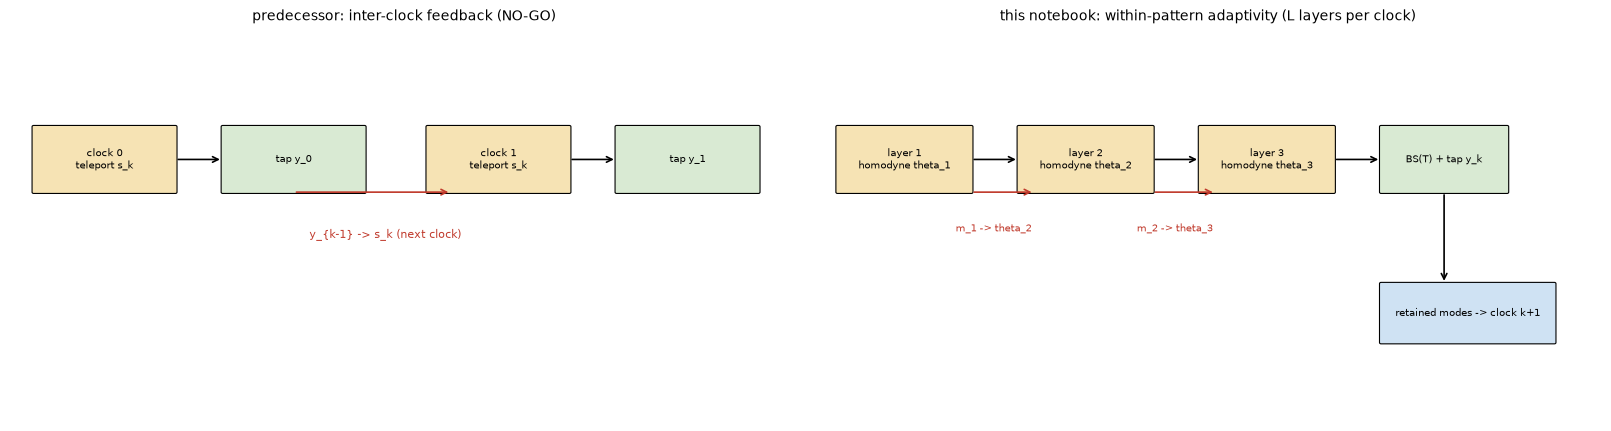

**Fig01_architectures.** Mode preflight. Left: the audited predecessor fed a tap outcome of clock k-1 into clock k. Right: the corrected clock, in which every outcome-to-basis edge (red) points to a later measurement of the same clock; the retained modes carry the recurrent state. Schematic, no data.

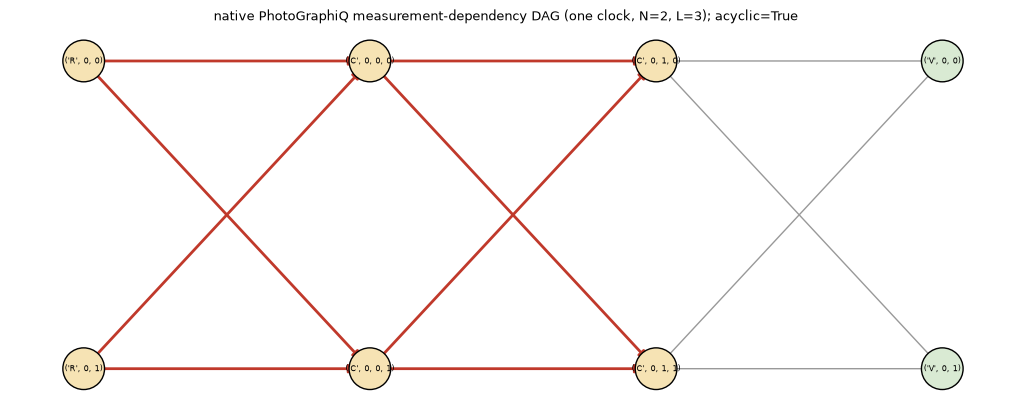

**Fig02_causal_dependency_graph.** Mode preflight. Measurement commands of one native clock pattern and their dependency closure (transitively reduced). Red: edges into measurements whose angle is an Outcome expression (adaptive). Grey: byproduct/quantum dependencies. Native data, no Monte Carlo.

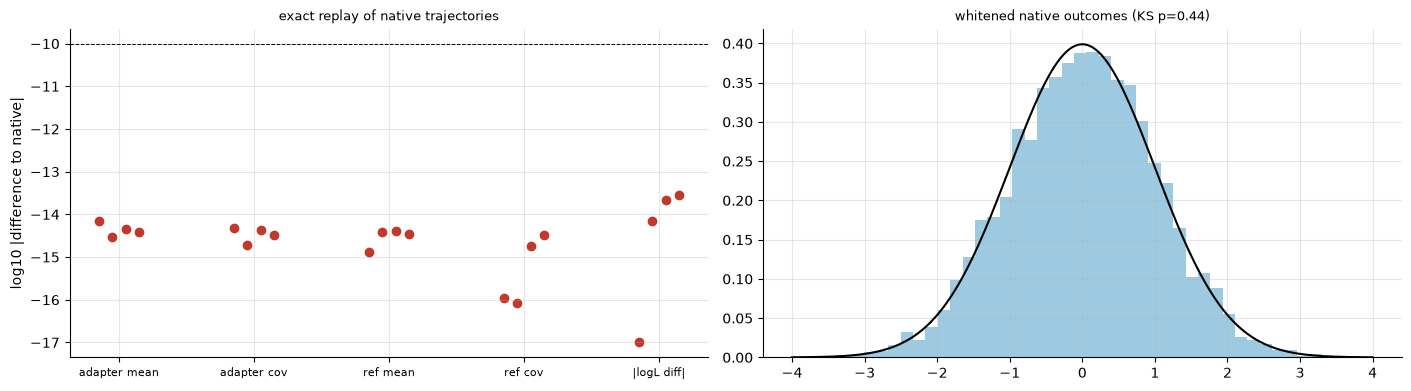

**Fig03_native_adapter_reference.** Mode preflight. Left: 4 replayed native trajectories (gaussian and piquasso backends; adaptive g, eta, loss, ff error); dashed: 1e-10 tolerance. Right: native teleportation outcomes from 400 adaptive trajectories, whitened by the adapter's exact predictive law, against N(0,1).

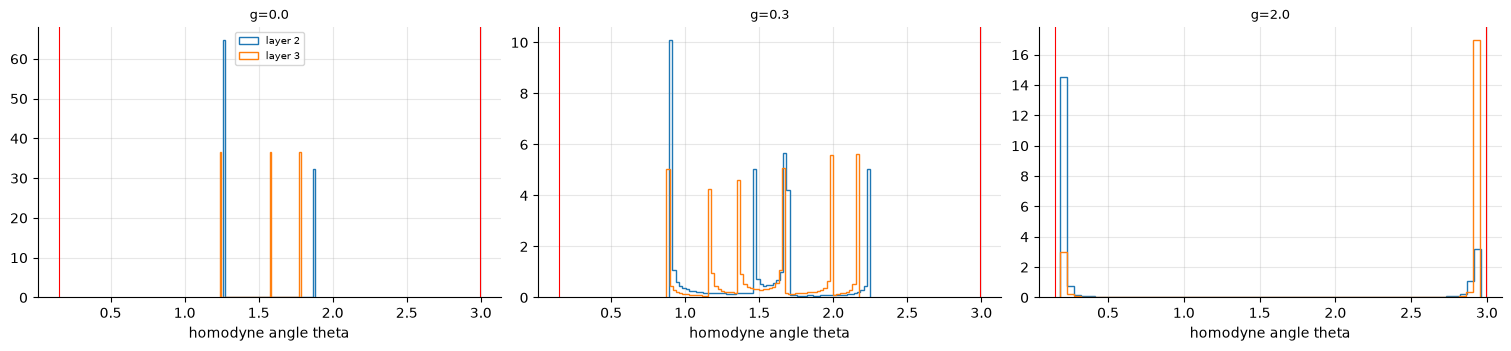

**Fig04_safe_angle_distributions.** Mode preflight; N=3, L=3, T=0.2; 256 trajectories x 160 clocks; red: safe bounds theta_min, pi - theta_min. At g=0 the later angles are the fixed baselines; large g pushes angles towards the bounds (large shears).

In [12]:
from matplotlib.patches import FancyBboxPatch
def _box(ax, x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec="k", lw=0.8)); ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=7)
def _arr(ax, a, b, color="k", ls="-"):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=color, lw=1.2, ls=ls))
fig, axs = plt.subplots(1, 2, figsize=(16, 4.2))
for ax in axs:
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
ax = axs[0]; ax.set_title("predecessor: inter-clock feedback (NO-GO)", fontsize=10)
for k, x0 in enumerate((0.3, 5.3)):
    _box(ax, x0, 3.5, 1.8, 1.0, f"clock {k}\nteleport s_k", "#f6e3b4"); _box(ax, x0 + 2.4, 3.5, 1.8, 1.0, f"tap y_{k}", "#d9ead3")
    _arr(ax, (x0 + 1.8, 4.0), (x0 + 2.4, 4.0))
_arr(ax, (3.6, 3.5), (5.6, 3.5), color=COL["AD"]); ax.text(3.8, 2.8, "y_{k-1} -> s_k (next clock)", color=COL["AD"], fontsize=8)
ax = axs[1]; ax.set_title("this notebook: within-pattern adaptivity (L layers per clock)", fontsize=10)
for j, x0 in enumerate((0.3, 2.6, 4.9)):
    _box(ax, x0, 3.5, 1.7, 1.0, f"layer {j + 1}\nhomodyne theta_{j + 1}", "#f6e3b4")
    if j:
        _arr(ax, (x0 - 0.6, 3.5), (x0 + 0.2, 3.5), color=COL["AD"]); ax.text(x0 - 0.8, 2.9, f"m_{j} -> theta_{j + 1}", color=COL["AD"], fontsize=7)
    _arr(ax, (x0 + 1.7, 4.0), (x0 + 2.3, 4.0))
_box(ax, 7.2, 3.5, 1.6, 1.0, "BS(T) + tap y_k", "#d9ead3"); _box(ax, 7.2, 1.2, 2.2, 0.9, "retained modes -> clock k+1", "#cfe2f3"); _arr(ax, (8.0, 3.5), (8.0, 2.1))
show_fig(fig, "Fig01_architectures", f"Mode {RUN_MODE}. Left: the audited predecessor fed a tap outcome of clock k-1 into clock k. Right: the corrected clock, in which every "
         "outcome-to-basis edge (red) points to a later measurement of the same clock; the retained modes carry the recurrent state. Schematic, no data.")

patd = native_clock_pattern(make_model(EXPLORATION_SEEDS[0], 2, CFG["L_depth"], 0.5), [0.3], 1.0); DG = patd.dependencies(); cmds = patd.commands
meas = [i for i, c in enumerate(cmds) if type(c).__name__ == "Measure"]
H_ = nx.DiGraph(); lab = {}
for i in meas:
    c = cmds[i]; H_.add_node(i); lab[i] = f"{c.node}"
for a, b in nx.transitive_closure_dag(DG).edges():
    if a in meas and b in meas:
        H_.add_edge(a, b)
H_ = nx.transitive_reduction(H_) if nx.is_directed_acyclic_graph(H_) else H_
adaptive_edges = [(a, b) for a, b in H_.edges() if getattr(cmds[b].measurement, "angle", 0.0) is not None and isinstance(cmds[b].measurement.angle, pg.expressions.Expr)]
fig, ax = plt.subplots(figsize=(10, 4))
layers = {i: len(nx.ancestors(H_, i)) for i in H_}; byl = {}
for i, l in layers.items():
    byl.setdefault(l, []).append(i)
pos = {i: (l, -k) for l, ids in byl.items() for k, i in enumerate(sorted(ids))}
nx.draw_networkx_nodes(H_, pos, node_color=["#d9ead3" if str(lab[i]).startswith("('V'") else "#f6e3b4" for i in H_], edgecolors="k", node_size=900, ax=ax)
nx.draw_networkx_edges(H_, pos, edgelist=[e for e in H_.edges() if e not in adaptive_edges], edge_color="#999", ax=ax, arrowsize=10)
nx.draw_networkx_edges(H_, pos, edgelist=adaptive_edges, edge_color=COL["AD"], width=2.0, ax=ax, arrowsize=12)
nx.draw_networkx_labels(H_, pos, labels={i: lab[i] for i in H_}, font_size=6, ax=ax); ax.axis("off")
ax.set_title(f"native PhotoGraphiQ measurement-dependency DAG (one clock, N=2, L={CFG['L_depth']}); acyclic={nx.is_directed_acyclic_graph(DG)}", fontsize=9)
show_fig(fig, "Fig02_causal_dependency_graph", f"Mode {RUN_MODE}. Measurement commands of one native clock pattern and their dependency closure (transitively reduced). Red: edges "
         "into measurements whose angle is an Outcome expression (adaptive). Grey: byproduct/quantum dependencies. Native data, no Monte Carlo.")

fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
errs = REPLAY_DF[["ad_mean", "ad_cov", "ref_mean", "ref_cov", "logL_diff"]].clip(lower=1e-17)
for j, col in enumerate(errs.columns):
    axs[0].scatter(np.full(len(errs), j) + np.linspace(-0.15, 0.15, len(errs)), np.log10(errs[col]), color=COL["AD"])
axs[0].axhline(-10, color="k", ls="--", lw=0.7); axs[0].set_xticks(range(len(errs.columns)), ["adapter mean", "adapter cov", "ref mean", "ref cov", "|logL diff|"], fontsize=8)
axs[0].set_ylabel("log10 |difference to native|"); axs[0].set_title("exact replay of native trajectories", fontsize=9)
axs[1].hist(Wn, bins=40, density=True, color="#9ecae1"); xg = np.linspace(-4, 4, 200); axs[1].plot(xg, sst.norm.pdf(xg), "k"); axs[1].set_title(f"whitened native outcomes (KS p={ks_p:.2f})", fontsize=9)
show_fig(fig, "Fig03_native_adapter_reference", f"Mode {RUN_MODE}. Left: {len(REPLAY_DF)} replayed native trajectories (gaussian and piquasso backends; adaptive g, eta, loss, ff "
         f"error); dashed: 1e-10 tolerance. Right: native teleportation outcomes from {CFG['native_shots']} adaptive trajectories, whitened by the adapter's exact predictive law, "
         "against N(0,1).")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4)); mS = make_model(EXPLORATION_SEEDS[0], CFG["N_main"], CFG["L_depth"], CFG["T_grid"][0])
for ax, g_ in zip(axs, (0.0, 0.3, 2.0)):
    mm = simulate(mS, input_sequence(4, 4, 200), g_, rng_for("angles", g_), 256, keep_m=True)["m"][40:]
    for j in range(1, mS.L):
        th = TH_MID + DTH * np.tanh(mS.z0[None, None, :, j - 1] + g_ * np.tanh(mm[:, :, j - 1] / mS.sigma[j - 1]))
        ax.hist(th.ravel(), bins=60, histtype="step", density=True, label=f"layer {j + 1}")
    ax.axvline(PREREGISTERED["theta_min"], color="r", lw=0.8); ax.axvline(np.pi - PREREGISTERED["theta_min"], color="r", lw=0.8); ax.set_title(f"g={g_}", fontsize=9)
    ax.set_xlabel("homodyne angle theta")
axs[0].legend(fontsize=7)
show_fig(fig, "Fig04_safe_angle_distributions", f"Mode {RUN_MODE}; N={CFG['N_main']}, L={CFG['L_depth']}, T={CFG['T_grid'][0]}; 256 trajectories x 160 clocks; red: safe bounds "
         "theta_min, pi - theta_min. At g=0 the later angles are the fixed baselines; large g pushes angles towards the bounds (large shears).")

## 9. Full Lyapunov spectra

Implementation of §6.5:
- **Exact Jacobian–vector products.** Each tangent copy is the complex state $\mathbf z+ih\mathbf v$ propagated through the real-analytic clock map, and $J\mathbf v=\mathrm{Im}(\cdot)/h$.
- **CI.** All $p$ copies of a path share its innovations $\boldsymbol\xi$; the sampled outcomes then carry tangent parts through $\boldsymbol\mu(\mathbf z)$ and $L(\mathbf z)$.
- **CR.** Outcomes are held at their real (recorded) values.
- **QR every `lyap_qr` clocks,** with a positive-diagonal sign convention; burn-in; block × path × realization uncertainty.
- **Validation:** the twelve tests of §9.2. The predecessor's scalar distance exponent is kept only as a consistency check on $\lambda_1$.

In [13]:
def vech(G, iu):
    return G[..., iu[0], iu[1]]

def unvech(v, n, iu, xp=np):
    M = xp.zeros(v.shape[:-1] + (n, n), dtype=v.dtype); M[..., iu[0], iu[1]] = v; M[..., iu[1], iu[0]] = v; return M

def qr_pos(Z, xp=np):
    Q, R = xp.linalg.qr(Z); sgn = xp.sign(xp.diagonal(R, axis1=-2, axis2=-1)); sgn = xp.where(sgn == 0, 1, sgn)
    return Q * sgn[..., None, :], R * sgn[..., :, None]

def lyap_generic(jvp, d, p, K, q=1, burn=0, seed=0):
    """Generic Benettin/QR spectrum for a JVP oracle jvp(k, V) = J_k V (V: d x p). Returns exponents (p,) per step."""
    rng = np.random.default_rng(seed); Q, _ = qr_pos(rng.normal(size=(d, p))); acc = np.zeros(p); n = 0
    for k in range(burn + K):
        Q = jvp(k, Q)
        if (k + 1) % q == 0:
            Q, R = qr_pos(Q)
            if k >= burn:
                acc += np.log(np.abs(np.diag(R)))
    return acc / K

def reservoir_spectrum(model, g, u, P, p, mode, q, burn, K, seed, xp=np, h=1e-30, init=None, nblocks=4):
    """Full (p = d) or partial CI / CR spectrum of the extended conditional state z = (r, vech Gamma) by complex-step QR.
    Returns dict(exp=(P_valid, p) per-path exponents, block=(P_valid, nblocks, p), escaped=int)."""
    Nt, L, n2 = model.N, model.L, 2 * model.N; iu = vech_idx(n2); d = n2 + len(iu[0]); p = d if p in ("all", None) else min(int(p), d)
    B = P * p; rng = rng_for("lyap-init", seed)
    Q = np.stack([qr_pos(rng.normal(size=(d, p)))[0] for _ in range(P)])                     # (P, d, p)
    r0 = np.zeros((P, n2)) if init is None else init[0]; G0 = np.broadcast_to(np.eye(n2), (P, n2, n2)) if init is None else init[1]
    def set_state(rre, Gre, Q):
        V = xp.asarray(np.transpose(Q, (0, 2, 1)).reshape(B, d))                              # copy (path, j) <- column j of Q[path]
        r = xp.asarray(np.repeat(rre, p, 0)) + 1j * h * V[:, :n2]
        G = xp.asarray(np.repeat(Gre, p, 0)) + 1j * h * unvech(V[:, n2:], n2, iu, xp)
        return r, G
    r, G = set_state(r0, np.asarray(G0), Q); zr = rng_for("lyap-z", seed)
    acc = np.zeros((P, p)); blocks = np.zeros((P, nblocks, p)); esc = np.zeros(P, bool); nacc = 0; bl_len = max(1, K // nblocks)
    for k in range(burn + K):
        xi_t = xp.asarray(np.repeat(zr.standard_normal((P, L, Nt)), p, 0)); xi_y = xp.asarray(np.repeat(zr.standard_normal((P, Nt)), p, 0))
        r, G, _ = clock(model, xp, r, G, float(u[k % len(u)]), g, xi_t, xi_y, mode=mode)
        bad = escaped_mask(xp, r, G).reshape(P, p).any(1); bad = bad if xp is np else xp.asnumpy(bad)
        if bad.any():
            esc |= bad
        if (k + 1) % q == 0:
            V = (G.imag if xp is np else xp.asnumpy(G.imag)); Vr = (r.imag if xp is np else xp.asnumpy(r.imag))
            Z = np.concatenate([Vr, vech(V, iu)], -1).reshape(P, p, d).transpose(0, 2, 1) / h
            Z = np.where(np.isfinite(Z), Z, 0.0)
            Qn, R = qr_pos(Z); lg = np.log(np.abs(np.diagonal(R, axis1=1, axis2=2)) + 1e-300)
            if k >= burn:
                acc += lg; bi = min(nblocks - 1, (k - burn) // bl_len); blocks[:, bi] += lg
            rre = (r.real if xp is np else xp.asnumpy(r.real)).reshape(P, p, n2)[:, 0]; Gre = (G.real if xp is np else xp.asnumpy(G.real)).reshape(P, p, n2, n2)[:, 0]
            rre = np.where(esc[:, None], 0.0, rre); Gre = np.where(esc[:, None, None], np.eye(n2), Gre)
            r, G = set_state(rre, Gre, Qn)
    ok = ~esc
    return dict(exp=acc[ok] / K, block=blocks[ok] / bl_len, escaped=int(esc.sum()), d=d, p=p)

def spectral_observables(lam, eps=0.05):
    lam = np.sort(np.asarray(lam))[::-1]; w = np.exp(-(lam / eps) ** 2)
    return dict(lambda1=float(lam[0]), lambda2=float(lam[1]) if len(lam) > 1 else np.nan, gap=float(lam[0] - lam[1]) if len(lam) > 1 else np.nan,
                N0=int((np.abs(lam) < eps).sum()), participation=float(w.sum() ** 2 / max((w ** 2).sum(), 1e-300)), pos_sum=float(lam[lam > 0].sum()))

def summarize_spectrum(sp):
    """Mean spectrum over valid paths with SE from block x path resampling."""
    if len(sp["exp"]) == 0:
        return None
    mean = np.sort(sp["exp"], 1)[:, ::-1].mean(0); bl = np.sort(sp["block"], 2)[:, :, ::-1].reshape(-1, sp["block"].shape[2])
    se = bl.std(0, ddof=1) / np.sqrt(len(bl)) if len(bl) > 1 else np.full_like(mean, np.nan)
    return dict(mean=mean, se=se, **spectral_observables(mean))

def exact_na_channel_spectrum(na, u, p, K, burn=50, q=1):
    """Exact unconditional NA channel spectrum on (r, vech M): (dr, dM) -> (X dr, X dM X^T)."""
    n2 = 2 * na.model.N; iu = vech_idx(n2); d = n2 + len(iu[0])
    def jvp(k, V):
        ds = na.model.alpha * u[k % len(u)]; X = na.XC0 + np.tensordot(ds, na.dXC, 1)
        dr = X @ V[:n2]; dM = unvech(V[n2:].T, n2, iu)
        return np.concatenate([dr, vech(X @ dM @ X.T, iu).T], 0)
    return np.sort(lyap_generic(jvp, d, min(p, d), K, q, burn))[::-1]

def ensemble_channel_spectrum(model, g, u, M, p0, K, seed, xp=np, h=1e-30):
    """Ensemble-tangent estimate of the leading unconditional-channel exponents for g != 0 (labelled; the ensemble does not close
    on Gaussian moments): path-averaged complex-step tangents of the ensemble moments (r, vech M) over a finite window; singular-value
    slopes fitted only while resolved above a 16-block jackknife Monte Carlo floor."""
    Nt, L, n2 = model.N, model.L, 2 * model.N; iu = vech_idx(n2); d = n2 + len(iu[0]); rng = rng_for("chan-init", seed)
    V0 = qr_pos(rng.normal(size=(d, p0)))[0]; B = M * p0
    r = xp.zeros((B, n2), complex) + 1j * h * xp.asarray(np.tile(V0[:n2].T, (M, 1)))
    G = xp.broadcast_to(xp.eye(n2, dtype=complex), (B, n2, n2)).copy() + 1j * h * unvech(xp.asarray(np.tile(V0[n2:].T, (M, 1))), n2, iu, xp)
    zr = rng_for("chan-z", seed); logscale = 0.0; S_hist, SE_hist = [], []
    for k in range(K):
        xi_t = xp.asarray(np.repeat(zr.standard_normal((M, L, Nt)), p0, 0)); xi_y = xp.asarray(np.repeat(zr.standard_normal((M, Nt)), p0, 0))
        r, G, _ = clock(model, xp, r, G, float(u[k]), g, xi_t, xi_y, mode="CI")
        Mm = G + r[:, :, None] * r[:, None, :]
        T_ = xp.concatenate([r.imag, vech(Mm.imag, iu)], -1).reshape(M, p0, d) / h       # per path, per direction
        T_ = T_ if xp is np else xp.asnumpy(T_)
        bm = T_.reshape(16, M // 16, p0, d).mean(1)                                       # (16, p0, d)
        A = bm.mean(0).T; s = np.linalg.svd(A, compute_uv=False)
        jk = np.array([np.linalg.svd(((bm.sum(0) - bm[j]) / 15).T, compute_uv=False) for j in range(16)])
        S_hist.append(np.log(s + 1e-300) + logscale); SE_hist.append(np.sqrt(15 / 16 * ((jk - jk.mean(0)) ** 2).sum(0)) / np.maximum(s, 1e-300))
        sc = float(np.abs(T_).max())
        if sc > 0:
            f = 1.0 / sc; r = r.real + 1j * r.imag * f; G = G.real + 1j * G.imag * f; logscale += math.log(sc)
    S_hist, SE_hist = np.array(S_hist), np.array(SE_hist); ks = np.arange(K); lam = []
    for i in range(p0):
        ok = (SE_hist[:, i] < 0.5) & np.isfinite(S_hist[:, i]); ok &= np.cumprod(ok | (ks < 1)).astype(bool)
        lam.append(float(np.polyfit(ks[ok], S_hist[ok, i], 1)[0]) if ok.sum() >= 4 else np.nan)
    return np.array(lam)

def purification_time(model, g, u, M, seed, K=None, xp=np, nbar=2.0):
    """Common-record purification: a thermal-initialized filter driven by the record of a vacuum-initialized trajectory; e-folding time of
    the conditional-entropy difference (fitted while above 1e-8)."""
    Nt, L, n2 = model.N, model.L, 2 * model.N; K = len(u) if K is None else K; zr = rng_for("purif", seed)
    rA, GA = xp.zeros((M, n2)), xp.broadcast_to(xp.eye(n2), (M, n2, n2)).copy(); rB, GB = rA.copy(), GA * (2 * nbar + 1)
    Om = np.kron(np.eye(Nt), np.array([[0, 1], [-1, 0]]))
    def entropy(Gm):
        nu = np.clip(np.sort(np.abs(np.linalg.eigvals(1j * Om @ Gm)), -1)[..., ::2], 1 + 1e-12, None); a_, b_ = (nu + 1) / 2, (nu - 1) / 2
        return (a_ * np.log(a_) - b_ * np.log(b_)).sum(-1)
    dS = []
    for k in range(K):
        xi_t, xi_y = xp.asarray(zr.standard_normal((M, L, Nt))), xp.asarray(zr.standard_normal((M, Nt)))
        rA, GA, oA = clock(model, xp, rA, GA, float(u[k]), g, xi_t, xi_y)
        hs = [oA["h"][:, j] for j in range(L)]
        rB, GB, _ = clock(model, xp, rB, GB, float(u[k]), g, h_given=hs, y_given=oA["y"])
        gA = GA if xp is np else xp.asnumpy(GA); gB = GB if xp is np else xp.asnumpy(GB)
        dS.append(float(np.abs(entropy(gB[:8]) - entropy(gA[:8])).mean()))
    dS = np.array(dS); ks = np.arange(K); ok = dS > 1e-8; ok &= np.cumprod(ok).astype(bool)
    if ok.sum() < 3:
        return float(max(1, ok.sum()))
    sl = np.polyfit(ks[ok], np.log(dS[ok]), 1)[0]
    return float(-1 / sl) if sl < 0 else np.inf

### 9.2 Validation of the spectrum implementation

In [14]:
with section("9.2 Lyapunov validation"):
    rng = rng_for("lyap-tests")
    a = np.array([0.3, -0.1, -0.7, -1.4]); e_l1 = np.abs(np.sort(lyap_generic(lambda k, V: np.diag(np.exp(a)) @ V, 4, 4, 2000, burn=200))[::-1] - np.sort(a)[::-1]).max()
    record_test("L1", "spectrum", "constant linear map diag(e^a): QR exponents = a (burn 200, K 2000)", e_l1, "< 1e-3", e_l1 < 1e-3)
    A1 = rng.normal(size=(3, 3)) * 0.6; A2 = np.array([[0.5, 2.0], [0.0, 0.3]]); Ab = sla.block_diag(A1, A2)
    known = np.sort(np.log(np.abs(np.r_[np.linalg.eigvals(A1), np.linalg.eigvals(A2)])))[::-1]
    est = np.sort(lyap_generic(lambda k, V: Ab @ V, 5, 5, 4000))[::-1]; e_l2 = np.abs(est - known).max()
    record_test("L2", "spectrum", "block-diagonal constant map: full spectrum = log|eigenvalues| (non-normal block included)", e_l2, "< 5e-3", e_l2 < 5e-3)
    aa = rng.uniform(0.2, 0.9, 20000); ex3 = (0.9 * np.log(0.9) - 0.9 - (0.2 * np.log(0.2) - 0.2)) / 0.7
    e_l3 = abs(lyap_generic(lambda k, V: aa[k] * V, 1, 1, 20000)[0] - ex3)
    bb = rng.uniform(1.1, 2.0, 20000); ex4 = (2 * np.log(2) - 2 - (1.1 * np.log(1.1) - 1.1)) / 0.9
    e_l4 = abs(lyap_generic(lambda k, V: bb[k] * V, 1, 1, 20000)[0] - ex4)
    record_test("L3", "spectrum", "contractive stochastic map a_k ~ U(0.2,0.9): exponent = E log a (analytic)", e_l3, "< 0.01", e_l3 < 0.01)
    record_test("L4", "spectrum", "unstable stochastic map a_k ~ U(1.1,2.0): exponent = E log a > 0 (analytic)", e_l4, "< 0.01", e_l4 < 0.01)
    # reservoir Jacobian: complex step vs finite differences (CI, one clock, same innovations)
    Nv, Lv, Tv = 2, CFG["L_depth"], 0.5; SIGMA.setdefault((Nv, Lv, round(Tv, 9)), np.full(Lv - 1, 3.0))
    mv = make_model(EXPLORATION_SEEDS[2], Nv, Lv, Tv); n2v = 2 * Nv; iuv = vech_idx(n2v); dv = n2v + len(iuv[0])
    r0 = rng.normal(size=(1, n2v)) * 0.3; G0 = (lambda Q: Q @ Q.T)(rng.normal(size=(n2v, n2v)) * 0.5)[None] + np.eye(n2v)[None]
    xt, xy = rng.normal(size=(1, Lv, Nv)), rng.normal(size=(1, Nv))
    def Fz(zz, cplx=False):
        rr = zz[:, :n2v]; GG = unvech(zz[:, n2v:], n2v, iuv); rr2, GG2, _ = clock(mv, np, rr, GG, 0.37, 1.5, np.repeat(xt, len(zz), 0), np.repeat(xy, len(zz), 0))
        return np.concatenate([rr2, vech(GG2, iuv)], -1)
    z0 = np.concatenate([r0, vech(G0, iuv)], -1); hstep = 1e-30
    Jc = (Fz(z0 + 1j * hstep * np.eye(dv)).imag / hstep).T
    hf = 1e-6; Jf = ((Fz(z0 + hf * np.eye(dv)) - Fz(z0 - hf * np.eye(dv))) / (2 * hf)).T
    e_l5 = np.abs(Jc - Jf).max() / np.abs(Jc).max()
    record_test("L5", "spectrum", "exact complex-step Jacobian of the adaptive clock map (CI, g=1.5) vs central finite differences", e_l5, "< 1e-6", e_l5 < 1e-6)
    # explicit Jacobian sequence of the reservoir (CI) for basis/SVD/QR-interval tests
    uv = input_sequence(5, 0, 300); Js = []; zz = z0.copy(); zr_ = rng_for("jseq")
    for k in range(60):
        xt_, xy_ = zr_.normal(size=(1, Lv, Nv)), zr_.normal(size=(1, Nv))
        def Fk(z_):
            rr = z_[:, :n2v]; GG = unvech(z_[:, n2v:], n2v, iuv); rr2, GG2, _ = clock(mv, np, rr, GG, float(uv[k]), 0.25, np.repeat(xt_, len(z_), 0), np.repeat(xy_, len(z_), 0))
            return np.concatenate([rr2, vech(GG2, iuv)], -1)
        Js.append((Fk(zz + 1j * hstep * np.eye(dv)).imag / hstep).T); zz = Fk(zz).real
    Rb = rng.normal(size=(dv, dv)) + 3 * np.eye(dv); Rbi = np.linalg.inv(Rb)
    s1 = np.sort(lyap_generic(lambda k, V: Js[k] @ V, dv, dv, 60, burn=0))[::-1]
    s2 = np.sort(lyap_generic(lambda k, V: Rb @ Js[k] @ Rbi @ V, dv, dv, 60, burn=0))[::-1]
    e_l6 = abs(s1.sum() - s2.sum()) + abs(s1[0] - s2[0])
    record_test("L6", "spectrum", "basis invariance (random linear change of coordinates): sum and top exponent over 60 clocks", e_l6, "< 0.1", e_l6 < 0.1)
    s5 = np.sort(lyap_generic(lambda k, V: Js[k] @ V, dv, dv, 60, q=2))[::-1]; e_l7 = np.abs(s1 - s5).max()
    record_test("L7", "spectrum", "QR-interval invariance (q=1 vs q=2, same Jacobians)", e_l7, "< 1e-5", e_l7 < 1e-5)
    Ks = 8; Pr = np.eye(dv)
    for J_ in Js[:Ks]:
        Pr = J_ @ Pr
    s8 = np.sort(lyap_generic(lambda k, V: Js[k] @ V, dv, dv, Ks))[::-1]; sv = np.log(np.linalg.svd(Pr, compute_uv=False)) / Ks; ld = np.linalg.slogdet(Pr)[1]
    e_sum, e_top = abs(s8.sum() - ld / Ks), abs(s8[0] - sv[0])
    record_test("L12", "spectrum", f"short-time ({Ks} clocks) QR vs direct singular values: sum of exponents = log|det|/K exactly; top within O(1/K)",
                f"sum {e_sum:.1e}, top {e_top:.3f}", "sum < 1e-8, top < 0.3", e_sum < 1e-8 and e_top < 0.3)
    # convergence tests on the reservoir spectrum itself (CI and CR)
    base_kw = dict(model=mv, g=0.25, u=uv, P=4, p="all", q=CFG["lyap_qr"], seed=1)
    spA = summarize_spectrum(reservoir_spectrum(mode="CI", burn=50, K=200, **base_kw)); spB = summarize_spectrum(reservoir_spectrum(mode="CI", burn=150, K=200, **base_kw))
    spC = summarize_spectrum(reservoir_spectrum(mode="CI", burn=50, K=400, **base_kw))
    spD = summarize_spectrum(reservoir_spectrum(mode="CI", burn=50, K=200, **dict(base_kw, P=8, seed=2)))
    tol = lambda s_, t_: abs(s_["lambda1"] - t_["lambda1"]) < 4 * max(s_["se"][0], t_["se"][0]) + 0.02
    record_test("L8", "spectrum", "burn-in convergence of lambda_1^CI (50 vs 150 clocks)", abs(spA["lambda1"] - spB["lambda1"]), "< 4 SE + 0.02", tol(spA, spB), critical=False)
    record_test("L9", "spectrum", "trajectory-length convergence of lambda_1^CI (200 vs 400 clocks)", abs(spA["lambda1"] - spC["lambda1"]), "< 4 SE + 0.02", tol(spA, spC), critical=False)
    record_test("L10", "spectrum", "trajectory-count convergence of lambda_1^CI (4 vs 8 paths, new seed)", abs(spA["lambda1"] - spD["lambda1"]), "< 4 SE + 0.02", tol(spA, spD), critical=False)
    if CUPY_OK:
        spG = reservoir_spectrum(mode="CR", burn=20, K=60, xp=cp, **dict(base_kw, P=2)); spN = reservoir_spectrum(mode="CR", burn=20, K=60, **dict(base_kw, P=2))
        e_l11 = float(np.abs(spG["exp"] - spN["exp"]).max())
        record_test("L11", "spectrum", "CPU/GPU agreement of the CR spectrum", e_l11, "< 1e-8", e_l11 < 1e-8)
    else:
        record_test("L11", "spectrum", "CPU/GPU agreement of the spectrum", "no usable GPU", "n/a", True, critical=False)
    # scalar consistency check: two-copy Benettin distance (common innovation) vs lambda_1^CI
    def scalar_ci(model, g, u, M, seed, K, burn, d0=1e-7):
        zr = rng_for("scalar", seed); n2 = 2 * model.N; iu = vech_idx(n2)
        rA = np.zeros((M, n2)); GA = np.broadcast_to(np.eye(n2), (M, n2, n2)).copy(); v = rng_for("sdir", seed).normal(size=n2); v /= np.linalg.norm(v)
        rB = rA + d0 * v; GB = GA.copy(); logs = []
        for k in range(burn + K):
            xt_, xy_ = zr.standard_normal((M, model.L, model.N)), zr.standard_normal((M, model.N))
            rA, GA, _ = clock(model, np, rA, GA, float(u[k % len(u)]), g, xt_, xy_); rB, GB, _ = clock(model, np, rB, GB, float(u[k % len(u)]), g, xt_, xy_)
            dz = np.sqrt(((rB - rA) ** 2).sum(1) + ((vech(GB, iu) - vech(GA, iu)) ** 2).sum(1)); dz = np.maximum(dz, 1e-300)
            if k >= burn:
                logs.append(np.log(dz / d0))
            rB = rA + (rB - rA) * (d0 / dz)[:, None]; GB = GA + (GB - GA) * (d0 / dz)[:, None, None]
        return float(np.mean(logs))
    lam_sc = scalar_ci(mv, 0.25, uv, 8, 3, 200, 50)
    record_test("L13", "spectrum", "consistency: predecessor-style scalar common-innovation exponent vs lambda_1^CI", f"{lam_sc:.4f} vs {spA['lambda1']:.4f}",
                "|diff| < 4 SE + 0.05", abs(lam_sc - spA["lambda1"]) < 4 * spA["se"][0] + 0.05, critical=False)
    print("example spectra (N=2, g=0.25): CI", np.round(spA["mean"], 3))
    spR = summarize_spectrum(reservoir_spectrum(mode="CR", burn=50, K=200, **base_kw)); print("                         CR", np.round(spR["mean"], 3))
    LYAP_VALID = all(t["passed"] for t in TESTS if t["category"] == "spectrum" and t["critical"])

PASS [L1] (critical) constant linear map diag(e^a): QR exponents = a (burn 200, K 2000): 5.2e-14 (criterion < 1e-3)
PASS [L2] (critical) block-diagonal constant map: full spectrum = log|eigenvalues| (non-normal block included): 0.000463 (criterion < 5e-3)


PASS [L3] (critical) contractive stochastic map a_k ~ U(0.2,0.9): exponent = E log a (analytic): 0.00114 (criterion < 0.01)
PASS [L4] (critical) unstable stochastic map a_k ~ U(1.1,2.0): exponent = E log a > 0 (analytic): 0.000258 (criterion < 0.01)
PASS [L5] (critical) exact complex-step Jacobian of the adaptive clock map (CI, g=1.5) vs central finite differences: 4.87e-10 (criterion < 1e-6)
PASS [L6] (critical) basis invariance (random linear change of coordinates): sum and top exponent over 60 clocks: 0.0151 (criterion < 0.1)
PASS [L7] (critical) QR-interval invariance (q=1 vs q=2, same Jacobians): 4.44e-16 (criterion < 1e-5)
PASS [L12] (critical) short-time (8 clocks) QR vs direct singular values: sum of exponents = log|det|/K exactly; top within O(1/K): sum 1.1e-14, top 0.117 (criterion sum < 1e-8, top < 0.3)


PASS [L8] burn-in convergence of lambda_1^CI (50 vs 150 clocks): 0.0161 (criterion < 4 SE + 0.02)
PASS [L9] trajectory-length convergence of lambda_1^CI (200 vs 400 clocks): 0.000113 (criterion < 4 SE + 0.02)
PASS [L10] trajectory-count convergence of lambda_1^CI (4 vs 8 paths, new seed): 0.00701 (criterion < 4 SE + 0.02)


PASS [L11] (critical) CPU/GPU agreement of the CR spectrum: 2.22e-15 (criterion < 1e-8)
PASS [L13] consistency: predecessor-style scalar common-innovation exponent vs lambda_1^CI: -0.2724 vs -0.2616 (criterion |diff| < 4 SE + 0.05)
example spectra (N=2, g=0.25): CI [-0.262 -0.301 -0.397 -0.44  -1.003 -1.011 -1.018 -1.036 -1.041 -1.045
 -1.05  -1.061 -1.069 -1.081]


                         CR [-0.508 -0.51  -0.533 -0.535 -1.015 -1.018 -1.019 -1.04  -1.042 -1.043
 -1.047 -1.066 -1.068 -1.069]
[9.2 Lyapunov validation] 4.5 s | peak RSS 1165 MB


## 10. Kernels and susceptibilities

Estimators:
1. **Cauchy contour** (analytic differentiation by running the engines on complex inputs). Used only where analyticity in $u$ is established, i.e. the exact NA and CV maps.
2. **Pathwise central finite differences with common random numbers** (all three models). Validated by step convergence, trajectory convergence and the $g=0$ null.
3. **IPC regression** (Legendre capacities), the operational cross-check at the locked point (§12).

The squared norms use U-statistics over 16 independent path blocks. The raw value, the constrained value $\max(0,\cdot)$ and a jackknife SE are all reported.

In [15]:
STENCIL = {0: {0: 1.0}, 1: {-1: -0.5, 1: 0.5}, 2: {-1: 1.0, 0: -2.0, 1: 1.0}, 3: {-2: -0.5, -1: 1.0, 1: -1.0, 2: 0.5},
           4: {-2: 1.0, -1: -4.0, 0: 6.0, 1: -4.0, 2: 1.0}}
D_WIT = PREREGISTERED["witness_max_delay"]
KSTAR = [(tc, tl) for tc in range(D_WIT + 1) for tl in range(D_WIT + 1) if tl != tc]

def stencil_points(K, a, p, b, q, h):
    pts, wts = [], []
    if a == b:
        for i, w in STENCIL[p + q].items():
            u = np.zeros(K); u[K - 1 - a] = i * h; pts.append(u); wts.append(w)
        return np.stack(pts, 1), np.array(wts) / (h ** (p + q) * math.factorial(p + q))
    for i, wi in STENCIL[p].items():
        for j, wj in STENCIL[q].items():
            u = np.zeros(K); u[K - 1 - a] = i * h; u[K - 1 - b] = j * h; pts.append(u); wts.append(wi * wj)
    return np.stack(pts, 1), np.array(wts) / (h ** (p + q) * math.factorial(p) * math.factorial(q))

def cauchy_coeff(fun, K, a, p, b, q, rho=0.3, n=12):
    th = 2 * np.pi * np.arange(n) / n; z = rho * np.exp(1j * th)
    if a == b:
        U = np.zeros((K, n), complex); U[K - 1 - a] = z
        return (np.exp(-1j * (p + q) * th) @ np.asarray(fun(U))).real / n / rho ** (p + q)
    U = np.zeros((K, n * n), complex); U[K - 1 - a] = np.repeat(z, n); U[K - 1 - b] = np.tile(z, n)
    ph = np.exp(-1j * (p * np.repeat(th, n) + q * np.tile(th, n)))
    return (ph @ np.asarray(fun(U))).real / n ** 2 / rho ** (p + q)

def xx_map(N):
    """Indices of the xx entries of vech over (x1,p1,...) in the order of the visible features triu(N)."""
    iu_int = vech_idx(2 * N); pos = {(int(a), int(b)): k for k, (a, b) in enumerate(zip(*iu_int))}
    return np.array([pos[(2 * i, 2 * j)] for i, j in zip(*np.triu_indices(N))])

def kernel_blocks(model, g, comp, M, seed, K, h, xp=np, n_blocks=16, **ctrl):
    """Pathwise CRN finite-difference Volterra coefficients c^{(p,q)}_{a,b} of the internal coordinate (vech of the post-wire
    second-moment matrix) and of the visible features. Returns dict(int=(n_blocks, n_int), vis=(n_blocks, F), n_bad) or None."""
    a, p, b, q = comp; U, w = stencil_points(K, a, p, b, q, h); P = U.shape[1]
    out = simulate(model, np.repeat(U, M, axis=1), g, rng_for("kernel", seed), M, xp=xp, tile=P, final_per_path=True, final_internal=True, **ctrl)
    fin = out["final"]; ok = (fin["ok"] if xp is np else xp.asnumpy(fin["ok"])).reshape(P, M).all(0)
    if ok.sum() < n_blocks * 2:
        return None
    to = lambda a_: (a_ if xp is np else xp.asnumpy(a_)).real
    inn = to(fin["internal"])[:, model.iu_int[0], model.iu_int[1]].reshape(P, M, -1); vis = to(fin["rb"]).reshape(P, M, -1)
    ci, cv = np.tensordot(w, inn, 1)[ok], np.tensordot(w, vis, 1)[ok]
    m_ = (len(ci) // n_blocks) * n_blocks
    return dict(int=ci[:m_].reshape(n_blocks, -1, ci.shape[1]).mean(1), vis=cv[:m_].reshape(n_blocks, -1, cv.shape[1]).mean(1), n_bad=int((~ok).sum()))

def ustat(blocks, W=None):
    """Unbiased U-statistic for sum_c ||c||_W^2 over independent blocks; jackknife SE. blocks: (C, nb, dim)."""
    Kb = np.asarray(blocks); C, nb, _ = Kb.shape
    Wm = np.eye(Kb.shape[2]) if W is None else W
    S = Kb.sum(1); Q = np.einsum("cbi,ij,cbj->", Kb, Wm, Kb)
    total = np.einsum("ci,ij,cj->", S, Wm, S)
    est = (total - Q) / (nb * (nb - 1))
    jk = []
    for j in range(nb):
        Sj = S - Kb[:, j]; Qj = Q - np.einsum("ci,ij,cj->", Kb[:, j], Wm, Kb[:, j])
        jk.append((np.einsum("ci,ij,cj->", Sj, Wm, Sj) - Qj) / ((nb - 1) * (nb - 2)))
    jk = np.array(jk); se = float(np.sqrt((nb - 1) / nb * ((jk - jk.mean()) ** 2).sum()))
    return float(est), se

def noise_covariance(model, g, M, seed, K, S, xp=np, n_draw=4):
    """Covariance of the finite-shot feature estimator (S shots) at a fixed input history (u = 0), from repeated trajectories:
    single-shot product vectors from the per-path conditional tap law, pooled over paths, divided by S."""
    out = simulate(model, np.zeros(K), g, rng_for("noise", seed), M, xp=xp, final_per_path=True)
    fin = out["final"]; to = lambda a_: (a_ if xp is np else xp.asnumpy(a_)).real
    Sy, ym, ok = to(fin["Sy"]), to(fin["ym"]), (fin["ok"] if xp is np else xp.asnumpy(fin["ok"]))
    Sy, ym = Sy[ok], ym[ok]; Lc = np.linalg.cholesky(Sy); zz = rng_for("noise-draw", seed).standard_normal((n_draw, len(Sy), model.N))
    y = ym[None] + np.einsum("bij,dbj->dbi", Lc, zz); iu = model.iu
    qv = (y[..., iu[0]] * y[..., iu[1]]).reshape(-1, len(iu[0]))
    return np.cov(qv.T) / S

def feature_covariance(model, g, seed, M, K, xp=np):
    out = simulate(model, input_sequence(seed, 77, K), g, rng_for("fcov", seed), M, xp=xp)
    X = out["rb"][min(100, K // 4):]
    return np.cov(X[np.isfinite(X).all(1)].T)

def susceptibilities(model, g, rid, M, K, h, xp=np, S=None, ctrl=None, comps=None):
    """chi_int, chi_vis, chi_vis^wh (with epsilon sensitivity) and chi_res at one structural point."""
    ctrl = ctrl or {}; comps = KSTAR if comps is None else comps; S = CFG["shots_primary"] if S is None else S
    blk = []
    for (tc, tl) in comps:
        bk = kernel_blocks(model, g, (tc, 3, tl, 1), M, ("kern", rid, model.N, model.T, g, tc, tl), K, h, xp=xp, **ctrl)
        if bk is None:
            return dict(failed=True, reason="too many escaped paths in the kernel batch")
        blk.append(bk)
    Bi, Bv = np.stack([b["int"] for b in blk]), np.stack([b["vis"] for b in blk])
    xm = xx_map(model.N_read) if model.N == model.N_read else xx_map(model.N)[:len(model.iu[0])]
    bmeas_err = float(np.abs(Bv - (1 - model.T) * Bi[:, :, xm]).max() / max(np.abs(Bv).max(), 1e-300)) if model.N == model.N_read else np.nan
    Sig = noise_covariance(model, g, CFG["noise_samples"], ("noise", rid, model.N, model.T, g), K, S, xp=xp)
    eps0 = PREREGISTERED["whitening_eps_rel"] * np.trace(Sig) / len(Sig)
    Wf = lambda e: np.linalg.inv(Sig + e * np.eye(len(Sig)))
    Cx = feature_covariance(model, g, rid, CFG["res_paths"], CFG["res_clocks"], xp=xp); ev, V = np.linalg.eigh(Cx)
    lamR = PREREGISTERED["ridge_struct_rel"] * ev.mean(); rr = (ev / (ev + lamR)) ** 2; Wres = V @ np.diag(rr) @ V.T
    res = dict(chi_int=ustat(Bi), chi_vis=ustat(Bv), chi_wh=ustat(Bv, Wf(eps0)), chi_wh_eps_lo=ustat(Bv, Wf(eps0 * 0.01))[0],
               chi_wh_eps_hi=ustat(Bv, Wf(eps0 * 100))[0], chi_res=ustat(Bv, Wres), bmeas_err=bmeas_err,
               comp_vis=[float(np.linalg.norm(b.mean(0))) for b in Bv], comp_int=[float(np.linalg.norm(b.mean(0))) for b in Bi],
               n_bad=int(sum(b["n_bad"] for b in blk)), noise_trace=float(np.trace(Sig)))
    return res

### 10.1 Exact zeros (Theorems 1, 2 and Corollary 2a) and estimator validation

In [16]:
with section("10.1 kernel-rule validation"):
    rng = rng_for("kern-tests"); Kk = CFG["kernel_clocks"]; worst_na = worst_cv = worst_fixed = 0.0; agree = 0.0; rows = []
    Lm = CFG["L_depth"]
    for N_ in sorted({2, CFG["N_main"]}):
        for T_ in (min(CFG["T_grid"]), max(CFG["T_grid"])):
            for cname, cd in {"base": BASE, "lossy": cond_of(squeezing_db=9.0, loop_transmissivity=0.9, detector_efficiency=0.9, feedforward_gain_error=0.02)}.items():
                mdl = make_model(EXPLORATION_SEEDS[0], N_, Lm, T_, cd); na = NAExact(mdl)
                for lab, fun in (("vis", lambda U, na=na: na.features(U, final_only=True)), ("int", lambda U, na=na: na.features(U, internal=True, final_only=True)[1])):
                    allowed = max(np.abs(cauchy_coeff(fun, Kk, a, 2, b, 1)).max() for a, b in [(1, 0), (0, 1), (2, 1)])
                    forbid = max([np.abs(cauchy_coeff(fun, Kk, tc, 3, tl, 1)).max() for tc, tl in KSTAR] + [np.abs(cauchy_coeff(fun, Kk, a, 3, a, 0)).max() for a in range(3)])
                    worst_na = max(worst_na, forbid / allowed); rows.append(dict(N=N_, T=T_, cond=cname, coord=lab, forbidden_over_allowed=forbid / allowed))
                cv = make_cv(EXPLORATION_SEEDS[0], N_, T_, cd); fcv = lambda U, cv=cv: cv.exact(U, final_only=True)
                al_cv = max(np.abs(cauchy_coeff(fcv, Kk, a, 3, a, 0)).max() for a in range(3))
                fb_cv = max([np.abs(cauchy_coeff(fcv, Kk, a, 1, b, 1)).max() for a, b in [(0, 1), (1, 2)]] + [np.abs(cauchy_coeff(fcv, Kk, tc, 3, tl, 1)).max() for tc, tl in KSTAR])
                worst_cv = max(worst_cv, fb_cv / al_cv)
        # Corollary 2a: other FIXED later-layer bases (random redraws) keep the zeros exactly
        for rep in range(3):
            m0 = make_model(EXPLORATION_SEEDS[0], N_, Lm, 0.5); mf = copy.copy(m0); mf.beta_later = rng.uniform(-1.5, 1.5, m0.beta_later.shape)
            mf.theta0 = np.arctan2(1.0, mf.beta_later); mf.z0 = np.arctanh((mf.theta0 - TH_MID) / DTH); mf._dev = {}
            naf = NAExact(mf); funf = lambda U, naf=naf: naf.features(U, final_only=True)
            al = max(np.abs(cauchy_coeff(funf, Kk, a, 2, b, 1)).max() for a, b in [(1, 0), (0, 1)])
            fb = max(np.abs(cauchy_coeff(funf, Kk, tc, 3, tl, 1)).max() for tc, tl in KSTAR); worst_fixed = max(worst_fixed, fb / al)
        mdl = make_model(EXPLORATION_SEEDS[0], N_, Lm, 0.5); na = NAExact(mdl); fun = lambda U: na.features(U, final_only=True)
        c_fd, c_ca = (np.tensordot(stencil_points(Kk, 1, 2, 0, 1, 0.05)[1], np.asarray(fun(stencil_points(Kk, 1, 2, 0, 1, 0.05)[0])).real, 1),
                      cauchy_coeff(fun, Kk, 1, 2, 0, 1))
        agree = max(agree, np.abs(c_fd - c_ca).max() / np.abs(c_ca).max())
    ZERO_DF = pd.DataFrame(rows); display(ZERO_DF.groupby(["coord", "cond"]).forbidden_over_allowed.max().to_frame())
    tol = PREREGISTERED["zero_tol_rel"]
    record_test("K1", "physics", "Theorem 2 on the native layered channel: K* and single-delay-cubic coefficients vanish (internal AND visible; loss, eta, ff, 9 dB)",
                worst_na, f"< {tol:g}", worst_na < tol)
    record_test("K2", "physics", "Theorem 1 on the CV engine: cross-delay coefficients vanish", worst_cv, f"< {tol:g}", worst_cv < tol)
    record_test("K3", "physics", "Corollary 2a: any other FIXED nonadaptive later-layer basis also has exactly zero K* (3 random bases per size)", worst_fixed,
                f"< {tol:g}", worst_fixed < tol)
    record_test("K4", "numerical", "finite differences vs Cauchy contour on an allowed NA coefficient (c21, exact multi-quadratic; FD round-off ~ eps/h^3)", agree, "< 1e-6", agree < 1e-6)
    STRUCT_ZERO_OK = worst_na < tol and worst_cv < tol and worst_fixed < tol
    # Monte Carlo estimator validation on the adaptive engine (stable small gain) ------------------------------------------------
    Nv, Tv = CFG["N_main"], 0.4; SIGMA.setdefault((Nv, Lm, round(Tv, 9)), np.full(Lm - 1, 4.5)); mv = make_model(EXPLORATION_SEEDS[1], Nv, Lm, Tv)
    Mk = max(256, CFG["kernel_paths"] // 2); steps = {}
    for hh in (0.2, 0.1, 0.05):
        steps[hh] = kernel_blocks(mv, 0.2, (1, 3, 0, 1), Mk, "step", Kk, hh)["int"].mean(0)
    d1, d2 = np.abs(steps[0.2] - steps[0.1]).max(), np.abs(steps[0.1] - steps[0.05]).max()
    record_test("K5", "numerical", "FD step convergence of the pathwise AD internal kernel (successive-difference ratio; O(h^2) -> 4)", d1 / max(d2, 1e-300), "> 2.5",
                d1 / max(d2, 1e-300) > 2.5, critical=False)
    s_small = kernel_blocks(mv, 0.2, (1, 3, 0, 1), 256, "conv", Kk, 0.1)["vis"].std(0).mean(); s_big = kernel_blocks(mv, 0.2, (1, 3, 0, 1), 1024, "conv2", Kk, 0.1)["vis"].std(0).mean()
    record_test("K6", "numerical", "trajectory convergence: block-mean spread ratio for 4x more paths (expect 2)", s_small / s_big, "in [1.3, 2.9]", 1.3 <= s_small / s_big <= 2.9,
                critical=False)
    null = susceptibilities(mv, 0.0, 1, Mk, Kk, 0.1, comps=KSTAR[:3])
    zn = null["chi_wh"][0] / null["chi_wh"][1] if null["chi_wh"][1] > 0 else 0.0
    record_test("K7", "statistical", "null calibration at g=0: Monte Carlo chi_vis^wh consistent with the exact zero (|z|)", abs(zn), "< 3", abs(zn) < 3)
    record_test("K8", "physics", "measurement map is exactly linear: K^vis = (1-T) [H]_xx per path (relative error; FD round-off)", null["bmeas_err"], "< 1e-8", null["bmeas_err"] < 1e-8)
    Kseq = Kk + 10                                     # independent and input-independent random angles keep the zero (Corollary 2a, stochastic part)
    rngA = rng_for("iid-angles")
    def iid_theta(k, j, _cache={}):
        key = (k, j)
        if key not in _cache:
            _cache[key] = rngA.uniform(PREREGISTERED["theta_min"] + 0.2, np.pi - PREREGISTERED["theta_min"] - 0.2, (Mk, mv.N))
        return np.tile(_cache[key], (8, 1))
    iid = susceptibilities(mv, 0.2, 2, Mk, Kk, 0.1, comps=KSTAR[:3], ctrl=dict(theta_override=iid_theta))
    zi = iid["chi_wh"][0] / iid["chi_wh"][1] if iid["chi_wh"][1] > 0 else 0.0
    record_test("K9", "physics", "Corollary 2a (stochastic): i.i.d. input-independent later-layer angles keep chi_vis^wh at zero (|z|)", abs(zi), "< 3", abs(zi) < 3)

forbidden_over_allowed
coord cond                         
int   base             1.154601e-10
      lossy            1.400109e-10
vis   base             2.937740e-10
      lossy            2.654977e-10

PASS [K1] (critical) Theorem 2 on the native layered channel: K* and single-delay-cubic coefficients vanish (internal AND visible; loss, eta, ff, 9 dB): 2.94e-10 (criterion < 1e-09)
PASS [K2] (critical) Theorem 1 on the CV engine: cross-delay coefficients vanish: 1.23e-14 (criterion < 1e-09)
PASS [K3] (critical) Corollary 2a: any other FIXED nonadaptive later-layer basis also has exactly zero K* (3 random bases per size): 1.11e-11 (criterion < 1e-09)
PASS [K4] (critical) finite differences vs Cauchy contour on an allowed NA coefficient (c21, exact multi-quadratic; FD round-off ~ eps/h^3): 1.08e-08 (criterion < 1e-6)


PASS [K5] FD step convergence of the pathwise AD internal kernel (successive-difference ratio; O(h^2) -> 4): 3.97 (criterion > 2.5)


PASS [K6] trajectory convergence: block-mean spread ratio for 4x more paths (expect 2): 1.65 (criterion in [1.3, 2.9])


PASS [K7] (critical) null calibration at g=0: Monte Carlo chi_vis^wh consistent with the exact zero (|z|): 0.777 (criterion < 3)
PASS [K8] (critical) measurement map is exactly linear: K^vis = (1-T) [H]_xx per path (relative error; FD round-off): 4.84e-10 (criterion < 1e-8)


PASS [K9] (critical) Corollary 2a (stochastic): i.i.d. input-independent later-layer angles keep chi_vis^wh at zero (|z|): 1.11 (criterion < 3)
[10.1 kernel-rule validation] 11.8 s | peak RSS 1165 MB


## 11. Calibration and the two-dimensional structural scan

* **Calibration (calibration bank only).** The outcome scales $\sigma_\ell$ are the standard deviations of $m_{k,\ell}$ in nonadaptive runs, per $(N,L,T)$. They are frozen, and hashed, before the scan. The model cache is cleared so every later unit uses the frozen values.
* **Scan (exploration bank only).** The grid is $(g,T)$ = `gain_grid` × `T_grid`, fixed in the control panel before any task quantity exists; it was chosen to resolve the stability boundary. Every point gets:
  * a full-horizon stability screen over washout + train + test clocks, recording escapes, the largest displacement, physicality, $\min|\sin\theta|$ and angle saturation;
  * CI and CR spectra;
  * the channel spectrum (exact at $g=0$, an ensemble-tangent estimate otherwise);
  * the purification time;
  * the four susceptibilities, computed only where no escape occurred.
* **Escape probability.** Reported as the one-sided 95 % Clopper–Pearson upper bound pooled over trajectories × realizations. It is never reported as zero.

In [17]:
K_TASK = CFG["washout"] + CFG["train"] + CFG["test"]
def calibrate_sigma(N, L, T):
    vals = []
    for rid in CALIBRATION_SEEDS[:CFG["n_calib"]]:
        m = LayeredMB(N, L, T, *screened_draw(rid, N, L)[:3], None, BASE)
        out = simulate(m, input_sequence(rid, 9000, CFG["calib_clocks"]), 0.0, rng_for("calib", rid, N, L, T), CFG["calib_paths"], keep_m=True)
        vals.append(out["m"][CFG["calib_clocks"] // 4:, :, :L - 1].reshape(-1, L - 1, N))
    return np.concatenate(vals).transpose(1, 0, 2).reshape(L - 1, -1).std(1)

def cp_upper(x, n, conf=0.95):
    return 1.0 if n == 0 else (1.0 if x >= n else float(sst.beta.ppf(conf, x + 1, n - x)))

def structural_unit(N, L, T, g, rid, kernels=True):
    model = make_model(rid, N, L, T); xpK = DEVICE["kernels"]; xpT = DEVICE["trajectories"]
    st = simulate(model, input_sequence(rid, 5000, K_TASK), g, rng_for("stab", rid, N, L, T, g), CFG["stab_paths"], xp=xpT, track=True,
                  physicality_every=max(50, K_TASK // 8))
    out = dict(n_esc=st["n_escaped"], n_paths=st["n_paths"], first_escape=st["first_escape"], **{f"st_{k}": v for k, v in st["stats"].items()},
               sec_stab=st["seconds"])
    ul = input_sequence(rid, 5001, CFG["lyap_burn"] + CFG["lyap_len"]); t0 = time.perf_counter()
    for mode in ("CI", "CR"):
        sp = reservoir_spectrum(model, g, ul, CFG["lyap_paths"], CFG["lyap_ntan"], mode, CFG["lyap_qr"], CFG["lyap_burn"], CFG["lyap_len"], ("lyap", rid, N, T, g, mode), xp=xpT)
        sm = summarize_spectrum(sp)
        out[f"{mode}_spectrum"] = None if sm is None else sm["mean"].tolist(); out[f"{mode}_se"] = None if sm is None else sm["se"].tolist()
        out[f"{mode}_escaped"] = sp["escaped"]
        for k in ("lambda1", "lambda2", "gap", "N0", "participation", "pos_sum"):
            out[f"{mode}_{k}"] = (sm[k] if sm else (np.inf if k == "lambda1" else np.nan))
    out["sec_lyap"] = time.perf_counter() - t0; t0 = time.perf_counter()
    if g == 0:
        ch = exact_na_channel_spectrum(NAExact(model), ul, CFG["chan_dirs"], CFG["lyap_len"]); out["chan_exact"] = True
    else:
        ch = ensemble_channel_spectrum(model, g, ul, CFG["chan_paths"], CFG["chan_dirs"], CFG["chan_window"], ("chan", rid, N, T, g), xp=xpT); out["chan_exact"] = False
    out["chan_spectrum"] = list(map(float, ch)); out["Lambda1_ch"] = float(ch[0]) if np.isfinite(ch[0]) else np.nan
    out["tau_purif"] = purification_time(model, g, ul, 16, ("purif", rid, N, T, g), K=min(300, len(ul)), xp=xpT); out["sec_chan"] = time.perf_counter() - t0
    if kernels and st["n_escaped"] == 0:
        t0 = time.perf_counter(); sus = susceptibilities(model, g, rid, CFG["kernel_paths"], CFG["kernel_clocks"], CFG["kernel_fd_step"], xp=xpK)
        out.update({k: v for k, v in sus.items()}); out["sec_kern"] = time.perf_counter() - t0
    return out

with section("11.1 calibration"):
    Lm = CFG["L_depth"]; sizes = sorted(set(CFG["N_fss"]) | {CFG["N_main"], CFG["N_second"]})
    for N_ in sizes:
        for T_ in CFG["T_grid"]:
            key = (N_, Lm, round(T_, 9))
            SIGMA[key] = np.asarray(STORE.cached("calib", dict(N=N_, L=Lm, T=T_, n=CFG["n_calib"], M=CFG["calib_paths"], K=CFG["calib_clocks"], base=BASE),
                                                 lambda: calibrate_sigma(N_, Lm, T_).tolist()))
    _MODEL_CACHE.clear()
    SIGMA_MANIFEST = {f"{k}": list(map(float, v)) for k, v in SIGMA.items() if k[0] in sizes and k[2] in [round(t, 9) for t in CFG["T_grid"]]}
    SIGMA_HASH = hashlib.sha256(json.dumps(SIGMA_MANIFEST, sort_keys=True).encode()).hexdigest()
    (RES / "sigma_calibration.json").write_text(json.dumps(dict(sigma=SIGMA_MANIFEST, sha256=SIGMA_HASH), indent=1))
    ledger_use("calibration", "calibration", range(CFG["n_calib"]))
    print("frozen outcome scales sigma_l (calibration bank):", {k: np.round(v, 3).tolist() for k, v in list(SIGMA_MANIFEST.items())[:4]}, "... sha256", SIGMA_HASH[:16])
    na0 = NAExact(make_model(CALIBRATION_SEEDS[0], CFG["N_main"], Lm, CFG["T_grid"][len(CFG["T_grid"]) // 2])); u_c = input_sequence(1, 1, 200)
    ex_ch = exact_na_channel_spectrum(na0, u_c, 3, 150); mc_ch = ensemble_channel_spectrum(na0.model, 0.0, u_c, max(256, CFG["chan_paths"]), 3, CFG["chan_window"], "chan-test")
    record_test("L14", "spectrum", "ensemble-tangent channel estimator at g=0 vs the exact native channel spectrum (leading exponent)", f"{mc_ch[0]:.3f} vs {ex_ch[0]:.3f}",
                "|diff| < 0.15", np.isfinite(mc_ch[0]) and abs(mc_ch[0] - ex_ch[0]) < 0.15, critical=False)

SCAN_ROWS = []
if RUN_MODE != "unit":
    with section("11.2 structural scan"):
        for T_ in CFG["T_grid"]:
            for g_ in CFG["gain_grid"]:
                for rid in EXPLORATION_SEEDS[:CFG["n_explore"]]:
                    r = STORE.cached("struct", dict(N=CFG["N_main"], L=Lm, T=T_, g=g_, rid=rid, cfg={k: CFG[k] for k in CFG if k.startswith(("stab", "lyap", "chan", "kernel", "noise", "res", "shots"))},
                                                    K=K_TASK, sigma=SIGMA_HASH, base=BASE, pre=PREREGISTERED),
                                     lambda: structural_unit(CFG["N_main"], Lm, T_, g_, rid))
                    if r.get("failed"):
                        FAILED_UNITS.append(dict(stage="scan", T=T_, g=g_, rid=rid, reason=r["reason"])); continue
                    SCAN_ROWS.append(dict(N=CFG["N_main"], T=T_, g=g_, rid=rid, **r))
            print(f"  T={T_}: {len(SCAN_ROWS)} units")
        ledger_use("exploration", "exploration", range(CFG["n_explore"]))

def aggregate(rows):
    df = pd.DataFrame(rows); out = []
    for (N_, T_, g_), d in df.groupby(["N", "T", "g"]):
        n, x = int(d.n_paths.sum()), int(d.n_esc.sum()); R = len(d)
        def mse(col, secol=None):
            v = d[col].apply(lambda t: t[0] if isinstance(t, (list, tuple)) else np.nan) if secol is None else None
            return v
        rec = dict(N=N_, T=T_, g=g_, R=R, escapes=x, paths=n, p_escape_upper=cp_upper(x, n), first_escape=d.first_escape.min() if d.first_escape.notna().any() else np.nan,
                   min_abs_sin=d.st_min_abs_sin.min(), saturation=d.st_saturation.mean(), min_phys=d.st_min_phys.min(), max_r=d.st_max_r.max(),
                   Lambda1_ch=d.Lambda1_ch.mean(), chan_exact=bool(d.chan_exact.all()), tau_purif=d.tau_purif.replace(np.inf, np.nan).mean() if d.tau_purif.notna().any() else np.nan)
        for mode in ("CI", "CR"):
            for k in ("lambda1", "lambda2", "gap", "N0", "participation", "pos_sum"):
                col = d[f"{mode}_{k}"].astype(float); rec[f"{mode}_{k}"] = float(col.mean()) if np.isfinite(col).any() else np.inf
            se1 = [s[0] for s in d[f"{mode}_se"] if isinstance(s, list)]
            rec[f"{mode}_lambda1_se"] = float(np.sqrt(np.mean(np.square(se1)) / max(1, len(se1))) + (d[f"{mode}_lambda1"].astype(float).std(ddof=1) / np.sqrt(R) if R > 1 else 0))
        for k in ("chi_int", "chi_vis", "chi_wh", "chi_res"):
            if k in d and d[k].notna().any():
                vals = np.array([t[0] for t in d[k] if isinstance(t, (list, tuple))]); ses = np.array([t[1] for t in d[k] if isinstance(t, (list, tuple))])
                rec[k] = float(vals.mean()) if len(vals) else np.nan
                rec[k + "_se"] = float(max(np.sqrt((ses ** 2).sum()) / len(vals), vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0)) if len(vals) else np.nan
            else:
                rec[k], rec[k + "_se"] = np.nan, np.nan
        out.append(rec)
    A = pd.DataFrame(out)
    A["safe"] = A.min_abs_sin >= math.sin(PREREGISTERED["theta_min"]) - 1e-12
    A["physical"] = A.min_phys >= -1e-9
    A["admissible"] = (A.p_escape_upper < PREREGISTERED["escape_pmax"]) & (A.Lambda1_ch <= -PREREGISTERED["channel_margin"]) & A.safe & A.physical
    A["snr_wh"] = A.chi_wh / A.chi_wh_se
    return A

SCAN = aggregate(SCAN_ROWS) if SCAN_ROWS else pd.DataFrame()
if len(SCAN):
    with pd.option_context("display.width", 260, "display.max_columns", 40):
        display(SCAN[["T", "g", "escapes", "p_escape_upper", "Lambda1_ch", "CI_lambda1", "CR_lambda1", "CI_gap", "CI_N0", "tau_purif", "min_abs_sin",
                      "saturation", "chi_int", "chi_vis", "chi_wh", "chi_wh_se", "snr_wh", "chi_res", "admissible"]].round(5))

frozen outcome scales sigma_l (calibration bank): {'(3, 3, 0.4)': [4.187, 4.279], '(2, 3, 0.2)': [4.131, 4.246], '(2, 3, 0.4)': [4.152, 4.235], '(2, 3, 0.6)': [4.178, 4.244]} ... sha256 2da706d2b1414679


PASS [L14] ensemble-tangent channel estimator at g=0 vs the exact native channel spectrum (leading exponent): -0.238 vs -0.204 (criterion |diff| < 0.15)
[11.1 calibration] 48.2 s | peak RSS 1165 MB


  T=0.2: 12 units


  T=0.4: 24 units


  T=0.6: 36 units


  T=0.8: 48 units
[11.2 structural scan] 915.9 s | peak RSS 1165 MB


,T,g,escapes,p_escape_upper,Lambda1_ch,CI_lambda1,CR_lambda1,CI_gap,CI_N0,tau_purif,min_abs_sin,saturation,chi_int,chi_vis,chi_wh,chi_wh_se,snr_wh,chi_res,admissible
0,0.2,0.0,0,0.00583,-0.78319,-0.78625,-0.89818,0.00862,0.0,0.59216,0.78320,0.0,-0.00000,-0.00000,0.00000,0.00000,0.11331,-0.00000,True
1,0.2,0.1,0,0.00583,-0.77856,-0.77439,-0.90204,0.01298,0.0,0.58979,0.78320,0.0,-0.00000,-0.00000,-0.00000,0.00000,-1.11887,-0.00000,True
2,0.2,0.2,0,0.00583,-0.77539,-0.74721,-0.91443,0.01637,0.0,0.58321,0.77601,0.0,0.00000,0.00000,0.00001,0.00001,0.91775,0.00000,True
3,0.2,0.3,0,0.00583,-0.74681,-0.71193,-0.93466,0.03031,0.0,0.57612,0.70640,0.0,0.00000,0.00000,0.00002,0.00001,2.19082,0.00000,True
4,0.2,0.5,0,0.00583,-0.59758,-0.57158,-1.01322,0.07971,0.0,0.53463,0.57211,0.0,0.00015,0.00002,0.00066,0.00030,2.17785,0.00002,True
5,0.2,0.8,512,1.00000,1.21984,inf,inf,inf,inf,0.47162,0.40932,0.0,NaN,NaN,NaN,NaN,NaN,NaN,False
6,0.4,0.0,0,0.00583,-0.43662,-0.43955,-0.56612,0.00856,0.0,0.94173,0.78320,0.0,0.00000,-0.00000,-0.00000,0.00001,-0.35343,-0.00000,True
7,0.4,0.1,0,0.00583,-0.43287,-0.42834,-0.57013,0.01149,0.0,0.93418,0.78320,0.0,-0.00000,0.00000,0.00000,0.00001,0.65427,0.00000,True
8,0.4,0.2,0,0.00583,-0.42559,-0.40198,-0.58151,0.02038,0.0,0.91969,0.77603,0.0,0.00000,0.00000,0.00003,0.00002,2.05355,0.00000,True
9,0.4,0.3,0,0.00583,-0.38883,-0.36182,-0.60157,0.03185,0.0,0.88963,0.70641,0.0,0.00004,0.00000,0.00027,0.00008,3.39874,0.00000,True


### 11.3 Structural maps (Figs. 5–17)

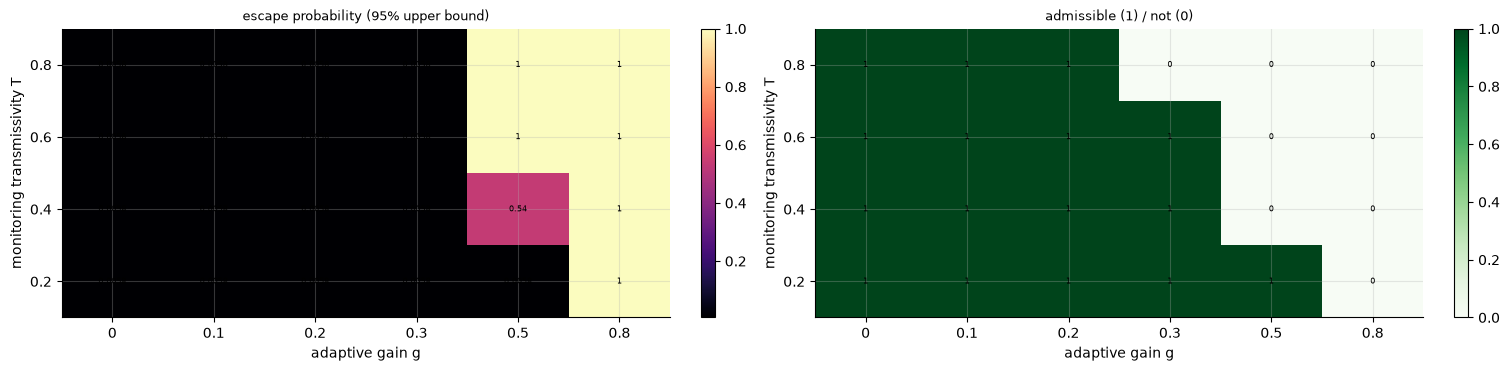

**Fig05_stability_map.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Upper bound: one-sided Clopper-Pearson over pooled trajectories x realizations; admissible = bound < 0.01 and Lambda_1^ch <= -0.02, physical, safe angles.

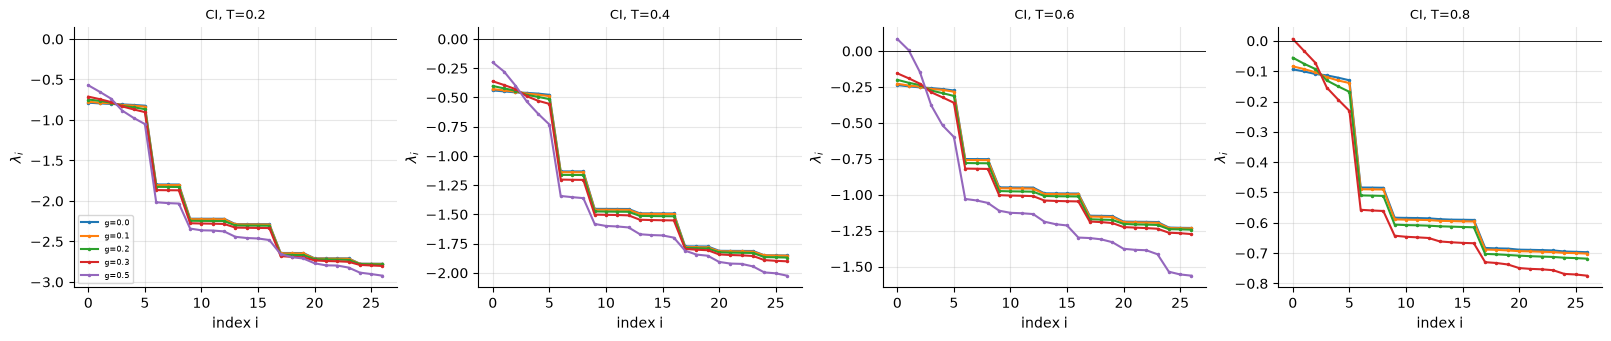

**Fig06_CI_spectra.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Full CI spectra of z=(r, vech Gamma) (dimension 27); mean over valid paths and realizations; paths that escaped are excluded and counted.

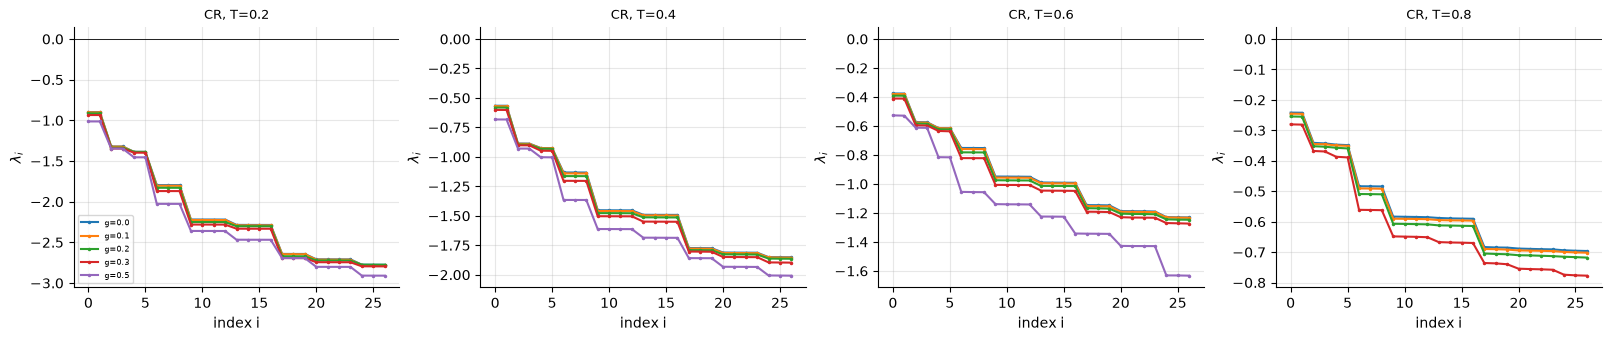

**Fig07_CR_spectra.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Full CR spectra of z=(r, vech Gamma) (dimension 27); mean over valid paths and realizations; paths that escaped are excluded and counted.

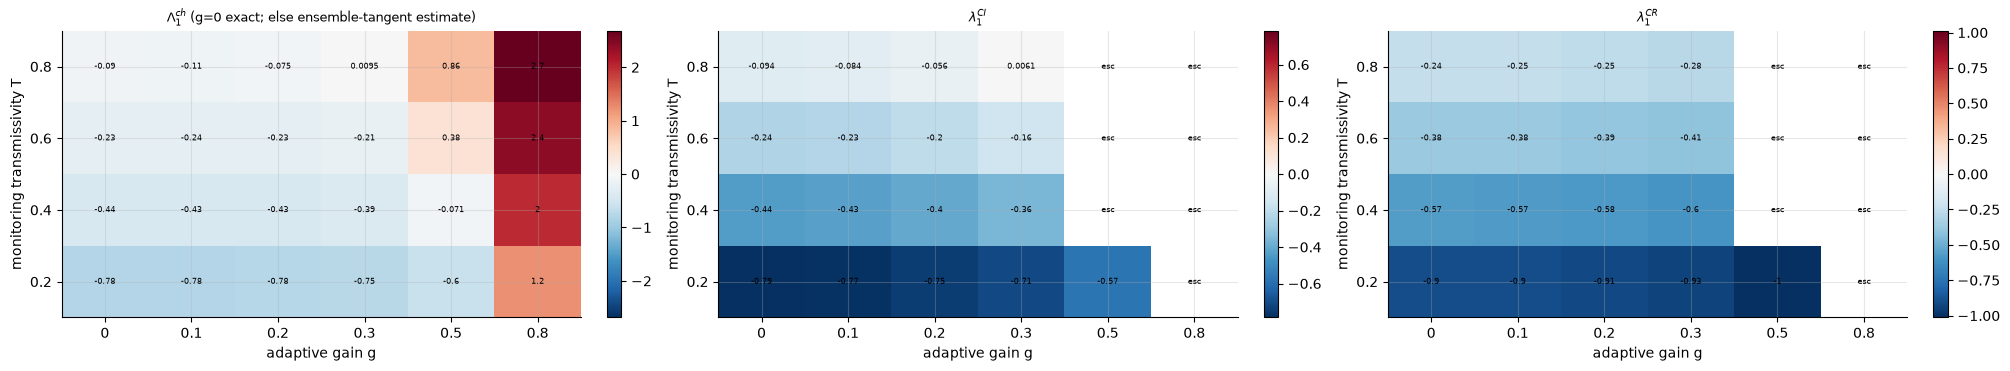

**Fig08_channel_and_leading_exponents.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Per clock. inf = all spectrum paths escaped. '-' = channel estimate unresolved above the Monte Carlo floor.

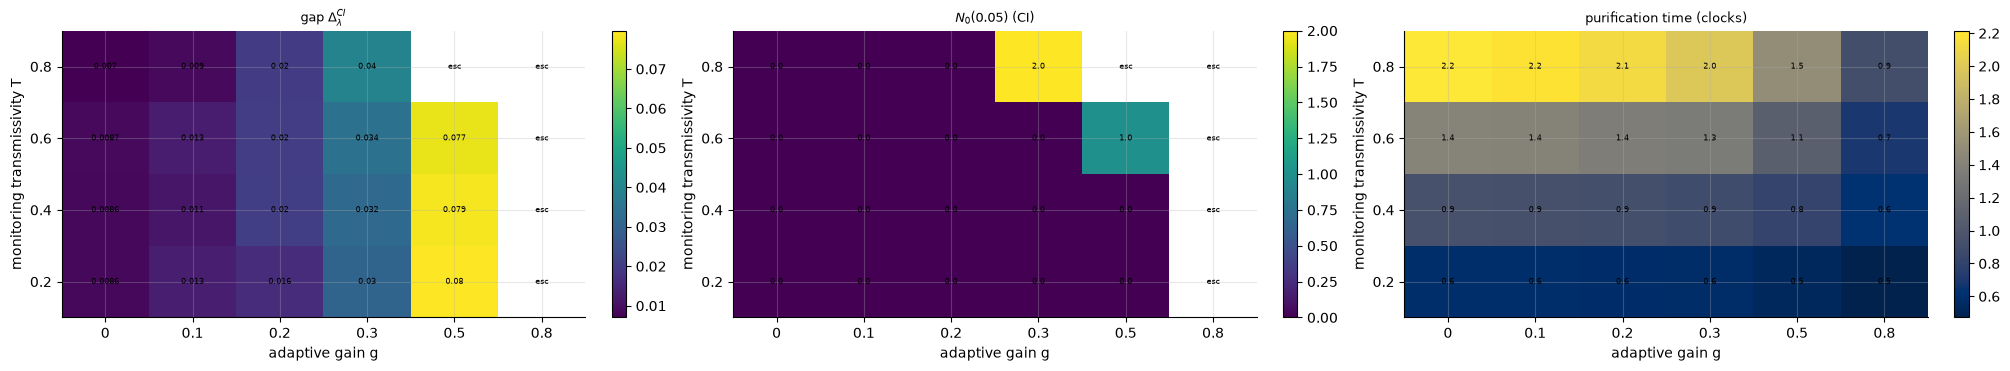

**Fig09_10_gap_N0_purification.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Gap = lambda_1 - lambda_2; N0 = number of |lambda_i| < 0.05; purification = e-folding time of the conditional-entropy difference between a thermal-initialized and a vacuum-initialized filter on a common record.

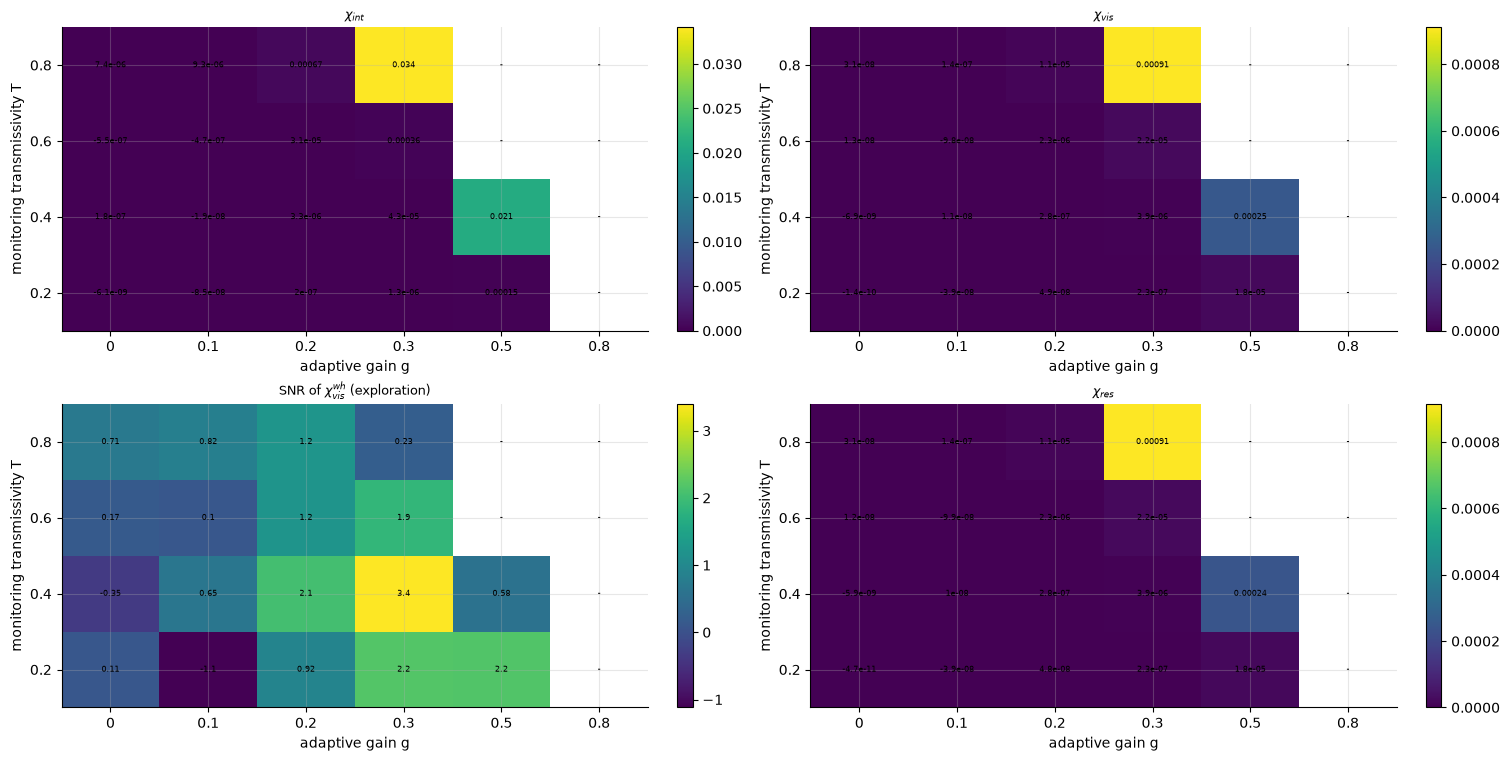

**Fig12_15_susceptibility_maps.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. U-statistic estimates (unbiased, can be negative from noise); computed only at points with no escape. SNR = mean / SE with SE = max(Monte Carlo jackknife, between-realization).

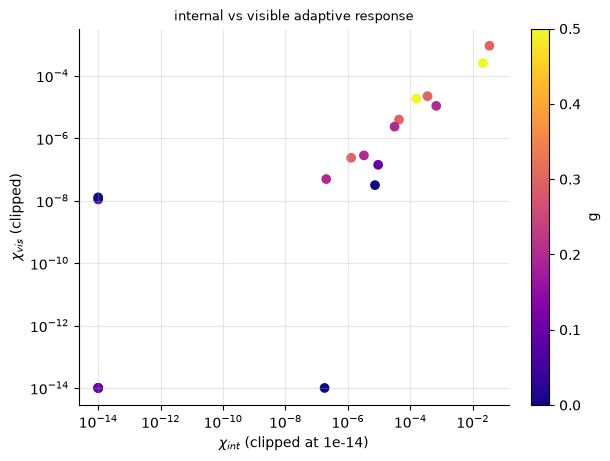

**Fig16_internal_vs_visible.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Each point one (g,T) cell; negative U-statistics clipped for the log axes only.

In [18]:
def heat(ax, A, col, title, cmap="viridis", center=False, fmt="{:.2g}", log=False):
    piv = A.pivot(index="T", columns="g", values=col).astype(float); v = piv.values.copy()
    if log:
        v = np.log10(np.clip(np.abs(v), 1e-30, None))
    vv = np.where(np.isfinite(v), v, np.nan); lim = np.nanmax(np.abs(vv)) if center and np.isfinite(vv).any() else None
    im = ax.imshow(vv, aspect="auto", origin="lower", cmap=cmap, vmin=-lim if lim else None, vmax=lim if lim else None)
    ax.set_xticks(range(piv.shape[1]), [f"{x:g}" for x in piv.columns]); ax.set_yticks(range(piv.shape[0]), [f"{x:g}" for x in piv.index])
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            raw = piv.values[i, j]; ax.text(j, i, "esc" if np.isinf(raw) else ("-" if not np.isfinite(raw) else fmt.format(raw)), ha="center", va="center", fontsize=6)
    ax.set_xlabel("adaptive gain g"); ax.set_ylabel("monitoring transmissivity T"); ax.set_title(title, fontsize=9); plt.colorbar(im, ax=ax, fraction=0.04)

def cap(extra=""):
    return (f"Mode {RUN_MODE}; N={CFG['N_main']} wires, L={CFG['L_depth']} layers; {CFG['n_explore']} exploration realizations per cell; "
            f"stability: {CFG['stab_paths']} trajectories x {K_TASK} clocks; spectra: {CFG['lyap_paths']} paths x {CFG['lyap_len']} clocks (burn {CFG['lyap_burn']}); "
            f"kernels: {CFG['kernel_paths']} CRN paths x {CFG['kernel_clocks']} clocks; EXPLORATORY. " + extra)

if len(SCAN):
    fig, axs = plt.subplots(1, 2, figsize=(15, 3.6)); heat(axs[0], SCAN, "p_escape_upper", "escape probability (95% upper bound)", "magma")
    heat(axs[1], SCAN.assign(adm=SCAN.admissible.astype(float)), "adm", "admissible (1) / not (0)", "Greens", fmt="{:.0f}")
    show_fig(fig, "Fig05_stability_map", cap("Upper bound: one-sided Clopper-Pearson over pooled trajectories x realizations; admissible = bound < "
             f"{PREREGISTERED['escape_pmax']} and Lambda_1^ch <= -{PREREGISTERED['channel_margin']}, physical, safe angles."))
    for mode, fname in (("CI", "Fig06_CI_spectra"), ("CR", "Fig07_CR_spectra")):
        Ts = CFG["T_grid"]; fig, axs = plt.subplots(1, len(Ts), figsize=(4 * len(Ts), 3.3), squeeze=False)
        for ax, T_ in zip(axs[0], Ts):
            for g_ in CFG["gain_grid"]:
                d = [r for r in SCAN_ROWS if r["T"] == T_ and r["g"] == g_ and r.get(f"{mode}_spectrum")]
                if d:
                    ax.plot(np.mean([r[f"{mode}_spectrum"] for r in d], 0), ".-", ms=3, label=f"g={g_}")
            ax.axhline(0, color="k", lw=0.6); ax.set_title(f"{mode}, T={T_}", fontsize=9); ax.set_xlabel("index i"); ax.set_ylabel(r"$\lambda_i$")
        axs[0][0].legend(fontsize=6)
        show_fig(fig, fname, cap(f"Full {mode} spectra of z=(r, vech Gamma) (dimension {make_model(EXPLORATION_SEEDS[0], CFG['N_main'], Lm, CFG['T_grid'][0]).d_state}); "
                 "mean over valid paths and realizations; paths that escaped are excluded and counted."))
    fig, axs = plt.subplots(1, 3, figsize=(20, 3.6)); heat(axs[0], SCAN, "Lambda1_ch", r"$\Lambda_1^{ch}$ (g=0 exact; else ensemble-tangent estimate)", "RdBu_r", True)
    heat(axs[1], SCAN, "CI_lambda1", r"$\lambda_1^{CI}$", "RdBu_r", True); heat(axs[2], SCAN, "CR_lambda1", r"$\lambda_1^{CR}$", "RdBu_r", True)
    show_fig(fig, "Fig08_channel_and_leading_exponents", cap("Per clock. inf = all spectrum paths escaped. '-' = channel estimate unresolved above the Monte Carlo floor."))
    fig, axs = plt.subplots(1, 3, figsize=(20, 3.6)); heat(axs[0], SCAN, "CI_gap", r"gap $\Delta_\lambda^{CI}$"); heat(axs[1], SCAN, "CI_N0", r"$N_0(0.05)$ (CI)", fmt="{:.1f}")
    heat(axs[2], SCAN, "tau_purif", "purification time (clocks)", "cividis", fmt="{:.1f}")
    show_fig(fig, "Fig09_10_gap_N0_purification", cap("Gap = lambda_1 - lambda_2; N0 = number of |lambda_i| < 0.05; purification = e-folding time of the conditional-entropy "
             "difference between a thermal-initialized and a vacuum-initialized filter on a common record."))
    fig, axs = plt.subplots(2, 2, figsize=(15, 7.5), constrained_layout=True)
    for ax, (col, ttl) in zip(axs.ravel(), (("chi_int", r"$\chi_{int}$"), ("chi_vis", r"$\chi_{vis}$"), ("snr_wh", r"SNR of $\chi^{wh}_{vis}$ (exploration)"),
                                             ("chi_res", r"$\chi_{res}$"))):
        heat(ax, SCAN, col, ttl, "viridis", fmt="{:.2g}")
    show_fig(fig, "Fig12_15_susceptibility_maps", cap("U-statistic estimates (unbiased, can be negative from noise); computed only at points with no escape. SNR = mean / SE "
             "with SE = max(Monte Carlo jackknife, between-realization)."))
    d = SCAN[np.isfinite(SCAN.chi_int) & np.isfinite(SCAN.chi_vis)]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    if len(d):
        sc = ax.scatter(np.clip(d.chi_int, 1e-14, None), np.clip(d.chi_vis, 1e-14, None), c=d.g, cmap="plasma"); plt.colorbar(sc, ax=ax, label="g")
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$\chi_{int}$ (clipped at 1e-14)"); ax.set_ylabel(r"$\chi_{vis}$ (clipped)"); ax.set_title("internal vs visible adaptive response", fontsize=9)
    show_fig(fig, "Fig16_internal_vs_visible", cap("Each point one (g,T) cell; negative U-statistics clipped for the log axes only."))

## 12. Independent boundaries, finite-size scaling and the structural lock

* **Boundaries,** defined in §6.5 before any task data. For each $T$ they are interpolated along $g$:
  * $g_{\rm traj}$: $\lambda^{\rm CI}_1=0$ (primary);
  * $g_{\rm contract}$: $\Lambda^{\rm ch}_1=0$;
  * $g_{\rm gap}$: $\Delta_\lambda\le0.02$;
  * $g_{\rm purif}$: purification time $>50$ clocks.
* **Finite-size scaling.** CI spectra along $g$ at the locked $T^\star$ for every size in `N_fss`. Two models are compared by BIC:
  * transition: $\Delta_\lambda N^{z}=F[(g-g_c)N^{1/\nu}]$, $F$ cubic;
  * smooth crossover: a cubic in $g$ plus a size offset.

  "Transition" requires at least 3 sizes, a BIC advantage $>10$, and finite fitted parameters. Otherwise the result is a **finite-size crossover**.
* **Lock rule (no task score).** The admissible set is $\mathcal A=\{\text{escape bound}<p_{\max},\ \Lambda^{\rm ch}_1\le-\text{margin},\ \text{physical},\ \text{safe}\}$. The candidates are $g>0$ in $\mathcal A$ on the stable side of $g_{\rm traj}(T)$. The lock is $(g^\star,T^\star)=\arg\max\chi^{\rm wh}_{\rm vis}$ (exploration mean). The manifest is hashed.

In [19]:
def crossing(xs, ys, level=0.0, up=True):
    xs, ys = np.asarray(xs, float), np.asarray(ys, float); ys = np.where(np.isinf(ys), 1e6 * np.sign(ys), ys)
    for i in range(len(xs) - 1):
        if not (np.isfinite(ys[i]) and np.isfinite(ys[i + 1])):
            continue
        if (ys[i] < level <= ys[i + 1]) if up else (ys[i] > level >= ys[i + 1]):
            return float(xs[i] + (level - ys[i]) * (xs[i + 1] - xs[i]) / (ys[i + 1] - ys[i]))
    return None

def boundaries(A):
    rows = []
    for T_, d in A.sort_values("g").groupby("T"):
        rows.append(dict(T=T_, g_traj=crossing(d.g, d.CI_lambda1), g_contract=crossing(d.g, d.Lambda1_ch), g_gap=crossing(d.g, d.CI_gap, 0.02, up=False),
                         g_purif=crossing(d.g, d.tau_purif.fillna(1e6), 50.0)))
    return pd.DataFrame(rows)

BOUND = boundaries(SCAN) if len(SCAN) else pd.DataFrame()
if len(BOUND):
    display(BOUND)

def make_lock(A, B, stage):
    gt = {r.T: r.g_traj for r in B.itertuples()}
    cand = A[A.admissible & (A.g > 0) & np.isfinite(A.chi_wh)].copy()
    cand = cand[[gt.get(T_) is None or g_ <= gt[T_] for T_, g_ in zip(cand.T, cand.g)]]
    if not len(cand):
        lock = dict(stage=stage, g_star=None, T_star=None, reason="no admissible g>0 with a resolved chi_vis^wh on the stable side")
    else:
        best = cand.loc[cand.chi_wh.idxmax()]
        lock = dict(stage=stage, g_star=float(best.g), T_star=float(best["T"]), chi_wh=float(best.chi_wh), chi_wh_se=float(best.chi_wh_se),
                    at_grid_boundary=bool(best.g >= max(CFG["gain_grid"]) or best["T"] in (min(CFG["T_grid"]), max(CFG["T_grid"]))),
                    g_traj_at_T=gt.get(float(best["T"])))
    lock.update(created=time.strftime("%Y-%m-%d %H:%M:%S"), graph=f"{CFG['N_main']} wires x {CFG['L_depth']} layers, in-layer {BASE['inter_wire']} C_Z (w={BASE['inter_weight']})",
                sizes=dict(N_main=CFG["N_main"], N_second=CFG["N_second"], L=CFG["L_depth"]), controller=PREREGISTERED["controller"],
                spectral_boundary="g_traj: lambda_1^CI = 0 (primary); g_contract, g_gap, g_purif reported", kernel_family=KSTAR,
                measurement_map="B_meas = (1-T) x xx-block of the post-wire second moments (exact, fixed tap)", feature_set="N(N+1)/2 tap second moments",
                witness="(1/sqrt 6) sum P3(u_{k-tc}) P1(u_{k-tl}) over K*", noise=dict(shots=CFG["shots_primary"], **{k: BASE[k] for k in ("squeezing_db", "loop_transmissivity",
                "detector_efficiency", "angle_jitter", "feedforward_gain_error")}), readout_policy="ridge, lambda grid " + str(CFG["ridge_grid"]) + " chosen on the last 25% of train; "
                "degree-2 family on label-free PCA", sigma_sha256=SIGMA_HASH, preregistered=PREREGISTERED)
    blob = json.dumps(lock, sort_keys=True, default=str); lock["sha256"] = hashlib.sha256(blob.encode()).hexdigest()
    (RES / f"lock_manifest_{stage}.json").write_text(json.dumps(lock, indent=1, default=str))
    return lock

LOCK = make_lock(SCAN, BOUND, "structural") if len(SCAN) else None
G_STAR, T_STAR = (LOCK["g_star"], LOCK["T_star"]) if LOCK else (None, None)
if LOCK:
    print(json.dumps({k: LOCK.get(k) for k in ("g_star", "T_star", "chi_wh", "chi_wh_se", "at_grid_boundary", "g_traj_at_T", "reason", "sha256")}, indent=1, default=str))

,T,g_traj,g_contract,g_gap,g_purif
0,0.2,0.50000,0.598641,None,None
1,0.4,0.30000,0.510253,None,None
2,0.6,0.30000,0.369966,None,None
3,0.8,0.29008,0.288757,None,None


{
 "g_star": 0.3,
 "T_star": 0.6,
 "chi_wh": 0.0014307111680047814,
 "chi_wh_se": 0.0007635996942714387,
 "at_grid_boundary": false,
 "g_traj_at_T": 0.3000000310447479,
 "reason": null,
 "sha256": "118f3312e25bc68b0ab53013b46674625a7fc6fde98a6f25684c3431ede58632"
}


[12.1 finite-size spectra] 27.3 s | peak RSS 1165 MB
finite-size scaling: {'verdict': 'finite-size crossover (best scaling fit unphysical: g_c outside the scanned range or nu, z out of bounds)', 'physical_fit': False, 'note': 'g_c, nu, z indicative only (cubic scaling function; synthetic tests recover the verdict, not the exponents)', 'g_c': 0.3698232204194706, 'nu': 9.999999999999947, 'z': 1.9404494033222104, 'dBIC': -5.78976056323166, 'n_sizes': 3}


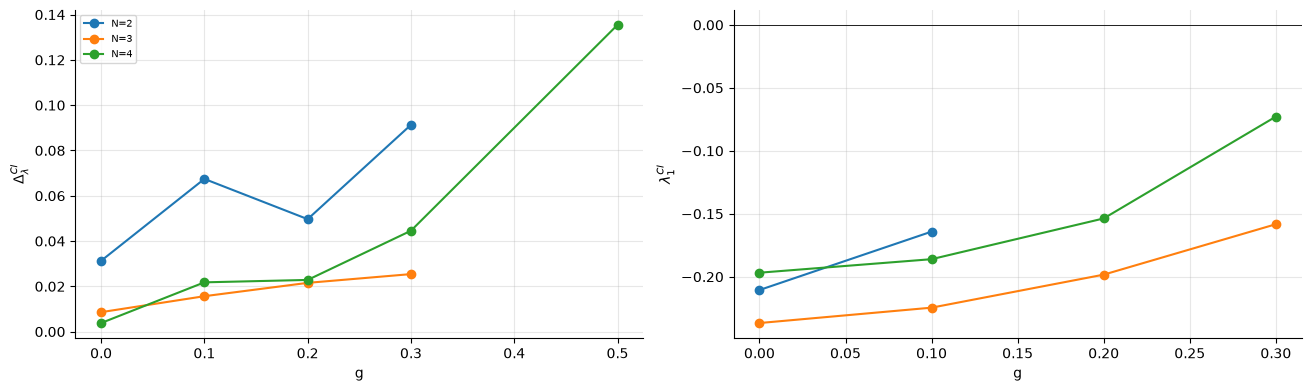

**Fig11_finite_size_gap.** Mode preflight; CI spectra at T=0.6, sizes N=[2, 3, 4], L=3; 2 exploration realizations x 3 paths x 400 clocks; means. Verdict: finite-size crossover (best scaling fit unphysical: g_c outside the scanned range or nu, z out of bounds). EXPLORATORY.

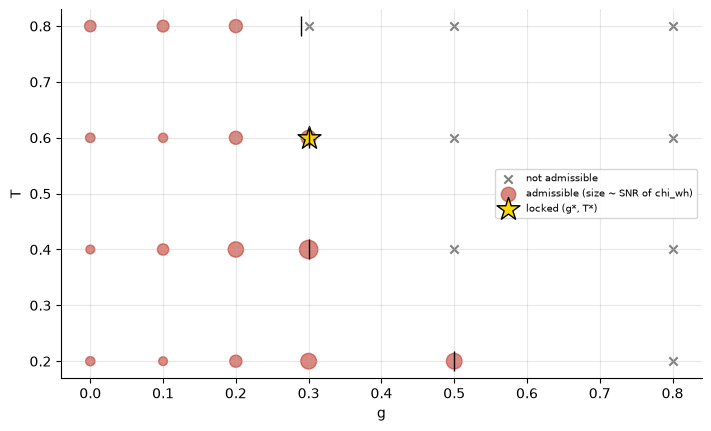

**Fig17_admissible_region_and_lock.** Mode preflight; N=3 wires, L=3 layers; 2 exploration realizations per cell; stability: 256 trajectories x 3200 clocks; spectra: 6 paths x 400 clocks (burn 100); kernels: 1024 CRN paths x 16 clocks; EXPLORATORY. Black ticks: interpolated trajectory boundary g_traj(T) where lambda_1^CI = 0. The lock uses no task score.

In [20]:
FSS_ROWS = []
if RUN_MODE != "unit" and len(SCAN):
    T_fss = T_STAR if T_STAR is not None else CFG["T_grid"][len(CFG["T_grid"]) // 2]
    with section("12.1 finite-size spectra"):
        for N_ in CFG["N_fss"]:
            for g_ in CFG["gain_grid"]:
                for rid in EXPLORATION_SEEDS[:max(1, min(2, CFG["n_explore"]))]:
                    def fss_unit(N_=N_, g_=g_, rid=rid):
                        m = make_model(rid, N_, CFG["L_depth"], T_fss); ul = input_sequence(rid, 5001, CFG["lyap_burn"] + CFG["lyap_len"])
                        sm = summarize_spectrum(reservoir_spectrum(m, g_, ul, max(2, CFG["lyap_paths"] // 2), CFG["lyap_ntan"], "CI", CFG["lyap_qr"], CFG["lyap_burn"],
                                                                   CFG["lyap_len"], ("fss", rid, N_, g_), xp=DEVICE["trajectories"]))
                        return dict(lambda1=sm["lambda1"] if sm else np.inf, gap=sm["gap"] if sm else np.nan, N0=sm["N0"] if sm else np.nan)
                    r = STORE.cached("fss", dict(N=N_, g=g_, T=T_fss, rid=rid, L=CFG["L_depth"], P=CFG["lyap_paths"], K=CFG["lyap_len"], sigma=SIGMA_HASH), fss_unit)
                    if not r.get("failed"):
                        FSS_ROWS.append(dict(N=N_, g=g_, rid=rid, **r))
FSS = pd.DataFrame(FSS_ROWS).groupby(["N", "g"]).mean(numeric_only=True).reset_index() if FSS_ROWS else pd.DataFrame()

def fss_compare(F):
    """Transition-collapse vs smooth-crossover models for the CI gap (BIC); requires >= 3 sizes."""
    d = F[np.isfinite(F.gap)]; Ns = sorted(d.N.unique())
    if len(Ns) < 3 or len(d) < 8:
        return dict(verdict="insufficient sizes for finite-size scaling (crossover by default)", n_sizes=len(Ns))
    x_g, Nn, y = d.g.values, d.N.values.astype(float), d.gap.values; n = len(y)
    def rss_T(par):
        # both models are scored in the units of the observed gap, y ~ N^{-z} f((g - g_c) N^{1/nu}), so the BIC comparison is fair
        gc, inv_nu, z = par; A_ = np.vander((x_g - gc) * Nn ** inv_nu, 4) * (Nn ** -z)[:, None]
        c, *_ = np.linalg.lstsq(A_, y, rcond=None); return float(((A_ @ c - y) ** 2).sum() / max(np.var(y), 1e-300))
    bnds = [(min(x_g), max(x_g)), (0.1, 10.0), (-3.0, 3.0)]
    best = min((scipy.optimize.minimize(rss_T, [gc0, inu0, 0.5], method="Nelder-Mead", bounds=bnds) for gc0 in np.linspace(min(x_g), max(x_g), 7)[1:-1] for inu0 in (0.5, 1.0, 2.0)),
               key=lambda r: r.fun)
    physical = bool(np.all(np.isfinite(best.x)) and all(lo + 1e-3 * (hi - lo) < v < hi - 1e-3 * (hi - lo) for v, (lo, hi) in zip(best.x, bnds)))   # interior optimum only
    A_c = np.c_[np.vander(x_g, 4), np.stack([(Nn == N_).astype(float) for N_ in Ns[1:]], 1)]; cc, *_ = np.linalg.lstsq(A_c, y, rcond=None)
    rssC = float(((A_c @ cc - y) ** 2).sum() / max(np.var(y), 1e-300))
    bic = lambda rss, k: n * np.log(max(rss, 1e-300) / n) + k * np.log(n)
    dBIC = bic(rssC, 4 + len(Ns) - 1) - bic(best.fun, 7)
    ok = dBIC > 10 and physical
    return dict(verdict="transition-scaling model favoured" if ok else ("finite-size crossover (no scaling evidence)" if physical else "finite-size crossover (best scaling fit unphysical: g_c outside the scanned range or nu, z out of bounds)"), physical_fit=physical, note="g_c, nu, z indicative only (cubic scaling function; synthetic tests recover the verdict, not the exponents)", g_c=float(best.x[0]), nu=float(1 / best.x[1]) if best.x[1] else np.inf,
                z=float(best.x[2]), dBIC=float(dBIC), n_sizes=len(Ns))
FSS_RES = fss_compare(FSS) if len(FSS) else dict(verdict="not run")
print("finite-size scaling:", FSS_RES)
if len(FSS):
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
    for N_, d in FSS.groupby("N"):
        axs[0].plot(d.g, d.gap, "o-", label=f"N={N_}"); axs[1].plot(d.g, np.where(np.isfinite(d.lambda1), d.lambda1, np.nan), "o-", label=f"N={N_}")
    axs[0].set_xlabel("g"); axs[0].set_ylabel(r"$\Delta_\lambda^{CI}$"); axs[1].axhline(0, color="k", lw=0.6); axs[1].set_xlabel("g"); axs[1].set_ylabel(r"$\lambda_1^{CI}$")
    axs[0].legend(fontsize=7)
    show_fig(fig, "Fig11_finite_size_gap", f"Mode {RUN_MODE}; CI spectra at T={T_fss}, sizes N={CFG['N_fss']}, L={CFG['L_depth']}; {max(1, min(2, CFG['n_explore']))} exploration "
             f"realizations x {max(2, CFG['lyap_paths'] // 2)} paths x {CFG['lyap_len']} clocks; means. Verdict: {FSS_RES['verdict']}. EXPLORATORY.")
if len(SCAN):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    adm = SCAN[SCAN.admissible]; nad = SCAN[~SCAN.admissible]
    ax.scatter(nad.g, nad["T"], marker="x", color="gray", label="not admissible"); ax.scatter(adm.g, adm["T"], s=40 + 400 * np.clip(adm.snr_wh.fillna(0) / 10, 0, 1),
                                                                                           color=COL["AD"], alpha=0.6, label="admissible (size ~ SNR of chi_wh)")
    for r in BOUND.itertuples():
        if r.g_traj is not None:
            ax.plot(r.g_traj, r.T, "k|", ms=14)
    if G_STAR is not None:
        ax.scatter([G_STAR], [T_STAR], marker="*", s=300, color="gold", edgecolor="k", label="locked (g*, T*)")
    ax.set_xlabel("g"); ax.set_ylabel("T"); ax.legend(fontsize=7)
    show_fig(fig, "Fig17_admissible_region_and_lock", cap("Black ticks: interpolated trajectory boundary g_traj(T) where lambda_1^CI = 0. The lock uses no task score."))

## 13. Independent structural validation and the structural-first stopping rule

Everything here uses the **validation seed bank**. Nothing is retuned.

* **Locked point.** $\chi_{\rm int}$, $\chi_{\rm vis}$, $\chi^{\rm wh}_{\rm vis}$ and $\chi_{\rm res}$ over `n_validate` realizations, plus a fresh full-horizon stability screen.
* **Second size** `N_second`: the same quantities. Replication needs $\chi^{\rm wh}_{\rm vis}$ positive with SNR $\ge3$.
* **Structural controls.**
  * $g=0$.
  * I.i.d. angles drawn from the AD marginal (Corollary 2a predicts exactly zero).
  * The same-input independent-copy outcome (mechanism diagnostic: it keeps the input-dependent outcome statistics and removes the copy's own back-action).
  * The controller routed to a causally disconnected wire (predicted exactly zero).
  * Any fixed nonadaptive basis (exactly zero, test K3).
* **Response taxonomy** (after Cao *et al.*): not input-generated / generated but not retained / retained but measurement-dark / visible but below shot noise / visible but removed by regularization / visible (task relevance needs the task stage).

**Stopping rule.** The task stage runs only if all 13 structural conditions pass. A `research_dryrun` of this exact code, matched by code hash, is one of them.

In [21]:
def code_prefix_hash():
    try:
        cells = list(get_ipython().user_ns.get("In", []))[1:]
    except NameError:
        cells = []
    norm = "\n\x1e\n".join("\n".join(l for l in c.splitlines() if not l.lstrip().startswith("RUN_MODE =")) for c in cells[:-1])
    return hashlib.sha256(norm.encode()).hexdigest()
GATE_CODE_HASH = code_prefix_hash()

VAL, VAL2, CTRL_STRUCT = {}, {}, {}
def val_block(N_, g_, T_, rids, ctrl_name=None):
    rows = []
    for rid in rids:
        def unit(N_=N_, g_=g_, T_=T_, rid=rid):
            m = make_model(rid, N_, CFG["L_depth"], T_, dummy=(ctrl_name == "disconnected"))
            ctrl = {}
            if ctrl_name == "indep":
                Mk = CFG["kernel_paths"]; base = np.roll(np.arange(Mk), 1); ctrl = dict(perm=np.concatenate([t * Mk + base for t in range(8)]))
            elif ctrl_name == "iid":
                pool = AD_ANGLE_POOL.get((N_, T_, g_))
                rngi = rng_for("iid", rid); cache = {}
                def th(k, j):
                    if (k, j) not in cache:
                        cache[(k, j)] = rngi.choice(pool[j - 1], size=(CFG["kernel_paths"], m.N))
                    return np.tile(cache[(k, j)], (8, 1))
                ctrl = dict(theta_override=th)
            elif ctrl_name == "disconnected":
                ctrl = dict(route_dummy=True)
            gg = 0.0 if ctrl_name == "g0" else g_
            st = simulate(m, input_sequence(rid, 5000, K_TASK), gg, rng_for("vstab", rid, N_, T_, gg), CFG["stab_paths"], xp=DEVICE["trajectories"], track=True)
            sus = susceptibilities(m, gg, rid, CFG["kernel_paths"], CFG["kernel_clocks"], CFG["kernel_fd_step"], xp=DEVICE["kernels"], ctrl=ctrl) if st["n_escaped"] == 0 else dict(failed=True, reason="escape")
            return dict(n_esc=st["n_escaped"], n_paths=st["n_paths"], min_abs_sin=st["stats"]["min_abs_sin"], **({} if sus.get("failed") else sus))
        r = STORE.cached("val", dict(N=N_, g=g_, T=T_, rid=rid, ctrl=ctrl_name, sigma=SIGMA_HASH, kp=CFG["kernel_paths"], kc=CFG["kernel_clocks"], K=K_TASK), unit)
        if r.get("failed"):
            FAILED_UNITS.append(dict(stage=f"validation:{ctrl_name}", N=N_, rid=rid, reason=r["reason"])); continue
        rows.append(r)
    def comb(key):
        v = np.array([r[key][0] for r in rows if key in r]); s = np.array([r[key][1] for r in rows if key in r])
        if not len(v):
            return dict(est=np.nan, se=np.nan, snr=np.nan, n=0)
        se = max(np.sqrt((s ** 2).sum()) / len(v), v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0)
        return dict(est=float(v.mean()), est_nonneg=float(max(0.0, v.mean())), se=float(se), snr=float(v.mean() / se) if se > 0 else np.nan, n=len(v),
                    ci=(float(v.mean() - 1.96 * se), float(v.mean() + 1.96 * se)))
    esc = sum(r["n_esc"] for r in rows); n = sum(r["n_paths"] for r in rows)
    return dict(rows=rows, p_escape_upper=cp_upper(esc, n), escapes=esc, **{k: comb(k) for k in ("chi_int", "chi_vis", "chi_wh", "chi_res")},
                eps_lo=float(np.mean([r["chi_wh_eps_lo"] for r in rows if "chi_wh_eps_lo" in r])) if any("chi_wh_eps_lo" in r for r in rows) else np.nan,
                eps_hi=float(np.mean([r["chi_wh_eps_hi"] for r in rows if "chi_wh_eps_hi" in r])) if any("chi_wh_eps_hi" in r for r in rows) else np.nan)

AD_ANGLE_POOL = {}
if G_STAR is not None and RUN_MODE != "unit":
    with section("13.1 structural validation"):
        rv = VALIDATION_SEEDS[:CFG["n_validate"]]
        VAL = val_block(CFG["N_main"], G_STAR, T_STAR, rv)
        VAL2 = val_block(CFG["N_second"], G_STAR, T_STAR, VALIDATION_SEEDS[:max(2, CFG["n_validate"] // 2)])
        m0 = make_model(rv[0], CFG["N_main"], CFG["L_depth"], T_STAR)
        th_s = []
        for rid in rv[:2]:
            sim = simulate(make_model(rid, CFG["N_main"], CFG["L_depth"], T_STAR), input_sequence(rid, 6000, 400), G_STAR, rng_for("pool", rid), 256, keep_m=True)
            # recover angles from the recorded outcomes through the same controller (exact): theta_j = mid + D tanh(z0 + g tanh(m_{j-1}/sigma))
            mm = sim["m"][100:]; mdl = make_model(rid, CFG["N_main"], CFG["L_depth"], T_STAR)
            th_s.append(np.stack([TH_MID + DTH * np.tanh(mdl.z0[None, None, :, j - 1] + G_STAR * np.tanh(mm[:, :, j - 1] / mdl.sigma[j - 1])) for j in range(1, mdl.L)]))
        AD_ANGLE_POOL[(CFG["N_main"], T_STAR, G_STAR)] = [np.concatenate([t[j].ravel() for t in th_s]) for j in range(CFG["L_depth"] - 1)]
        rc = VALIDATION_SEEDS[:max(2, min(3, CFG["n_validate"]))]
        for cname in ("g0", "iid", "indep", "disconnected"):
            CTRL_STRUCT[cname] = val_block(CFG["N_main"], G_STAR, T_STAR, rc, cname)
        ledger_use("structural-validation", "validation", range(CFG["n_validate"]))
    VAL_DF = pd.DataFrame({lab: {**{f"{k} {s}": blk[k][s] for k in ("chi_int", "chi_vis", "chi_wh", "chi_res") for s in ("est", "snr")},
                                 "realizations used": blk["chi_wh"]["n"], "escaped paths": blk["escapes"], "CP escape bound": blk["p_escape_upper"]}
                           for lab, blk in [("AD (validation, N_main)", VAL), (f"AD (N_second={CFG['N_second']})", VAL2)] + [(f"control: {k}", v) for k, v in CTRL_STRUCT.items()]}).T
    with pd.option_context("display.width", 250, "display.float_format", "{:.3g}".format):
        display(VAL_DF)
    print("chi estimates use only realizations with no escaped path (escaped realizations are counted, not averaged).")
    print(f"validation escape bound: {VAL['p_escape_upper']:.4f} | whitening-epsilon sensitivity of chi_wh: x0.01 -> {VAL['eps_lo']:.3g}, base {VAL['chi_wh']['est']:.3g}, "
          f"x100 -> {VAL['eps_hi']:.3g}")

[13.1 structural validation] 297.0 s | peak RSS 1165 MB


,chi_int est,chi_int snr,chi_vis est,chi_vis snr,chi_wh est,chi_wh snr,chi_res est,chi_res snr,realizations used,escaped paths,CP escape bound
"AD (validation, N_main)",0.000727,2.38,2.76e-05,1.92,0.000954,1.86,2.75e-05,1.92,2,315,0.332
AD (N_second=4),0.0015,1.6,8.71e-05,2.12,0.00271,1.86,8.68e-05,2.12,2,0,0.00583
control: g0,-4.48e-07,-0.257,-4.79e-08,-0.26,-2.79e-06,-0.283,-4.77e-08,-0.26,3,0,0.00389
control: iid,-9.04e-06,-0.4,-9.34e-07,-0.759,-4.73e-05,-0.787,-9.33e-07,-0.761,2,59,0.0945
control: indep,3.42e-05,1.35,4.35e-07,0.452,2.58e-05,0.571,4.33e-07,0.451,2,59,0.0945
control: disconnected,6.33e-07,0.496,-2.61e-08,-0.257,-2.13e-06,-0.402,-2.59e-08,-0.255,2,47,0.0774


chi estimates use only realizations with no escaped path (escaped realizations are counted, not averaged).
validation escape bound: 0.3322 | whitening-epsilon sensitivity of chi_wh: x0.01 -> 0.000954, base 0.000954, x100 -> 0.000954


response decomposition at the locked point: not input-generated (internal adaptive response unresolved)


,passed
1 native/reference agreement,True
2 exact zero-adaptivity nesting,True
3 valid within-pattern causal ordering,True
4 full-horizon stability,False
5 safe-angle condition,True
6 full Lyapunov-spectrum validation,True
7 independent spectral boundary or resolved crossover,True
8 nonzero internal adaptive response,False
9 chi_vis^wh SNR >= 5 (validation bank),False
10 response replication at a second size,False


NO-GO (structural stage): 4 full-horizon stability; 8 nonzero internal adaptive response; 9 chi_vis^wh SNR >= 5 (validation bank); 10 response replication at a second size | task stage SKIPPED 


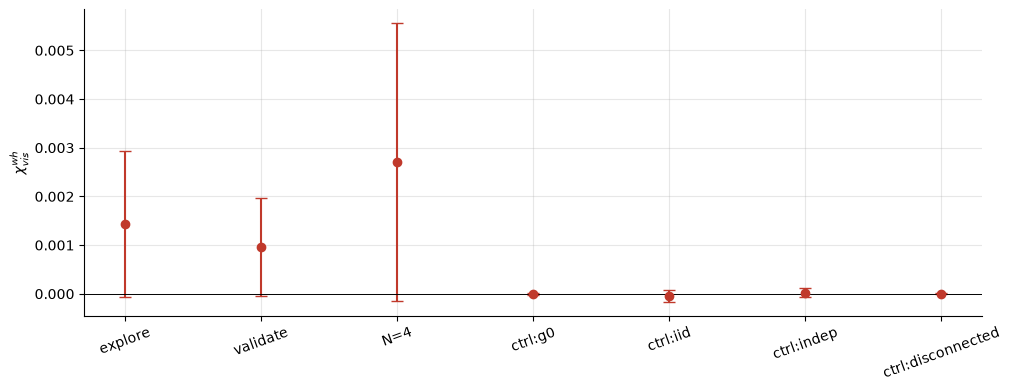

**Fig18_locked_point_validation.** Mode preflight; locked (g*,T*)=(0.3,0.6); exploration (2 realizations), validation bank (4), second size (2), controls (3); 1024 CRN paths x 16 clocks each; 95% CI from max(jackknife, between-realization) SE. Exploration is EXPLORATORY; validation is the independent structural test.

In [22]:
def taxonomy(V):
    if not V:
        return "not evaluated (no locked point)"
    zi, zv, zw = V["chi_int"]["snr"], V["chi_vis"]["snr"], V["chi_wh"]["snr"]
    ratio_res = V["chi_res"]["est"] / V["chi_vis"]["est"] if V["chi_vis"]["est"] and np.isfinite(V["chi_vis"]["est"]) and V["chi_vis"]["est"] > 0 else np.nan
    if not (zi >= 3):
        return "not input-generated (internal adaptive response unresolved)"
    if not (zv >= 3):
        return "generated internally but measurement-dark (visible response unresolved)"
    if not (zw >= PREREGISTERED["snr_min"]):
        return "visible but below finite-shot noise (chi_vis^wh SNR < threshold)"
    if np.isfinite(ratio_res) and ratio_res < 0.1:
        return "visible but removed by regularization"
    return "visible above noise and regularization (task relevance requires the task stage)"
TAXONOMY = taxonomy(VAL)
print("response decomposition at the locked point:", TAXONOMY)

def snr(b, k="chi_wh"):
    return b[k]["snr"] if b and np.isfinite(b.get(k, {}).get("snr", np.nan)) else np.nan

STRUCT_COND = {}
crit = {t["id"]: t["passed"] for t in TESTS}
STRUCT_COND["1 native/reference agreement"] = all(crit.get(i, False) for i in ("V1", "V3", "V4"))
STRUCT_COND["2 exact zero-adaptivity nesting"] = crit.get("V6", False)
STRUCT_COND["3 valid within-pattern causal ordering"] = crit.get("V5", False)
STRUCT_COND["4 full-horizon stability"] = bool(VAL) and VAL["p_escape_upper"] < PREREGISTERED["escape_pmax"]
STRUCT_COND["5 safe-angle condition"] = crit.get("V7", False) and (not VAL or all(r["min_abs_sin"] >= math.sin(PREREGISTERED["theta_min"]) - 1e-12 for r in VAL["rows"]))
STRUCT_COND["6 full Lyapunov-spectrum validation"] = all(t["passed"] for t in TESTS if t["category"] == "spectrum" and t["critical"])
STRUCT_COND["7 independent spectral boundary or resolved crossover"] = len(BOUND) > 0 and BOUND.g_traj.notna().any()
STRUCT_COND["8 nonzero internal adaptive response"] = snr(VAL, "chi_int") >= 3
STRUCT_COND["9 chi_vis^wh SNR >= 5 (validation bank)"] = snr(VAL) >= PREREGISTERED["snr_min"]
STRUCT_COND["10 response replication at a second size"] = snr(VAL2) >= 3 and VAL2["chi_wh"]["est"] > 0 if VAL2 else False
STRUCT_COND["11 candidate not at the scanned-grid boundary"] = bool(LOCK) and LOCK.get("g_star") is not None and not LOCK.get("at_grid_boundary", True)
STRUCT_COND["12 candidate chosen without task performance"] = bool(LOCK) and LOCK.get("g_star") is not None
dry_marker = Path(RESULTS_DIR).resolve() / "research_dryrun" / "dryrun_marker.json"
DRY_OK = RUN_MODE == "research_dryrun" or (dry_marker.exists() and json.loads(dry_marker.read_text()).get("code_hash") == GATE_CODE_HASH)
STRUCT_COND["13 research-dry-run passed (same code hash)"] = DRY_OK
STRUCT_DF = pd.Series(STRUCT_COND).to_frame("passed"); display(STRUCT_DF)
STRUCT_ALL = all(STRUCT_COND.values())
NO_FIXED_SHORTCUT = bool(CTRL_STRUCT) and not any(snr(CTRL_STRUCT.get(c, {})) >= 3 for c in ("g0", "iid", "disconnected")) and crit.get("K3", False)
RUN_TASK = STRUCT_ALL or RUN_MODE == "research_dryrun"
if STRUCT_COND["8 nonzero internal adaptive response"] and not STRUCT_COND["9 chi_vis^wh SNR >= 5 (validation bank)"]:
    STOP_MSG = "NO-GO: the adaptive response is generated internally but is not observable with the selected physical readout."
elif not STRUCT_ALL:
    STOP_MSG = "NO-GO (structural stage): " + "; ".join(k for k, v in STRUCT_COND.items() if not v)
else:
    STOP_MSG = "structural gates passed: task stage enabled"
print(STOP_MSG, "| task stage", "RUNS" if RUN_TASK else "SKIPPED", "(control-flow validation only)" if RUN_MODE == "research_dryrun" and not STRUCT_ALL else "")

if VAL:
    fig, ax = plt.subplots(figsize=(10, 3.8)); labs, vals, errs = [], [], []
    for lab, b in [("explore", None), ("validate", VAL), (f"N={CFG['N_second']}", VAL2)] + [(f"ctrl:{k}", v) for k, v in CTRL_STRUCT.items()]:
        if b is None:
            row = SCAN[(SCAN.g == G_STAR) & (SCAN["T"] == T_STAR)].iloc[0]; labs.append(lab); vals.append(row.chi_wh); errs.append(row.chi_wh_se)
        elif b:
            labs.append(lab); vals.append(b["chi_wh"]["est"]); errs.append(b["chi_wh"]["se"])
    ax.errorbar(range(len(labs)), vals, 1.96 * np.array(errs), fmt="o", capsize=4, color=COL["AD"]); ax.axhline(0, color="k", lw=0.7)
    ax.set_xticks(range(len(labs)), labs, rotation=20); ax.set_ylabel(r"$\chi^{wh}_{vis}$")
    show_fig(fig, "Fig18_locked_point_validation", f"Mode {RUN_MODE}; locked (g*,T*)=({G_STAR},{T_STAR}); exploration ({CFG['n_explore']} realizations), validation bank "
             f"({CFG['n_validate']}), second size ({max(2, CFG['n_validate'] // 2)}), controls ({max(2, min(3, CFG['n_validate']))}); {CFG['kernel_paths']} CRN paths x "
             f"{CFG['kernel_clocks']} clocks each; 95% CI from max(jackknife, between-realization) SE. Exploration is EXPLORATORY; validation is the independent structural test.")
else:
    print("Fig 18 (locked-point validation) not produced: no structural lock, so there is no locked point to validate.")

## 14. Statistical machinery and the remaining validation tests

* **Readouts.** Ridge with intercept on standardized features, $\lambda$ chosen per target on the last 25 % of the training block from the common grid. The degree-2 family uses the same pipeline after a label-free PCA, fitted on training features only, to `poly_pca_dim` components, followed by all degree-$\le2$ monomials. Every model gets identical output dimension, regularization grid, training data and tuning budget.
* **Statistics.**
  * paired one-sided $t$ on realization means, with Holm over $\{H_A,H_B\}$;
  * hierarchical bootstrap (realizations → replicates);
  * nested variance components;
  * Monte Carlo power of the exact analysis.

In [23]:
PAD = 25
def leg(n, x):
    return np.sqrt(2 * n + 1) * npleg.legval(x, [0] * n + [1])

def lagged(u, t):
    out = np.zeros_like(u); out[t:] = u[:len(u) - t] if t else u; return out

def narma(u, order):
    v = 0.25 * (u + 1); y = np.zeros(len(u))
    for k in range(order, len(u)):
        y[k] = 0.3 * y[k - 1] + 0.05 * y[k - 1] * y[k - order:k].sum() + 1.5 * v[k - 1] * v[k - order] + 0.1
    return np.clip(y, -10, 10)

def make_targets(u, secondary=True):
    T_ = {f"K*{c}": leg(3, lagged(u, c[0])) * leg(1, lagged(u, c[1])) for c in KSTAR}
    T_["witness"] = sum(T_[f"K*{c}"] for c in KSTAR) / np.sqrt(len(KSTAR))
    if secondary:
        b = (u > 0).astype(float); T_["NARMA5"], T_["NARMA10"] = narma(u, 5), narma(u, 10)
        T_["XOR(1,2)"] = np.logical_xor(lagged(b, 1), lagged(b, 2)).astype(float); T_["parity3"] = ((lagged(b, 0) + lagged(b, 1) + lagged(b, 2)) % 2).astype(float)
        for t in range(16):
            T_[f"mem{t}"] = lagged(u, t)
    return T_

def poly2(X, W, Ltr, dim):
    """Label-free degree-2 feature map: standardize and PCA on training features only, then all degree <= 2 monomials (fixed output size)."""
    Xtr = X[W:W + Ltr]; mu, sd = Xtr.mean(0), Xtr.std(0); sd = np.where(sd > 1e-12, sd, 1.0); Z = (X - mu) / sd
    _, _, Vt = np.linalg.svd(Z[W:W + Ltr] - Z[W:W + Ltr].mean(0), full_matrices=False); k = min(dim, Vt.shape[0]); P_ = Z @ Vt[:k].T
    P_ = np.c_[P_, np.zeros((len(P_), dim - k))]; ii, jj = np.triu_indices(dim)
    return np.c_[P_, P_[:, ii] * P_[:, jj]]

def readout_nmse(X, targets, W, Ltr, lam_grid=None, fixed_lambda=None):
    lam_grid = CFG["ridge_grid"] if lam_grid is None else lam_grid; W = max(W, PAD); X = np.asarray(X, float)
    if not np.isfinite(X[W:]).all():
        return {k: np.nan for k in targets}, {}
    Xtr, Xte = X[W:W + Ltr], X[W + Ltr:]; mu, sd = Xtr.mean(0), Xtr.std(0); sd = np.where(sd > 1e-12 * max(1.0, np.abs(mu).max()), sd, 1.0)
    Z, Zte = (Xtr - mu) / sd, (Xte - mu) / sd
    Y = np.stack([targets[k][W:W + Ltr] for k in targets], 1); Yte = np.stack([targets[k][W + Ltr:] for k in targets], 1); nv = int(0.75 * Ltr)
    def fit(Zf, Yf, lams):
        zm, ym = Zf.mean(0), Yf.mean(0); U_, s_, Vt = np.linalg.svd(Zf - zm, full_matrices=False); UtY = U_.T @ (Yf - ym)
        return [(Vt.T @ ((s_ / (s_ ** 2 + l))[:, None] * UtY), zm, ym) for l in lams]
    if fixed_lambda is None:
        errs = np.array([((Z[nv:] - zm) @ w + ym - Y[nv:]) ** 2 for (w, zm, ym) in fit(Z[:nv], Y[:nv], lam_grid)]).mean(1)
        best = [lam_grid[i] for i in errs.argmin(0)]
    else:
        best = [fixed_lambda] * Y.shape[1]
    out, chosen = {}, {}
    for j, k in enumerate(targets):
        (w, zm, ym), = fit(Z, Y[:, [j]], [best[j]]); pred = (Zte - zm) @ w + ym
        out[k] = float(np.mean((pred[:, 0] - Yte[:, j]) ** 2) / np.var(Yte[:, j])); chosen[k] = best[j]
    return out, chosen

def summarize_scores(sc):
    d = dict(witness=sc.get("witness", np.nan), Cstar=float(sum(1 - sc[f"K*{c}"] for c in KSTAR)) if f"K*{KSTAR[0]}" in sc else np.nan)
    for k in ("NARMA5", "NARMA10", "XOR(1,2)", "parity3"):
        if k in sc:
            d[k] = sc[k]
    if "mem0" in sc:
        d["MC"] = float(sum(max(0.0, 1 - sc[f"mem{t}"]) for t in range(16)))
    return d

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (len(p) - rank) * p[i])); adj[i] = run
    return adj

def paired_onesided(D):
    m = np.nanmean(D, 1); m = m[np.isfinite(m)]; n = len(m)
    if n < 2:
        return (float(np.mean(m)) if n else np.nan), np.nan, np.nan
    se = m.std(ddof=1) / np.sqrt(n); t = m.mean() / se if se > 0 else np.inf * np.sign(m.mean())
    return float(m.mean()), float(t), float(sst.t.sf(t, n - 1))

def hier_bootstrap(D, B, rng):
    R, J = D.shape; out = np.empty(B)
    for b in range(B):
        rr = rng.integers(0, R, R); jj = rng.integers(0, J, (R, J)); out[b] = np.nanmean(D[rr[:, None], jj])
    return out

def variance_components(D3):
    R, I, J = D3.shape
    s2_rep = float(np.nanmean(np.nanvar(D3, axis=2, ddof=1))) if J > 1 else 0.0
    mi = np.nanmean(D3, 2); s2_inp = max(0.0, float(np.nanmean(np.nanvar(mi, axis=1, ddof=1))) - s2_rep / J) if I > 1 else 0.0
    mr = np.nanmean(mi, 1); s2_real = max(0.0, float(np.nanvar(mr, ddof=1)) - (s2_inp + s2_rep / J) / I) if R > 1 else 0.0
    return s2_real, s2_inp, s2_rep

def analyse(D, delta_min, B, rng):
    mean, t, p = paired_onesided(D); boot = hier_bootstrap(D, B, rng); m = np.nanmean(D, 1)
    return dict(n_realizations=int(np.isfinite(m).sum()), mean=mean, median=float(np.nanmedian(m)), ci_low=float(np.percentile(boot, 2.5)), ci_high=float(np.percentile(boot, 97.5)),
                d=float(mean / np.nanstd(m, ddof=1)) if np.nanstd(m, ddof=1) > 0 else np.nan, t=t, p_one_sided=p, P_exceeds_delta_min=float((boot > delta_min).mean()),
                max_single_share=float(np.nanmax(np.abs(m)) / max(np.nansum(np.abs(m)), 1e-300)))

def power_holm(deltas, comps, rho, n, I, J, alpha, sims, rng):
    v = [c[0] + c[1] / I + c[2] / (I * J) for c in comps]; cov = np.array([[v[0], rho * np.sqrt(v[0] * v[1])], [rho * np.sqrt(v[0] * v[1]), v[1]]])
    m = rng.multivariate_normal(deltas, cov + 1e-15 * np.eye(2), size=(sims, n)); t = m.mean(1) / (m.std(1, ddof=1) / np.sqrt(n)); p = sst.t.sf(t, n - 1)
    rej = np.array([holm(pp) < alpha for pp in p])
    return float(rej[:, 0].mean()), float(rej[:, 1].mean()), float(rej.all(1).mean())

with section("14 validation suite"):
    rng = rng_for("suite")
    banks = dict(calibration=CALIBRATION_SEEDS, exploration=EXPLORATION_SEEDS, validation=VALIDATION_SEEDS, pilot=PILOT_SEEDS, confirmation=CONFIRMATION_SEEDS)
    disjoint = all(not (set(a) & set(b)) for (ka, a), (kb, b) in itertools.combinations(banks.items(), 2))
    led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
    record_test("S2", "statistical", "five seed banks pairwise disjoint; confirmation bank used by no stage other than 'confirmation' (ledger)", f"disjoint={disjoint}, "
                f"confirmation stages={list(led.get('confirmation', {}))}", "True, none", disjoint and set(led.get("confirmation", {})) <= {"confirmation"})
    uS = input_sequence(0, 4, 900); tS = make_targets(uS, False); mS = make_model(EXPLORATION_SEEDS[0], 2, CFG["L_depth"], CFG["T_grid"][0]); XS = NAExact(mS).features(uS)[0]
    sa, la = readout_nmse(XS, tS, 100, 500); XS2 = XS.copy(); XS2[600:] = XS2[600:] * 7 + 3; sb, lb = readout_nmse(XS2, tS, 100, 500)
    P1, P2 = poly2(XS, 100, 500, 6), poly2(XS2, 100, 500, 6)
    record_test("S1", "statistical", "no train/test leakage: corrupting test features leaves scaler, PCA and lambda selection unchanged", "unchanged" if la == lb and
                np.allclose(P1[100:600], P2[100:600]) else "changed", "unchanged", la == lb and np.allclose(P1[100:600], P2[100:600]))
    def verify_lock(path):
        L_ = json.loads(Path(path).read_text()); h = L_.pop("sha256"); return hashlib.sha256(json.dumps(L_, sort_keys=True, default=str).encode()).hexdigest() == h
    tl = RES / "_lock_test.json"; L0 = dict(g_star=0.3, T_star=0.4); L0["sha256"] = hashlib.sha256(json.dumps(L0, sort_keys=True).encode()).hexdigest()
    tl.write_text(json.dumps(L0)); good = verify_lock(tl); L0["g_star"] = 0.5; tl.write_text(json.dumps(L0)); tampered = verify_lock(tl); tl.unlink()
    record_test("S3", "statistical", "confirmatory-lock enforcement: a tampered lock manifest is rejected", f"intact={good}, tampered accepted={tampered}", "True, False", good and not tampered)
    Dsyn = 0.05 + rng.normal(0, 0.03, (12, 1)) + rng.normal(0, 0.02, (12, 4)); r4 = analyse(Dsyn, 0.03, 2000, rng)
    record_test("S4", "statistical", "paired analysis recovers an injected difference 0.05 (inside the 95% CI)", f"{r4['mean']:.4f} [{r4['ci_low']:.4f}, {r4['ci_high']:.4f}]", "in CI",
                r4["ci_low"] <= 0.05 <= r4["ci_high"])
    sds = [hier_bootstrap(rng.normal(0, 0.03, (15, 1)) + rng.normal(0, 0.04, (15, 3)), 300, rng).std() for _ in range(150)]; se_true = np.sqrt(0.03 ** 2 / 15 + 0.04 ** 2 / 45)
    record_test("S5", "statistical", "hierarchical bootstrap SE / analytic nested SE", np.mean(sds) / se_true, "in [0.85, 1.15]", 0.85 <= np.mean(sds) / se_true <= 1.15)
    m0 = rng.multivariate_normal([0, 0], [[1, 0.5], [0.5, 1]], size=(4000, 10)); p0 = sst.t.sf(m0.mean(1) / (m0.std(1, ddof=1) / np.sqrt(10)), 9)
    fwer = float(np.mean([(holm(p) < PREREGISTERED["alpha"]).any() for p in p0]))
    record_test("S6", "statistical", "null calibration: family-wise false-positive rate of one-sided Holm over 2 comparisons (4000 null datasets)", fwer, "<= alpha + 0.012",
                fwer <= PREREGISTERED["alpha"] + 0.012)
    pw = power_holm([0.03, 0.03], [(0.02 ** 2, 0, 0.0)] * 2, 0.0, 12, 1, 1, PREREGISTERED["alpha"], 4000, rng)
    bound = float(sst.nct.sf(sst.t.isf(PREREGISTERED["alpha"] / 2, 11), 11, 0.03 / (0.02 / np.sqrt(12))))
    record_test("S7", "statistical", "injected effect recovered with the predicted power (simulated Holm vs noncentral-t bound)", f"{pw[0]:.3f} vs {bound:.3f}", "sim >= bound - 0.03",
                pw[0] >= bound - 0.03)
    mN = make_model(EXPLORATION_SEEDS[0], CFG["N_main"], CFG["L_depth"], CFG["T_grid"][0]); uN = input_sequence(1, 0, 60)
    a1 = simulate(mN, uN, 0.1, rng_for("rep"), 32, shots_list=(32,)); a2 = simulate(mN, uN, 0.1, rng_for("rep"), 32, shots_list=(32,))
    record_test("N2", "numerical", "deterministic seed reproduction (bitwise)", "identical" if np.array_equal(a1["rb"], a2["rb"]) and np.array_equal(a1["raw"][32], a2["raw"][32]) else "differ",
                "identical", np.array_equal(a1["rb"], a2["rb"]) and np.array_equal(a1["raw"][32], a2["raw"][32]))
    a3 = simulate(mN, np.repeat(uN[:, None], 32, 1), 0.1, rng_for("rep"), 32); a4 = simulate(mN, uN, 0.1, rng_for("rep"), 32, dtype=np.complex128)
    e4 = max(np.abs(a3["rb"] - a1["rb"]).max(), np.abs(a4["rb"] - a1["rb"]).max()) / np.abs(a1["rb"]).max()
    record_test("N4", "numerical", "scalar/batch agreement: per-path inputs and the complex code path reproduce the scalar-input run", e4, "< 1e-12", e4 < 1e-12)
    o7 = simulate(mN, input_sequence(0, 1, 200), 0.1, rng_for("shots"), 1024, shots_list=(64, 256, 1024))
    dev = [np.sqrt(np.nanmean((o7["raw"][S][40:] - o7["rb"][40:]) ** 2)) for S in (64, 256, 1024)]; sl = np.polyfit(np.log([64, 256, 1024]), np.log(dev), 1)[0]
    record_test("N7", "numerical", "shot convergence: raw-feature error vs RB scales as S^slope (expect -0.5)", sl, "in [-0.7, -0.3]", -0.7 <= sl <= -0.3, critical=False)
    mK = make_model(EXPLORATION_SEEDS[0], 2, CFG["L_depth"], CFG["T_grid"][0])
    b16 = kernel_blocks(mK, 0.1, (1, 3, 0, 1), 256, "seqc", 16, 0.1)["vis"]; b24 = kernel_blocks(mK, 0.1, (1, 3, 0, 1), 256, "seqc", 24, 0.1)["vis"]
    se = np.sqrt(b16.var(0, ddof=1) / len(b16) + b24.var(0, ddof=1) / len(b24))
    zN12 = float((np.abs(b16.mean(0) - b24.mean(0)) / np.maximum(se, 1e-300)).max()); rel = float(np.abs(b16.mean(0) - b24.mean(0)).max() / max(np.abs(b24.mean(0)).max(), 1e-300))
    record_test("N12", "numerical", f"sequence convergence of the visible kernel: 16 vs 24 clocks of history differ by at most z standard errors (noise streams not aligned; relative gap {rel:.2f})", zN12, "max |z| < 4", zN12 < 4, critical=False)
    tmp = CKPT / "_resume_test"; shutil.rmtree(tmp, ignore_errors=True)
    unit = lambda i: dict(v=simulate(mN, uN[:20], 0.1, rng_for("ck", i), 8)["rb"])
    s1 = CheckpointStore(tmp / "a"); full = [s1.cached("u", dict(i=i), lambda i=i: unit(i)) for i in range(4)]
    s2 = CheckpointStore(tmp / "b")
    try:
        for i in range(4):
            if i == 2:
                raise KeyboardInterrupt
            s2.cached("u", dict(i=i), lambda i=i: unit(i))
    except KeyboardInterrupt:
        pass
    s3 = CheckpointStore(tmp / "b"); resumed = [s3.cached("u", dict(i=i), lambda i=i: unit(i)) for i in range(4)]
    ok10 = all(np.array_equal(f["v"], r["v"]) for f, r in zip(full, resumed)) and s3.hits == 2 and s3.misses == 2; shutil.rmtree(tmp, ignore_errors=True)
    record_test("N10", "numerical", "checkpoint/resume: interrupted after 2 of 4 units then resumed -> identical results (2 reused + 2 recomputed)", f"hits={s3.hits}, misses={s3.misses}",
                "identical, 2+2", ok10)
    esc_run = simulate(mN, input_sequence(0, 2, 300), 5.0, rng_for("div"), 32)
    s4 = CheckpointStore(CKPT / "_fail", resume=False); f4 = s4.cached("x", {}, lambda: 1 / 0); shutil.rmtree(CKPT / "_fail", ignore_errors=True)
    ok11 = esc_run["n_escaped"] > 0 and esc_run["first_escape"] is not None and f4.get("failed") and s4.failures == 1
    record_test("N11", "numerical", "no silent removal: escaped trajectories are counted (and excluded from averages), failed units stored with reason",
                f"escaped {esc_run['n_escaped']}/32 at g=5 (first clock {esc_run['first_escape']}); failure recorded={bool(f4.get('failed'))}", "counted", ok11)

PASS [S2] (critical) five seed banks pairwise disjoint; confirmation bank used by no stage other than 'confirmation' (ledger): disjoint=True, confirmation stages=[] (criterion True, none)


PASS [S1] (critical) no train/test leakage: corrupting test features leaves scaler, PCA and lambda selection unchanged: unchanged (criterion unchanged)


PASS [S3] (critical) confirmatory-lock enforcement: a tampered lock manifest is rejected: intact=True, tampered accepted=False (criterion True, False)
PASS [S4] (critical) paired analysis recovers an injected difference 0.05 (inside the 95% CI): 0.0525 [0.0397, 0.0635] (criterion in CI)


PASS [S5] (critical) hierarchical bootstrap SE / analytic nested SE: 1.08 (criterion in [0.85, 1.15])
PASS [S6] (critical) null calibration: family-wise false-positive rate of one-sided Holm over 2 comparisons (4000 null datasets): 0.046 (criterion <= alpha + 0.012)
PASS [S7] (critical) injected effect recovered with the predicted power (simulated Holm vs noncentral-t bound): 0.999 vs 0.997 (criterion sim >= bound - 0.03)
PASS [N2] (critical) deterministic seed reproduction (bitwise): identical (criterion identical)
PASS [N4] (critical) scalar/batch agreement: per-path inputs and the complex code path reproduce the scalar-input run: 1.23e-15 (criterion < 1e-12)


PASS [N7] shot convergence: raw-feature error vs RB scales as S^slope (expect -0.5): -0.512 (criterion in [-0.7, -0.3])


PASS [N12] sequence convergence of the visible kernel: 16 vs 24 clocks of history differ by at most z standard errors (noise streams not aligned; relative gap 1.43): 1.88 (criterion max |z| < 4)
PASS [N10] (critical) checkpoint/resume: interrupted after 2 of 4 units then resumed -> identical results (2 reused + 2 recomputed): hits=2, misses=2 (criterion identical, 2+2)


PASS [N11] (critical) no silent removal: escaped trajectories are counted (and excluded from averages), failed units stored with reason: escaped 32/32 at g=5 (first clock 1); failure recorded=True (criterion counted)
[14 validation suite] 3.5 s | peak RSS 1165 MB


### 14.1 Validation dashboard

In [24]:
TESTS_DF = pd.DataFrame(TESTS)
with pd.option_context("display.max_colwidth", 110, "display.width", 260, "display.max_rows", 200):
    display(TESTS_DF[["id", "category", "critical", "passed", "value", "criterion", "description"]])
CRITICAL_FAILS = TESTS_DF[(TESTS_DF.critical) & (~TESTS_DF.passed)].id.tolist()
print(f"{len(TESTS_DF)} tests | {int(TESTS_DF.passed.sum())} passed | critical failures: {CRITICAL_FAILS or 'none'}")

,id,category,critical,passed,value,criterion,description
0,V1,engine,True,True,2.84e-14,< 1e-10,exact replay: native PhotoGraphiQ (gaussian & piquasso backends) = adapter = independent reference (condit...
1,V2,physics,True,True,2.22e-16,< 1e-11,"native layered NA channel affine in the layer-1 shears with s-independent noise (incl. loss 0.9, ff error ..."
2,V11,physics,True,True,1.11e-16,< 1e-12,"analytic loss on the retained modes: X -> sqrt(eta) X, Y -> eta Y + (1-eta) I"
3,V12,physics,True,True,1.11e-16,< 1e-9,finite-squeezing structure of the layered channel: Y(r) = Y0 + e^{-2r} Y1 (ideal limit exact)
4,V3,engine,True,True,0.438,> 1e-3,native sampled teleportation outcomes (400 adaptive trajectories) whitened by the adapter's exact predicti...
5,V4,engine,True,True,1.63,< 4,"ensemble tap features: native run_shots (400) vs adapter (100k paths), max |z| over 6 moments"
6,V5,physics,True,True,"DAG ok=True, certificate residual=1.2029279712572748e-16",both,causal validity: native command DAG acyclic and consistent with measurement order; native CV-flow certific...
7,V6,physics,True,True,"bitwise=True, theta(g=0)-theta0=0.0e+00, max|t|=3.24","bitwise, <1e-14, <6",zero-adaptivity nesting: AD(g=0) bitwise = fixed-angle NA in the same code path; ensemble = exact native N...
8,V7,physics,True,True,0.1494 vs 0.1494,>=,safe angles under an extreme gain g=50: min |sin theta| >= sin(theta_min)
9,V8,physics,True,True,"1.74e-01, 1.16e-03",dx_1 > 1e-6 and decreasing,"recurrence: a change of rho_k is visible in the features of later clocks and fades (|dx| at k=1, k=11)"


50 tests | 50 passed | critical failures: none


## 15. Task stage (only after every structural gate; always in `research_dryrun`)

### 15.1 Smallest effect of scientific interest (pilot independent)
$\delta_{\min}=\max(0.02,\ 3\sigma_0)$. Here $\sigma_0$ is the standard deviation of the paired witness-NMSE difference between two **independent random feature sets with zero witness capacity**. It is simulated at the planned research lengths, with the same feature dimension and readout pipeline. This is the realization-level noise scale of the endpoint. The floor 0.02 (2 % of the unit witness variance) encodes practical relevance: the baselines' population floor is exactly NMSE $=1$ (Theorems 1–2), and a smaller capacity would need impractical shot budgets to exploit. No pilot task result enters this rule.

In [25]:
def null_nmse_sd(F, Ltr, Lte, sims, seed="delta-null"):
    rng = rng_for(seed); diffs = []
    for _ in range(sims):
        K = PAD + Ltr + Lte; u = rng.uniform(-1, 1, K); y = make_targets(u, False)["witness"]
        diffs.append(readout_nmse(rng.normal(size=(K, F)), {"w": y}, PAD, Ltr)[0]["w"] - readout_nmse(rng.normal(size=(K, F)), {"w": y}, PAD, Ltr)[0]["w"])
    return float(np.std(diffs, ddof=1))
RCFG = CONFIGS["research"]; F_MAIN = CFG["N_main"] * (CFG["N_main"] + 1) // 2
with section("15.1 delta_min"):
    SIGMA0 = null_nmse_sd(F_MAIN, RCFG["train"], RCFG["test"], 40 if RUN_MODE in ("unit", "research_dryrun") else 150)
    DELTA_MIN = max(PREREGISTERED["delta_min_floor"], 3 * SIGMA0)
print(f"sigma_0 = {SIGMA0:.4f} at research lengths (train {RCFG['train']}, test {RCFG['test']}, F={F_MAIN}) -> delta_min = {DELTA_MIN:.4f} (both comparisons)")

[15.1 delta_min] 0.7 s | peak RSS 1165 MB
sigma_0 = 0.0020 at research lengths (train 6000, test 3000, F=6) -> delta_min = 0.0200 (both comparisons)


### 15.2 Pilot design, readout families and controls
* **Pilot.** Pilot-bank realizations × `pilot_reps` innovation replicates. AD and NA share all random numbers. CV-QRC uses $R=T^\star$ (matched forgetting). `CV_photon` gets the MB squeezing energy per clock, $\sinh^2r_{\rm cv}=L\sinh^2r_{pg}$.
* **Readouts.** Matched **linear** ridge, and the matched **degree-2** family (§14).
* **Controls.**
  1. $g=0$.
  2. Causal links removed: the AD code path with the fixed baseline angles.
  3. Outcomes shuffled in time: an independent copy's record.
  4. Same-input independent-copy outcomes (identical marginals).
  5. Controller applied to a causally disconnected wire.
  6. Fixed i.i.d. angles with the AD marginal.
  7. The best of four fixed nonadaptive bases, chosen task-free by total feature variance on structural-training data.
  8. Matched random nonlinear features of the NA features.
  9. The NA quantum dynamics with the $\tanh$ controller applied only to the classical outcomes.
  10. Equal feature normalization (by construction).
  11. Equal shot count (by construction).
  12. Equal detector efficiency (by construction).
  13. Equal hyperparameter budget (by construction).

In [26]:
def energy_photons(N, L, sq_db):
    return N * L * math.sinh(r_pg_from_db(sq_db)) ** 2

def task_unit(rid, N, g, T, rep, cond=None, light=False, controls=False):
    cond = BASE if cond is None else cond; W, Ltr, Lte = CFG["washout"], CFG["train"], CFG["test"]; K = W + Ltr + Lte; Sp = CFG["shots_primary"]; M = CFG["trajectories"]
    u = input_sequence(rid, 0, K); T_ = make_targets(u, secondary=not light); m = make_model(rid, N, CFG["L_depth"], T, cond); xp = DEVICE["trajectories"]
    kw = dict(xp=xp, shots_list=tuple(CFG["shots_list"]))
    if cond.get("angle_jitter", 0):
        kw.update(jitter_std=cond["angle_jitter"], jitter_rng=rng_for("jit", rid, rep))
    t0 = time.perf_counter(); ad = simulate(m, u, g, rng_for("tz", rid, rep), M, **kw); t_ad = time.perf_counter() - t0
    if cond.get("angle_jitter", 0):
        kw["jitter_rng"] = rng_for("jit", rid, rep)
    na = simulate(m, u, 0.0, rng_for("tz", rid, rep), M, keep_y=controls, **kw)
    out = dict(rid=rid, rep=rep, g=g, T=T, N=N, esc_AD=ad["n_escaped"], esc_NA=na["n_escaped"], t_ad=t_ad, sec_per_path_clock=t_ad / (K * M))
    sets = {"AD": ad["raw"][Sp], "NA": na["raw"][Sp], "AD_rb": ad["rb"], "NA_rb": na["rb"]}
    for S in CFG["shots_list"]:
        if S != Sp:
            sets[f"AD@{S}"], sets[f"NA@{S}"] = ad["raw"][S], na["raw"][S]
    if not light:
        cv = make_cv(rid, N, T, cond); Fcv, covs = cv.exact(u, return_cov=True); sets["CV"] = cv.shots(covs, Sp, rng_for("cvs", rid, rep)); sets["CV_exact"] = Fcv
        r_cv = float(np.arcsinh(np.sqrt(CFG["L_depth"]) * np.sinh(r_pg_from_db(cond["squeezing_db"])))) if np.isfinite(cond["squeezing_db"]) else 3.0
        cvp = CVReservoir(N, T, ((cv.S1, cv.P1, cv.A1), (cv.S2, cv.P2, cv.A2)), cv.loss, cv.eta_det, r_in=r_cv); _, cp_ = cvp.exact(u, return_cov=True)
        sets["CV_photon"] = cvp.shots(cp_, Sp, rng_for("cvp", rid, rep))
    if controls:
        Mk = M; rec = simulate(m, u, g, rng_for("trec", rid), Mk, keep_m=True, xp=xp); mrec = rec["m"]; perm_t = rng_for("tperm", rid).permutation(K)
        sets["C2 causal links removed"] = simulate(m, u, g, rng_for("tz", rid, rep), M, theta_override=lambda k, j: np.broadcast_to(m.theta0[:, j - 1], (M, m.N)), **kw)["raw"][Sp]
        sets["C3 outcomes shuffled in time"] = simulate(m, u, g, rng_for("tz", rid, rep), M, m_drive=lambda k, j: mrec[perm_t[k], :, j - 1], **kw)["raw"][Sp]
        sets["C4 independent same-input outcomes"] = simulate(m, u, g, rng_for("tz", rid, rep), M, perm=np.roll(np.arange(M), 1), **kw)["raw"][Sp]
        md = make_model(rid, N, CFG["L_depth"], T, cond, dummy=True)
        sets["C5 controller on disconnected wire"] = simulate(md, u, g, rng_for("tz", rid, rep), M, route_dummy=True, **kw)["raw"][Sp]
        pool = [TH_MID + DTH * np.tanh(m.z0[None, None, :, j - 1] + g * np.tanh(mrec[W:, :, j - 1] / m.sigma[j - 1])).ravel() for j in range(1, m.L)]
        ri = rng_for("tiid", rid); thc = {}
        def th_iid(k, j):
            if (k, j) not in thc:
                thc[(k, j)] = ri.choice(pool[j - 1], size=(M, m.N))
            return thc[(k, j)]
        sets["C6 fixed iid angles (AD marginal)"] = simulate(m, u, g, rng_for("tz", rid, rep), M, theta_override=th_iid, **kw)["raw"][Sp]
        best, bv = None, -1
        for b_ in range(4):
            alt = np.arctan2(1.0, rng_for("altbasis", rid, b_).uniform(-1.5, 1.5, m.theta0.shape))
            v_ = np.trace(np.cov(simulate(m, input_sequence(rid, 7000 + b_, 400), 0.0, rng_for("alt", b_), 64,
                                          theta_override=lambda k, j, alt=alt: np.broadcast_to(alt[:, j - 1], (64, m.N)))["rb"][100:].T))
            if v_ > bv:
                best, bv = alt, v_
        sets["C7 best fixed nonadaptive basis"] = simulate(m, u, 0.0, rng_for("tz", rid, rep), M, theta_override=lambda k, j: np.broadcast_to(best[:, j - 1], (M, m.N)), **kw)["raw"][Sp]
        Xn = na["raw"][Sp]; mu_, sd_ = Xn[W:W + Ltr].mean(0), Xn[W:W + Ltr].std(0) + 1e-12; Dp = poly2(Xn, W, Ltr, CFG["poly_pca_dim"]).shape[1]
        Wr = rng_for("rf", rid).normal(size=(Xn.shape[1], Dp)); br = rng_for("rf2", rid).uniform(-1, 1, Dp)
        sets["C8 NA + matched random nonlinear features"] = np.tanh(((Xn - mu_) / sd_) @ Wr / np.sqrt(Xn.shape[1]) + br)
        Y_ = na["y"][:, :Sp]; sy = Y_[W:W + Ltr].std() + 1e-12; Cc = np.tanh(Y_ / sy); Z_ = np.concatenate([Y_, Cc], -1); iu2 = np.triu_indices(Z_.shape[-1])
        sets["C9 NA + classical tanh controller on outcomes"] = (Z_[..., iu2[0]] * Z_[..., iu2[1]]).mean(1)
    for name, X in sets.items():
        full = (not light) and name in ("AD", "NA", "CV", "AD_rb", "NA_rb", "CV_exact")
        tg = T_ if full else {k: T_[k] for k in T_ if k == "witness" or k.startswith("K*")}
        out[name] = summarize_scores(readout_nmse(X, tg, W, Ltr)[0])
        if name in ("AD", "NA", "CV", "CV_photon", "AD_rb", "NA_rb", "CV_exact") or name.startswith("C"):
            out[name + "|poly"] = summarize_scores(readout_nmse(poly2(X, W, Ltr, CFG["poly_pca_dim"]), {k: T_[k] for k in T_ if k == "witness" or k.startswith("K*")}, W, Ltr)[0])
    if not light:
        out["witness_by_lambda"] = {mm: [readout_nmse(sets[mm], {"w": T_["witness"]}, W, Ltr, fixed_lambda=l)[0]["w"] for l in CFG["ridge_grid"]] for mm in ("AD", "NA", "CV")}
    return out

def pilot_array(units, a, b, metric="witness", suffix=""):
    rids = sorted({p["rid"] for p in units}); J = 1 + max(p["rep"] for p in units); A = np.full((len(rids), 1, J), np.nan)
    for p in units:
        if a + suffix in p and b + suffix in p:
            A[rids.index(p["rid"]), 0, p["rep"]] = p[a + suffix][metric] - p[b + suffix][metric]
    return A

PILOT, PILOT_RES, PROCEED, GSCAN = [], {}, {}, []
RESOURCE_DF = None
if RUN_TASK and (G_STAR is not None or RUN_MODE == "research_dryrun") and CFG["n_pilot"] > 0:
    g_task = G_STAR if G_STAR is not None else max(g for g in CFG["gain_grid"] if g > 0) / 2
    T_task = T_STAR if T_STAR is not None else CFG["T_grid"][0]
    with section("15.2 task pilot"):
        for rid in PILOT_SEEDS[:CFG["n_pilot"]]:
            for rep in range(CFG["pilot_reps"]):
                r = STORE.cached("pilot", dict(rid=rid, rep=rep, g=g_task, T=T_task, N=CFG["N_main"], M=CFG["trajectories"], L=(CFG["washout"], CFG["train"], CFG["test"]),
                                               S=CFG["shots_list"], sigma=SIGMA_HASH, base=BASE, poly=CFG["poly_pca_dim"]),
                                 lambda: task_unit(rid, CFG["N_main"], g_task, T_task, rep, controls=(rep == 0 and rid in PILOT_SEEDS[:max(2, CFG["n_pilot"] // 4)])))
                if r.get("failed"):
                    FAILED_UNITS.append(dict(stage="pilot", rid=rid, rep=rep, reason=r["reason"])); continue
                PILOT.append(r)
        ledger_use("pilot", "pilot", range(CFG["n_pilot"]))
        for g_ in [g for g in CFG["gain_grid"] if g > 0]:
            for rid in PILOT_SEEDS[:min(3, CFG["n_pilot"])]:
                r = STORE.cached("gscan", dict(rid=rid, g=g_, T=T_task, N=CFG["N_main"], M=CFG["trajectories"], L=(CFG["washout"], CFG["train"], CFG["test"]), sigma=SIGMA_HASH),
                                 lambda: task_unit(rid, CFG["N_main"], g_, T_task, 0, light=True))
                if not r.get("failed"):
                    GSCAN.append(r)
    rngp = rng_for("pilot-analysis")
    for fam, suf in (("linear", ""), ("degree-2", "|poly")):
        DA, DB = pilot_array(PILOT, "NA", "AD", suffix=suf), pilot_array(PILOT, "CV", "AD", suffix=suf)
        ra, rb = analyse(DA.reshape(len(DA), -1), DELTA_MIN, CFG["bootstrap"], rngp), analyse(DB.reshape(len(DB), -1), DELTA_MIN, CFG["bootstrap"], rngp)
        ra["p_holm"], rb["p_holm"] = holm([ra["p_one_sided"], rb["p_one_sided"]]); PILOT_RES[fam] = dict(A=ra, B=rb, DA=DA, DB=DB)
    DArb = pilot_array(PILOT, "NA_rb", "AD_rb"); PILOT_RES["ideal"] = analyse(DArb.reshape(len(DArb), -1), DELTA_MIN, CFG["bootstrap"], rngp)
    PR = pd.DataFrame({f"{fam}: {lab}": PILOT_RES[fam][k] for fam in ("linear", "degree-2") for k, lab in (("A", "NA - AD"), ("B", "CV - AD"))} |
                      {"ideal (RB) NA - AD": PILOT_RES["ideal"]}).T
    display(PR[["n_realizations", "mean", "median", "ci_low", "ci_high", "d", "p_one_sided", "P_exceeds_delta_min", "max_single_share"]].round(5))
    lin = PILOT_RES["linear"]
    PROCEED = {"both primary differences positive": lin["A"]["mean"] > 0 and lin["B"]["mean"] > 0,
               "no strong futility (95% upper bounds >= delta_min)": lin["A"]["ci_high"] >= DELTA_MIN and lin["B"]["ci_high"] >= DELTA_MIN,
               "ideal (RB) features in the expected direction": PILOT_RES["ideal"]["mean"] > 0,
               "visible-kernel SNR >= 5 (structural)": STRUCT_COND.get("9 chi_vis^wh SNR >= 5 (validation bank)", False),
               "no escape or physicality failure in the pilot": all(p["esc_AD"] == 0 and p["esc_NA"] == 0 for p in PILOT),
               "not driven by one realization": lin["A"]["max_single_share"] < 0.5,
               "research-dry-run passed": DRY_OK}
    display(pd.Series(PROCEED).to_frame("pilot proceed condition"))
    rows = []
    for mname in ("AD", "NA", "CV", "CV_photon", "AD_rb", "NA_rb", "CV_exact"):
        v = pd.DataFrame([p[mname] for p in PILOT if mname in p]); vp = pd.DataFrame([p[mname + "|poly"] for p in PILOT if mname + "|poly" in p])
        rows.append(dict(model=mname, **{f"lin_{c}": v[c].mean() for c in v.columns}, poly_witness=vp.witness.mean() if len(vp) else np.nan))
    SCORES_DF = pd.DataFrame(rows).set_index("model"); display(SCORES_DF.round(4))
    ctrl_units = [p for p in PILOT if any(k.startswith("C2") for k in p)]
    if ctrl_units:
        CTRL_TASK = pd.DataFrame({k: {"witness (linear)": np.mean([p[k]["witness"] for p in ctrl_units]), "witness (degree-2)": np.mean([p[k + "|poly"]["witness"] for p in ctrl_units]),
                                       "improvement vs NA (linear)": np.mean([p["NA"]["witness"] - p[k]["witness"] for p in ctrl_units])}
                                  for k in ["AD", "NA"] + sorted(k for k in ctrl_units[0] if k.startswith("C") and "|" not in k and k not in ("CV", "CV_exact", "CV_photon"))}).T
        CTRL_TASK.loc["C10-C13 normalization / shots / eta / tuning budget"] = ["equal by construction", "equal by construction", "-"]
        display(CTRL_TASK)
    R0 = dict(N=CFG["N_main"], L=CFG["L_depth"])
    RESOURCE_DF = pd.DataFrame({
        "AD": dict(modes=R0["N"], cluster_nodes_per_clock=R0["N"] * R0["L"], squeezed_photons_per_clock=energy_photons(R0["N"], R0["L"], BASE["squeezing_db"]), optical_depth=R0["L"],
                   measurements_per_clock=R0["N"] * (R0["L"] + 1), shots=CFG["shots_primary"], accepted_fraction=1.0, features=F_MAIN, readout_params_linear=F_MAIN + 1,
                   controller_ops_per_clock=3 * R0["N"] * (R0["L"] - 1), classical_memory=R0["N"], training_samples=CFG["train"], tuning_evaluations=len(CFG["ridge_grid"])),
        "NA": dict(modes=R0["N"], cluster_nodes_per_clock=R0["N"] * R0["L"], squeezed_photons_per_clock=energy_photons(R0["N"], R0["L"], BASE["squeezing_db"]), optical_depth=R0["L"],
                   measurements_per_clock=R0["N"] * (R0["L"] + 1), shots=CFG["shots_primary"], accepted_fraction=1.0, features=F_MAIN, readout_params_linear=F_MAIN + 1,
                   controller_ops_per_clock=0, classical_memory=0, training_samples=CFG["train"], tuning_evaluations=len(CFG["ridge_grid"])),
        "CV": dict(modes=R0["N"], cluster_nodes_per_clock=0, squeezed_photons_per_clock=R0["N"] * math.sinh(BASE["cv_input_squeezing"]) ** 2, optical_depth=1,
                   measurements_per_clock=R0["N"], shots=CFG["shots_primary"], accepted_fraction=1.0, features=F_MAIN, readout_params_linear=F_MAIN + 1, controller_ops_per_clock=0,
                   classical_memory=0, training_samples=CFG["train"], tuning_evaluations=len(CFG["ridge_grid"])),
        "CV_photon": dict(modes=R0["N"], cluster_nodes_per_clock=0, squeezed_photons_per_clock=energy_photons(R0["N"], R0["L"], BASE["squeezing_db"]), optical_depth=1,
                          measurements_per_clock=R0["N"], shots=CFG["shots_primary"], accepted_fraction=1.0, features=F_MAIN, readout_params_linear=F_MAIN + 1,
                          controller_ops_per_clock=0, classical_memory=0, training_samples=CFG["train"], tuning_evaluations=len(CFG["ridge_grid"]))})
    display(RESOURCE_DF)

### 15.3 Figures 19–25 (task stage)

In [27]:
if PILOT:
    nR = len({p["rid"] for p in PILOT}); capt = (f"Mode {RUN_MODE}; N={CFG['N_main']}, L={CFG['L_depth']}, (g,T)=({g_task},{T_task}); {nR} pilot realizations x {CFG['pilot_reps']} "
                                                  f"replicates; {CFG['trajectories']} trajectories, {CFG['shots_primary']} shots; washout/train/test {CFG['washout']}/{CFG['train']}/{CFG['test']}; "
                                                  "points = realization means, bars = mean +- 1.96 SE; PILOT (exploratory, not confirmatory).")
    for fam, suf, fname in (("linear", "", "Fig19_linear_readout"), ("degree-2", "|poly", "Fig20_nonlinear_readout")):
        fig, ax = plt.subplots(figsize=(8, 3.8))
        for j, mname in enumerate(["CV", "NA", "AD", "CV_photon"]):
            per = pd.DataFrame([dict(rid=p["rid"], v=p[mname + suf]["witness"]) for p in PILOT if mname + suf in p]).groupby("rid").v.mean()
            if len(per):
                ax.scatter(np.full(len(per), j), per, s=12, color=COL.get(mname.split("_")[0], "gray")); ax.errorbar(j, per.mean(), 1.96 * per.std(ddof=1) / np.sqrt(len(per)) if len(per) > 1 else 0, fmt="k_", ms=16, capsize=5)
        ax.axhline(1, color="k", ls="--", lw=0.7); ax.set_xticks(range(4), ["CV", "NA", "AD", "CV_photon"]); ax.set_ylabel(f"witness test NMSE ({fam})")
        show_fig(fig, fname, capt + f" Dashed: baseline population floor (linear readout only). delta_min = {DELTA_MIN:.3f}.")
    if ctrl_units:
        fig, ax = plt.subplots(figsize=(11, 3.8)); vals = CTRL_TASK["improvement vs NA (linear)"].iloc[:-1].astype(float)
        ax.bar(range(len(vals)), vals.values, color=[COL["AD"] if i == 0 else "#999" for i in range(len(vals))]); ax.axhline(0, color="k", lw=0.7)
        ax.set_xticks(range(len(vals)), vals.index, rotation=35, ha="right", fontsize=7); ax.set_ylabel("witness NMSE improvement vs NA")
        show_fig(fig, "Fig21_controls", capt + f" Controls on {len(ctrl_units)} realizations (replicate 0); means only.")
    if RESOURCE_DF is not None:
        res_axes = ["squeezed_photons_per_clock", "shots", "optical_depth", "features", "controller_ops_per_clock"]
        fig, axs = plt.subplots(1, len(res_axes), figsize=(4 * len(res_axes), 3.4))
        for ax, ra_ in zip(axs, res_axes):
            for mname in RESOURCE_DF.columns:
                yv = SCORES_DF.loc[mname, "lin_witness"] if mname in SCORES_DF.index else np.nan
                ax.scatter(RESOURCE_DF.loc[ra_, mname], yv, color=COL.get(mname.split("_")[0], "gray")); ax.annotate(mname, (RESOURCE_DF.loc[ra_, mname], yv), fontsize=7)
            ax.set_xlabel(ra_); ax.set_ylabel("witness NMSE (linear)")
        show_fig(fig, "Fig22_resource_pareto", capt + " Means; lower-left is better. Resource matching is Pareto-qualified, not assumed.")
    if GSCAN:
        gs = pd.DataFrame([dict(g=r["g"], rid=r["rid"], dA=r["NA"]["witness"] - r["AD"]["witness"]) for r in GSCAN]).groupby("g").dA.agg(["mean", "std", "count"]).reset_index()
        row_T = SCAN[SCAN["T"] == T_task].set_index("g") if len(SCAN) else pd.DataFrame()
        fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
        for ax, col, lab in ((axs[0], "CI_gap", r"spectral gap $\Delta_\lambda^{CI}$"), (axs[1], "chi_wh", r"$\chi^{wh}_{vis}$ (exploration)")):
            xv = [row_T.loc[g_, col] if len(row_T) and g_ in row_T.index else np.nan for g_ in gs.g]
            ax.errorbar(xv, gs["mean"], 1.96 * gs["std"].fillna(0) / np.sqrt(gs["count"]), fmt="o", capsize=3, color=COL["AD"])
            for x_, y_, g_ in zip(xv, gs["mean"], gs.g):
                ax.annotate(f"g={g_}", (x_, y_), fontsize=7)
            ax.set_xlabel(lab); ax.set_ylabel("witness improvement AD over NA"); ax.axhline(0, color="k", lw=0.7)
        show_fig(fig, "Fig24_25_performance_vs_gap_and_visibility", capt + f" g-scan at T={T_task} on {min(3, CFG['n_pilot'])} pilot realizations (light units).")
else:
    print("Task stage not executed:", STOP_MSG if not RUN_TASK else "no locked point / no pilot configured", "-> Figs. 19-25 are not generated (no placeholder figures).")

Task stage not executed: NO-GO (structural stage): 4 full-horizon stability; 8 nonzero internal adaptive response; 9 chi_vis^wh SNR >= 5 (validation bank); 10 response replication at a second size -> Figs. 19-25 are not generated (no placeholder figures).


## 16. Prospective power and runtime

**Power** uses the exact preregistered analysis (paired one-sided $t$, Holm over $H_A,H_B$) under a nested normal model. The variance components come from the pilot. It is reported for $\delta_{\min}$, for the raw pilot estimate, for a positive-part James–Stein shrunken estimate, and for half the shrunken estimate. **High power for an effect the pilot already excludes does not justify a long run.** Without a task pilot (structural NO-GO), power is not computable, and this is stated rather than imputed.

**Runtime.** Every structural, validation and task unit records its own compute time. The research workload is the measured per-unit time scaled by the ratio of research to current trajectories × clocks (and by $d^2$ for spectra across sizes), summed over every planned research unit. Conservative estimate = expected × 1.3 × (90th/50th percentile unit-time ratio).

In [28]:
POWER = {}
if PILOT:
    with section("16.1 power"):
        rngw = rng_for("power"); lin = PILOT_RES["linear"]
        comps = [variance_components(lin["DA"]), variance_components(lin["DB"])]
        comps = [c if sum(c) > 0 else (1e-8, 0, 0) for c in comps]
        mA, mB = np.nanmean(lin["DA"], (1, 2)), np.nanmean(lin["DB"], (1, 2)); fin = np.isfinite(mA) & np.isfinite(mB)
        rho = float(np.corrcoef(mA[fin], mB[fin])[0, 1]) if fin.sum() > 2 else 0.5
        seA, seB = (lin["A"]["ci_high"] - lin["A"]["ci_low"]) / 3.92, (lin["B"]["ci_high"] - lin["B"]["ci_low"]) / 3.92
        shr = lambda m_, s_: m_ * max(0.0, 1 - s_ ** 2 / m_ ** 2) if m_ else 0.0
        eff = {"delta_min": (DELTA_MIN, DELTA_MIN), "raw pilot": (lin["A"]["mean"], lin["B"]["mean"]), "shrunken pilot": (shr(lin["A"]["mean"], seA), shr(lin["B"]["mean"], seB)),
               "half shrunken": (0.5 * shr(lin["A"]["mean"], seA), 0.5 * shr(lin["B"]["mean"], seB))}
        n_plan = RCFG["n_confirm"]; rows = []
        for lab, (eA, eB) in eff.items():
            pA, pB, pBoth = power_holm([eA, eB], comps, rho if np.isfinite(rho) else 0.5, n_plan, 1, RCFG["pilot_reps"], PREREGISTERED["alpha"], CFG["power_sims"], rngw)
            rows.append(dict(effect=lab, delta_A=eA, delta_B=eB, power_H_A=pA, power_H_B=pB, power_both=pBoth))
        POWER_DF = pd.DataFrame(rows).set_index("effect"); display(POWER_DF.round(4))
        NS = [10, 20, 30, 50, 75, 100, 150, 200, 300]
        CURVE = {lab: [min(power_holm(list(e), comps, rho if np.isfinite(rho) else 0.5, n_, 1, RCFG["pilot_reps"], PREREGISTERED["alpha"], max(300, CFG["power_sims"] // 4), rngw)[:2])
                       for n_ in NS] for lab, e in eff.items()}
        POWER = dict(n_plan=n_plan, at_delta_min=(POWER_DF.loc["delta_min", "power_H_A"], POWER_DF.loc["delta_min", "power_H_B"]),
                     n_needed=next((n_ for n_, pw in zip(NS, CURVE["delta_min"]) if pw >= PREREGISTERED["power_target"]), None))
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for lab, cv_ in CURVE.items():
        ax.plot(NS, cv_, "o-", ms=3, label=lab, lw=2 if lab == "delta_min" else 1)
    ax.axhline(PREREGISTERED["power_target"], color="k", lw=0.7); ax.axvline(n_plan, color="gray", ls=":"); ax.set_xscale("log"); ax.legend(fontsize=7)
    ax.set_xlabel("confirmatory realizations"); ax.set_ylabel("min power (H_A, H_B), Holm")
    show_fig(fig, "Fig26_power_curve", f"Mode {RUN_MODE}; Monte Carlo power ({max(300, CFG['power_sims'] // 4)} simulations per point) with pilot variance components "
             f"({len({p['rid'] for p in PILOT})} realizations x {CFG['pilot_reps']} replicates); design 1 input x {RCFG['pilot_reps']} replicates; planned n={n_plan}.")
else:
    print("power: not computable - no task pilot was run (structural stage stopped the workflow).")

power: not computable - no task pilot was run (structural stage stopped the workflow).


,research projection
stage: calibration,0.16 h
stage: structural exploration scan,85.61 h
stage: finite-size spectra,4.29 h
stage: structural validation (2 sizes) + controls,1.89 h
stage: task pilot,3.85 h
stage: confirmation (2 sizes),27.05 h
stage: robustness,19.26 h
expected,142.1 h
conservative,192.3 h
budget,72.0 h


PROJECTED RUNTIME EXCEEDS BUDGET (192.3 h > 72.0 h); bottleneck 'structural exploration scan' -> reduce CONFIGS['research']['n_explore (or gain_grid/T_grid)'] by ~x0.37


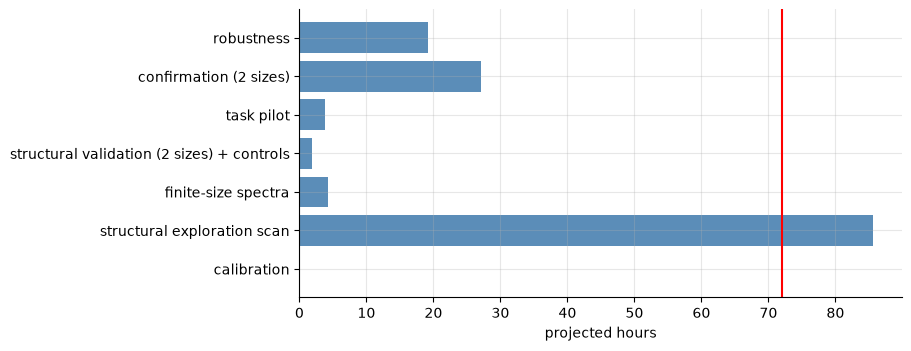

**Fig27_runtime_projection.** Mode preflight; projection from 48 measured structural units (median unit times {'stab': 6.280199049971998, 'lyap': 2.0729052500100806, 'chan': 1.4056598499882966, 'kern': 12.929103799979202}); conservative = expected x 1.3 x 1.04 (90th/50th percentile). Red: budget.

[16.2 runtime projection] 0.2 s | peak RSS 1165 MB


In [29]:
RUNTIME = {}
with section("16.2 runtime projection"):
    ur = [r for r in SCAN_ROWS if "sec_stab" in r]
    if ur:
        def tmed(key):
            v = [r[key] for r in ur if key in r and np.isfinite(r[key])]; return (float(np.median(v)), float(np.percentile(v, 90) / max(np.median(v), 1e-9))) if v else (0.0, 1.0)
        (t_st, s1), (t_ly, s2), (t_ch, s3), (t_ke, s4) = tmed("sec_stab"), tmed("sec_lyap"), tmed("sec_chan"), tmed("sec_kern")
        R = RCFG; P = CFG; NG, NT = len(R["gain_grid"]), len(R["T_grid"])
        Kt_R, Kt_P = R["washout"] + R["train"] + R["test"], K_TASK
        d_of = lambda N_: 2 * N_ + N_ * (2 * N_ + 1); dP = d_of(P["N_main"])
        unit_R = (t_st * (R["stab_paths"] * Kt_R) / (P["stab_paths"] * Kt_P) + t_ly * (R["lyap_paths"] * (R["lyap_len"] + R["lyap_burn"])) / (P["lyap_paths"] * (P["lyap_len"] + P["lyap_burn"]))
                  + t_ch * (R["chan_paths"] * R["chan_window"] * R["chan_dirs"]) / (P["chan_paths"] * P["chan_window"] * P["chan_dirs"])
                  + t_ke * (R["kernel_paths"] * R["kernel_clocks"] + R["noise_samples"] * R["kernel_clocks"] / 8 + R["res_paths"] * R["res_clocks"] / 8)
                  / (P["kernel_paths"] * P["kernel_clocks"] + P["noise_samples"] * P["kernel_clocks"] / 8 + P["res_paths"] * P["res_clocks"] / 8))
        fss_R = sum(NG * 2 * t_ly * (d_of(N_) / dP) ** 2 * (N_ / P["N_main"]) ** 3 * (R["lyap_paths"] * (R["lyap_len"] + R["lyap_burn"])) / (P["lyap_paths"] * (P["lyap_len"] + P["lyap_burn"]))
                    for N_ in R["N_fss"])
        val_unit = (t_st * (R["stab_paths"] * Kt_R) / (P["stab_paths"] * Kt_P) + t_ke * R["kernel_paths"] / P["kernel_paths"])
        task_unit_t = (float(np.median([p["t_ad"] for p in PILOT])) * 4 * (R["trajectories"] * Kt_R) / (P["trajectories"] * Kt_P)) if PILOT else \
            t_st * 4 * (R["trajectories"] * Kt_R) / (P["stab_paths"] * Kt_P)
        n_rob = sum(len(R[k]) - 1 for k in ("squeezing_grid", "loss_grid", "eta_grid", "jitter_grid", "ff_grid", "resolution_grid"))
        stages = {"calibration": R["n_calib"] * len(R["T_grid"]) * len(set(R["N_fss"]) | {R["N_main"], R["N_second"]}) * 2.0,
                  "structural exploration scan": NG * NT * R["n_explore"] * unit_R,
                  "finite-size spectra": fss_R,
                  "structural validation (2 sizes) + controls": (R["n_validate"] * (1 + 0.5 * (R["N_second"] / R["N_main"]) ** 3) + 4 * 3) * val_unit,
                  "task pilot": R["n_pilot"] * R["pilot_reps"] * task_unit_t * 1.6,
                  "confirmation (2 sizes)": R["n_confirm"] * R["pilot_reps"] * task_unit_t * (1 + (R["N_second"] / R["N_main"]) ** 3),
                  "robustness": n_rob * R["robust_realizations"] * task_unit_t}
        spread = max(s1, s2, s3, s4); expected = sum(stages.values()) / 3600; conservative = expected * 1.3 * spread
        bottleneck = max(stages, key=stages.get)
        RUNTIME = dict(expected_h=expected, conservative_h=conservative, stages_h={k: v / 3600 for k, v in stages.items()}, bottleneck=bottleneck,
                       measured_unit_s=dict(stab=t_st, lyap=t_ly, chan=t_ch, kern=t_ke), spread=spread,
                       peak_ram_gb=round(peak_rss_mb() / 1024 * 1.5 + 8 * R["kernel_paths"] * 8 * (4 * R["N_second"]) ** 2 * 10 / 2**30, 2),
                       peak_vram_gb=round(cp.get_default_memory_pool().total_bytes() / 2**30, 2) if CUPY_OK else 0.0,
                       checkpoint_gb=round(max(STORE.size_mb(), 1) / 1024 * (NG * NT * R["n_explore"]) / max(1, len(ur)) * 1.5 + 0.2, 2),
                       native_fraction=TIMERS["native_s"] / max(1e-9, time.perf_counter() - NOTEBOOK_T0), gpu_fraction=TIMERS["adapter_gpu_s"] / max(1e-9, TIMERS["adapter_s"]))
        RT_DF = pd.Series({**{f"stage: {k}": f"{v:.2f} h" for k, v in RUNTIME["stages_h"].items()}, "expected": f"{expected:.1f} h",
                           "conservative": f"{conservative:.1f} h", "budget": f"{AVAILABLE_RUNTIME_HOURS} h", "bottleneck": bottleneck,
                           "peak RAM (est.)": f"{RUNTIME['peak_ram_gb']} GB", "peak VRAM (pool)": f"{RUNTIME['peak_vram_gb']} GB", "checkpoint size (est.)": f"{RUNTIME['checkpoint_gb']} GB",
                           "native-engine time fraction (this run)": f"{RUNTIME['native_fraction']:.1%}", "adapter time on GPU (this run)": f"{RUNTIME['gpu_fraction']:.1%}"})
        display(RT_DF.to_frame("research projection"))
        RUNTIME_OK = conservative <= AVAILABLE_RUNTIME_HOURS
        if not RUNTIME_OK:
            var = {"structural exploration scan": "n_explore (or gain_grid/T_grid)", "confirmation (2 sizes)": "n_confirm", "robustness": "robust_realizations",
                   "finite-size spectra": "N_fss / lyap_len", "task pilot": "n_pilot"}.get(bottleneck, "trajectories")
            print(f"PROJECTED RUNTIME EXCEEDS BUDGET ({conservative:.1f} h > {AVAILABLE_RUNTIME_HOURS} h); bottleneck '{bottleneck}' -> reduce CONFIGS['research']['{var}'] "
                  f"by ~x{AVAILABLE_RUNTIME_HOURS / conservative:.2f}")
        fig, ax = plt.subplots(figsize=(9, 3.4)); ax.barh(list(RUNTIME["stages_h"]), list(RUNTIME["stages_h"].values()), color="#5b8db8"); ax.axvline(AVAILABLE_RUNTIME_HOURS, color="r")
        ax.set_xlabel("projected hours")
        show_fig(fig, "Fig27_runtime_projection", f"Mode {RUN_MODE}; projection from {len(ur)} measured structural units (median unit times {RUNTIME['measured_unit_s']}); "
                 f"conservative = expected x 1.3 x {spread:.2f} (90th/50th percentile). Red: budget.")
    else:
        RUNTIME_OK = None; print("runtime projection: no structural units measured in this mode")

## 17. Machine-generated gates and decision

Any failure of a critical gate (physics, causality, stability, spectrum, visibility or dry run) gives `NO-GO`. Fixable resource or runtime problems give `CONDITIONAL GO`. `GO` means only that the implementation is valid, the response is identifiable and the research run is adequately powered. It does not guarantee a positive result.

,gate,requirement,evidence,status,critical
0,Source audit,source notebooks found and hashed,5/5 present; predecessor parsed=True,PASS,False
1,Native fidelity,"native, adapter and reference agree","V1 exact replay, V3, V4",PASS,True
2,Causal validity,adaptive graph follows MBQC flow,V5 DAG + CV-flow certificate,PASS,True
3,Zero-adaptivity nesting,AD at g=0 equals NA,V6 bitwise + ensemble,PASS,True
4,Safe angles,no singular homodyne angles,V7 + scan min|sin theta|,PASS,True
5,Physicality,all states and measurements valid,"V9, V10, V11, V12, K8",PASS,True
6,Stability,escape upper bound below threshold at the lock,validation CP bound 0.332 (315 escaped paths),FAIL,True
7,Full Lyapunov spectrum,full spectrum passes analytic tests,"L1-L7, L11, L12",PASS,True
8,Spectrum convergence,"stable under length, QR interval and trajectories","L7, L8, L9, L10",PASS,False
9,CI/CR separation,both spectra implemented correctly,L5 exact Jacobian; distinct CI/CR spectra (Fig. 6/7),PASS,True



=== DECISION (preflight): NO-GO ===
 - critical gate failed: Stability
 - critical gate failed: Internal response
 - critical gate failed: Measurement visibility
 - critical gate failed: Size replication


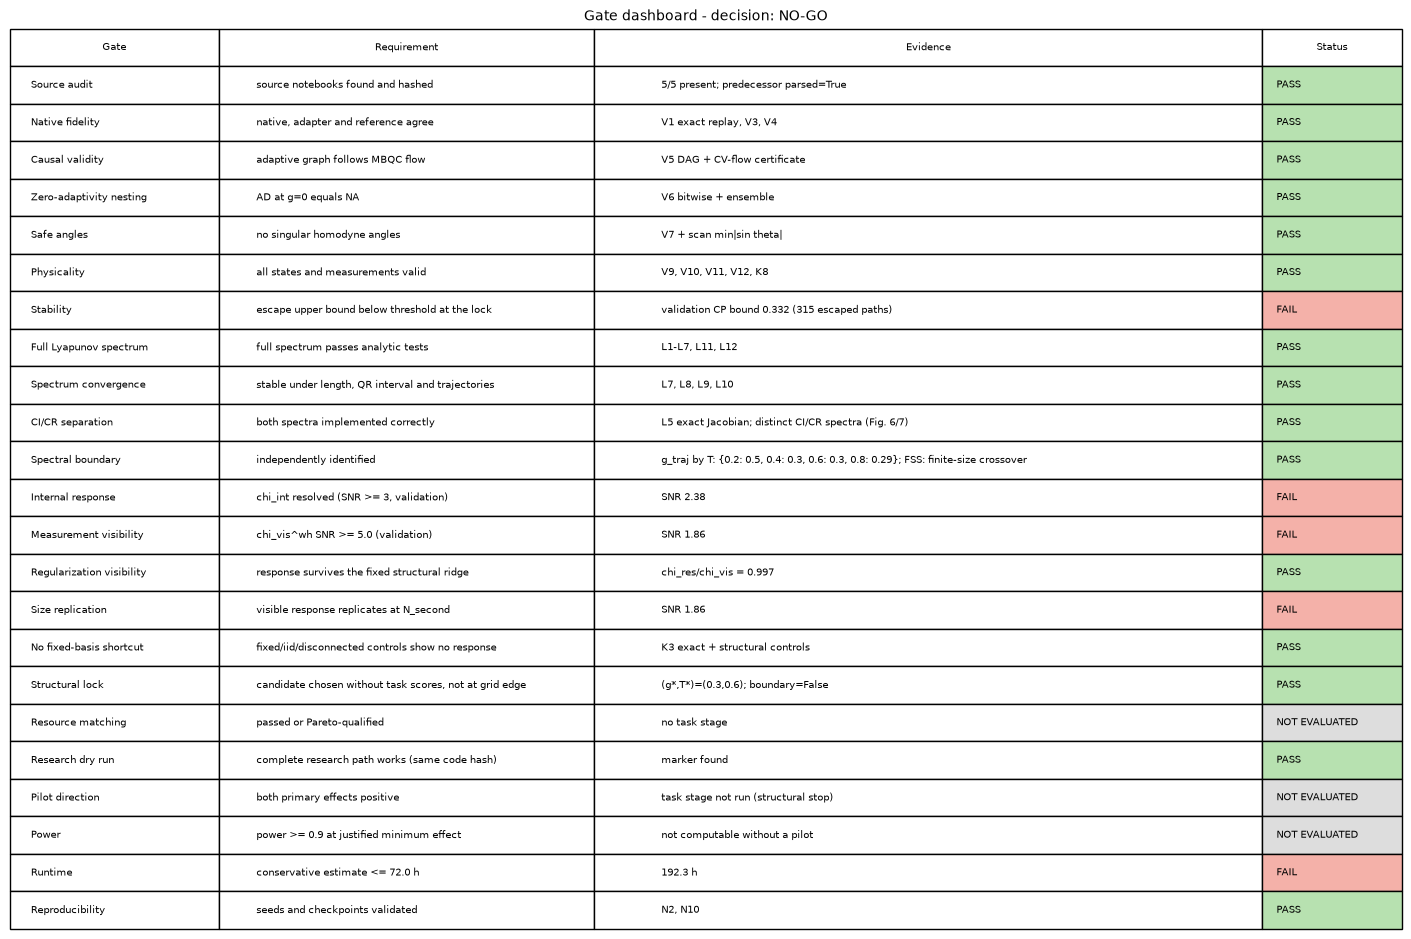

**Fig28_gate_dashboard.** Mode preflight; machine-generated from this run's tests and structural/task results; critical gates: Native fidelity, Causal validity, Zero-adaptivity nesting, Safe angles, Physicality, Stability, Full Lyapunov spectrum, CI/CR separation, Spectral boundary, Internal response, Measurement visibility, Regularization visibility, Size replication, No fixed-basis shortcut, Structural lock, Research dry run, Reproducibility.

In [30]:
TESTS_DF = pd.DataFrame(TESTS); crit_ok = {t["id"]: t["passed"] for t in TESTS}
GATES = []
def gate(name, req, ev, status, critical):
    GATES.append(dict(gate=name, requirement=req, evidence=ev, status=status, critical=critical))
if RUN_MODE != "unit":
    gate("Source audit", "source notebooks found and hashed", f"{int(HASH_DF.present.sum())}/{len(HASH_DF)} present; predecessor parsed={PRED_FOUND}", "PASS" if SOURCE_AUDIT_OK else "WARN", False)
    gate("Native fidelity", "native, adapter and reference agree", "V1 exact replay, V3, V4", "PASS" if all(crit_ok.get(i, False) for i in ("V1", "V3", "V4")) else "FAIL", True)
    gate("Causal validity", "adaptive graph follows MBQC flow", "V5 DAG + CV-flow certificate", "PASS" if crit_ok.get("V5") else "FAIL", True)
    gate("Zero-adaptivity nesting", "AD at g=0 equals NA", "V6 bitwise + ensemble", "PASS" if crit_ok.get("V6") else "FAIL", True)
    gate("Safe angles", "no singular homodyne angles", "V7 + scan min|sin theta|", "PASS" if STRUCT_COND["5 safe-angle condition"] else "FAIL", True)
    gate("Physicality", "all states and measurements valid", "V9, V10, V11, V12, K8", "PASS" if all(crit_ok.get(i, False) for i in ("V9", "V10", "V11", "V12")) else "FAIL", True)
    gate("Stability", "escape upper bound below threshold at the lock", f"validation CP bound {VAL['p_escape_upper']:.3f} ({VAL['escapes']} escaped paths)" if VAL else "no locked point",
         "PASS" if STRUCT_COND["4 full-horizon stability"] else "FAIL", True)
    gate("Full Lyapunov spectrum", "full spectrum passes analytic tests", "L1-L7, L11, L12", "PASS" if STRUCT_COND["6 full Lyapunov-spectrum validation"] else "FAIL", True)
    gate("Spectrum convergence", "stable under length, QR interval and trajectories", "L7, L8, L9, L10", "PASS" if all(crit_ok.get(i, False) for i in ("L7", "L8", "L9", "L10")) else "WARN", False)
    gate("CI/CR separation", "both spectra implemented correctly", "L5 exact Jacobian; distinct CI/CR spectra (Fig. 6/7)", "PASS" if crit_ok.get("L5") else "FAIL", True)
    gate("Spectral boundary", "independently identified", f"g_traj by T: {({float(k): (None if v is None or not np.isfinite(v) else round(float(v), 2)) for k, v in zip(BOUND['T'], BOUND['g_traj'])}) if len(BOUND) else 'n/a'}; FSS: {FSS_RES.get('verdict', '').split(' (')[0]}",
         "PASS" if STRUCT_COND["7 independent spectral boundary or resolved crossover"] else "FAIL", True)
    gate("Internal response", "chi_int resolved (SNR >= 3, validation)", f"SNR {snr(VAL, 'chi_int') if VAL else np.nan:.2f}", "PASS" if STRUCT_COND["8 nonzero internal adaptive response"] else "FAIL", True)
    gate("Measurement visibility", f"chi_vis^wh SNR >= {PREREGISTERED['snr_min']} (validation)", f"SNR {snr(VAL) if VAL else np.nan:.2f}",
         "PASS" if STRUCT_COND["9 chi_vis^wh SNR >= 5 (validation bank)"] else "FAIL", True)
    rv_ok = bool(VAL) and np.isfinite(VAL["chi_res"]["est"]) and VAL["chi_vis"]["est"] > 0 and VAL["chi_res"]["est"] / VAL["chi_vis"]["est"] >= 0.1
    gate("Regularization visibility", "response survives the fixed structural ridge", f"chi_res/chi_vis = {(VAL['chi_res']['est'] / VAL['chi_vis']['est']) if VAL and VAL['chi_vis']['est'] else np.nan:.3g}",
         "PASS" if rv_ok else "FAIL", True)
    gate("Size replication", "visible response replicates at N_second", f"SNR {snr(VAL2) if VAL2 else np.nan:.2f}", "PASS" if STRUCT_COND["10 response replication at a second size"] else "FAIL", True)
    gate("No fixed-basis shortcut", "fixed/iid/disconnected controls show no response", "K3 exact + structural controls", "PASS" if NO_FIXED_SHORTCUT else "FAIL", True)
    gate("Structural lock", "candidate chosen without task scores, not at grid edge", f"(g*,T*)=({G_STAR},{T_STAR}); boundary={LOCK.get('at_grid_boundary') if LOCK else None}",
         "PASS" if STRUCT_COND["11 candidate not at the scanned-grid boundary"] and STRUCT_COND["12 candidate chosen without task performance"] else "FAIL", True)
    gate("Resource matching", "passed or Pareto-qualified", "Pareto table (Fig. 22)" if RESOURCE_DF is not None else "no task stage", "PASS" if RESOURCE_DF is not None else "NOT EVALUATED", False)
    gate("Research dry run", "complete research path works (same code hash)", f"marker {'found' if DRY_OK else 'missing/mismatch'}", "PASS" if DRY_OK else "FAIL", True)
    if PILOT:
        lin = PILOT_RES["linear"]
        gate("Pilot direction", "both primary effects positive", f"Delta_A {lin['A']['mean']:+.4f}, Delta_B {lin['B']['mean']:+.4f}", "PASS" if PROCEED.get("both primary differences positive") else "FAIL", False)
        gate("Power", f"power >= {PREREGISTERED['power_target']} at delta_min={DELTA_MIN:.3f}", f"{POWER.get('at_delta_min')}", "PASS" if POWER and min(POWER["at_delta_min"]) >= PREREGISTERED["power_target"] else "FAIL", False)
    else:
        gate("Pilot direction", "both primary effects positive", "task stage not run (structural stop)", "NOT EVALUATED", False)
        gate("Power", "power >= 0.9 at justified minimum effect", "not computable without a pilot", "NOT EVALUATED", False)
    gate("Runtime", f"conservative estimate <= {AVAILABLE_RUNTIME_HOURS} h", f"{RUNTIME.get('conservative_h', np.nan):.1f} h" if RUNTIME else "n/a", "PASS" if RUNTIME_OK else "FAIL", False)
    gate("Reproducibility", "seeds and checkpoints validated", "N2, N10", "PASS" if crit_ok.get("N2") and crit_ok.get("N10") else "FAIL", True)
    GATE_DF = pd.DataFrame(GATES)
    with pd.option_context("display.max_colwidth", 100, "display.width", 260):
        display(GATE_DF)
    crit_fail = GATE_DF[GATE_DF.critical & (GATE_DF.status != "PASS")].gate.tolist()
    futile = bool(PILOT) and not PROCEED.get("no strong futility (95% upper bounds >= delta_min)", True)
    soft_fail = GATE_DF[(~GATE_DF.critical) & (GATE_DF.status == "FAIL")].gate.tolist()
    if crit_fail:
        DECISION, REASONS = "NO-GO", [f"critical gate failed: {g}" for g in crit_fail]
    elif futile or (PILOT and not all(PROCEED.values())):
        DECISION, REASONS = "NO-GO", ["pilot proceed conditions failed: " + "; ".join(k for k, v in PROCEED.items() if not v)]
    elif soft_fail:
        DECISION, REASONS = "CONDITIONAL GO", [f"fixable gate failed: {g}" for g in soft_fail]
    else:
        DECISION, REASONS = "GO", ["all gates pass (valid, identifiable, adequately powered - NOT a guarantee of a positive result)"]
    if RUN_MODE == "research_dryrun":
        REASONS.append("research_dryrun: control-flow validation only - this decision is not scientific")
    print(f"\n=== DECISION ({RUN_MODE}): {DECISION} ===")
    for r_ in REASONS:
        print(" -", r_)
    (RES / "decision.json").write_text(json.dumps(dict(decision=DECISION, reasons=REASONS, gates=GATES, lock=LOCK, structural=STRUCT_COND, mode=RUN_MODE), indent=1, default=str))
    colors = {"PASS": "#b7e1b0", "WARN": "#f8e5a0", "FAIL": "#f4b1a9", "NOT EVALUATED": "#dddddd"}
    fig, ax = plt.subplots(figsize=(14, 0.36 * len(GATE_DF) + 1)); ax.axis("off")
    tb = ax.table(cellText=[[r.gate, r.requirement[:58], str(r.evidence)[:95], r.status] for r in GATE_DF.itertuples()], colLabels=["Gate", "Requirement", "Evidence", "Status"],
                  bbox=[0, 0, 1, 1], cellLoc="left", colWidths=[0.15, 0.27, 0.48, 0.1]); tb.auto_set_font_size(False); tb.set_fontsize(7)
    for i, r_ in enumerate(GATE_DF.itertuples(), start=1):
        tb[i, 3].set_facecolor(colors.get(r_.status, "white"))
    ax.set_title(f"Gate dashboard - decision: {DECISION}", fontsize=10)
    show_fig(fig, "Fig28_gate_dashboard", f"Mode {RUN_MODE}; machine-generated from this run's tests and structural/task results; critical gates: "
             f"{', '.join(GATE_DF[GATE_DF.critical].gate)}.")
else:
    DECISION, REASONS = "not evaluated (unit mode)", []
    print("unit mode: gates not evaluated (no scientific conclusions)")

## 18. Research-only cells: confirmation and robustness

They run in `research` only after every structural gate and every pilot proceed condition passes, and always in `research_dryrun` to validate control flow. Confirmation uses the **confirmation seed bank**, which the ledger proves was unused, at the hashed lock, with no retuning.

In [31]:
IS_RESEARCH = RUN_MODE in ("research", "research_dryrun")
CONF, CONF_RES, ROB = [], {}, []
go_research = IS_RESEARCH and (RUN_MODE == "research_dryrun" or (STRUCT_ALL and PILOT and all(PROCEED.values())))
if go_research:
    with section("18.1 confirmation"):
        L_ = json.loads((RES / "lock_manifest_structural.json").read_text()); h_ = L_.pop("sha256")
        assert hashlib.sha256(json.dumps(L_, sort_keys=True, default=str).encode()).hexdigest() == h_, "lock manifest altered - confirmation refused"
        led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
        assert not {s for s in led.get("confirmation", {}) if s != "confirmation"}, "confirmation seeds used by another stage"
        gC = G_STAR if G_STAR is not None else (g_task if PILOT else 0.1); TC = T_STAR if T_STAR is not None else CFG["T_grid"][0]
        for N_ in (CFG["N_main"], CFG["N_second"]):
            for rid in CONFIRMATION_SEEDS[:CFG["n_confirm"]]:
                for rep in range(CFG["pilot_reps"]):
                    r = STORE.cached("confirm", dict(rid=rid, rep=rep, g=gC, T=TC, N=N_, M=CFG["trajectories"], L=(CFG["washout"], CFG["train"], CFG["test"]), sigma=SIGMA_HASH, base=BASE),
                                     lambda: task_unit(rid, N_, gC, TC, rep))
                    if r.get("failed"):
                        FAILED_UNITS.append(dict(stage="confirm", rid=rid, N=N_, reason=r["reason"])); continue
                    CONF.append(r)
        ledger_use("confirmation", "confirmation", range(CFG["n_confirm"]))
        rngc = rng_for("confirm-analysis")
        for N_ in sorted({c["N"] for c in CONF}):
            U = [c for c in CONF if c["N"] == N_]
            for fam, suf in (("linear", ""), ("degree-2", "|poly")):
                DA, DB = pilot_array(U, "NA", "AD", suffix=suf), pilot_array(U, "CV", "AD", suffix=suf)
                ra, rb = analyse(DA.reshape(len(DA), -1), DELTA_MIN, CFG["bootstrap"], rngc), analyse(DB.reshape(len(DB), -1), DELTA_MIN, CFG["bootstrap"], rngc)
                ra["p_holm"], rb["p_holm"] = holm([ra["p_one_sided"], rb["p_one_sided"]]); CONF_RES[(N_, fam)] = dict(A=ra, B=rb)
            DP = pilot_array(U, "CV_photon", "AD"); CONF_RES[(N_, "photon")] = analyse(DP.reshape(len(DP), -1), DELTA_MIN, CFG["bootstrap"], rngc)
            CONF_RES[(N_, "lambda")] = {l: (np.mean([c["witness_by_lambda"]["NA"][j] - c["witness_by_lambda"]["AD"][j] for c in U]),
                                            np.mean([c["witness_by_lambda"]["CV"][j] - c["witness_by_lambda"]["AD"][j] for c in U])) for j, l in enumerate(CFG["ridge_grid"])}
        CONF_TABLE = pd.DataFrame({f"N={k[0]} {k[1]}: {lab}": v[x] for k, v in CONF_RES.items() if k[1] in ("linear", "degree-2") for x, lab in (("A", "NA-AD"), ("B", "CV-AD"))}).T
        display(CONF_TABLE[["n_realizations", "mean", "median", "ci_low", "ci_high", "d", "p_one_sided", "p_holm", "P_exceeds_delta_min"]].round(5))
        display(pd.DataFrame(CONF_RES[(CFG["N_main"], "lambda")], index=["NA-AD", "CV-AD"]).T.rename_axis("fixed lambda").round(5))
        print("raw counts:", {N_: len([c for c in CONF if c["N"] == N_]) for N_ in (CFG["N_main"], CFG["N_second"])}, "| excluded:",
              [f for f in FAILED_UNITS if f["stage"] == "confirm"] or "none")
    with section("18.2 robustness"):
        conds = [("base", {}, 0.0)]
        conds += [(f"squeezing {v:g} dB", dict(squeezing_db=v), 0.0) for v in CFG["squeezing_grid"] if v != BASE["squeezing_db"]]
        conds += [(f"loss (transmissivity) {v:g}", dict(loop_transmissivity=v), 0.0) for v in CFG["loss_grid"] if v != BASE["loop_transmissivity"]]
        conds += [(f"detector efficiency {v:g}", dict(detector_efficiency=v), 0.0) for v in CFG["eta_grid"] if v != BASE["detector_efficiency"]]
        conds += [(f"angle jitter {v:g}", dict(angle_jitter=v), 0.0) for v in CFG["jitter_grid"] if v != BASE["angle_jitter"]]
        conds += [(f"feedforward error {v:g}", dict(feedforward_gain_error=v), 0.0) for v in CFG["ff_grid"] if v != BASE["feedforward_gain_error"]]
        conds += [(f"homodyne resolution noise {v:g}", dict(homodyne_noise=v), 0.0) for v in CFG["resolution_grid"] if v != BASE["homodyne_noise"]]
        conds += [(f"depth L={CFG['L_depth'] + 1}", {"_L": CFG["L_depth"] + 1}, 0.0)]
        for name, over, _ in conds:
            for rid in CONFIRMATION_SEEDS[CFG["n_confirm"]:CFG["n_confirm"] + CFG["robust_realizations"]]:
                def rob_unit(name=name, over=over, rid=rid):
                    cd = cond_of(**{k: v for k, v in over.items() if not k.startswith("_")}); Lr = over.get("_L", CFG["L_depth"])
                    key = (CFG["N_main"], Lr, round(TC, 9))
                    if key not in SIGMA:
                        SIGMA[key] = calibrate_sigma(CFG["N_main"], Lr, TC)
                    m = make_model(rid, CFG["N_main"], Lr, TC, cd); ul = input_sequence(rid, 5001, CFG["lyap_burn"] + CFG["lyap_len"])
                    sp = summarize_spectrum(reservoir_spectrum(m, gC, ul, max(2, CFG["lyap_paths"] // 2), CFG["lyap_ntan"], "CI", CFG["lyap_qr"], CFG["lyap_burn"], CFG["lyap_len"], ("rob", rid, name)))
                    spr = summarize_spectrum(reservoir_spectrum(m, gC, ul, max(2, CFG["lyap_paths"] // 2), CFG["lyap_ntan"], "CR", CFG["lyap_qr"], CFG["lyap_burn"], CFG["lyap_len"], ("robr", rid, name)))
                    ch = ensemble_channel_spectrum(m, gC, ul, CFG["chan_paths"], 2, CFG["chan_window"], ("robc", rid, name)) if gC else [np.nan]
                    sus = susceptibilities(m, gC, rid, CFG["kernel_paths"], CFG["kernel_clocks"], CFG["kernel_fd_step"], xp=DEVICE["kernels"])
                    tu = task_unit(rid, CFG["N_main"], gC, TC, 0, cond=cd, light=True) if Lr == CFG["L_depth"] else None
                    return dict(cond=name, rid=rid, lambda1_CI=sp["lambda1"] if sp else np.inf, lambda1_CR=spr["lambda1"] if spr else np.inf, gap=sp["gap"] if sp else np.nan,
                                Lambda1_ch=float(ch[0]), chi_int=sus.get("chi_int", (np.nan,))[0], chi_wh=sus.get("chi_wh", (np.nan,))[0],
                                dA=(tu["NA"]["witness"] - tu["AD"]["witness"]) if tu else np.nan)
                r = STORE.cached("robust", dict(name=name, over=over, rid=rid, g=gC, T=TC, sigma=SIGMA_HASH), rob_unit)
                if r.get("failed"):
                    FAILED_UNITS.append(dict(stage="robust", cond=name, rid=rid, reason=r["reason"])); continue
                ROB.append(r)
        ledger_use("confirmation", "confirmation", range(CFG["n_confirm"], CFG["n_confirm"] + CFG["robust_realizations"]))
    if ROB:
        RB = pd.DataFrame(ROB).drop(columns="rid", errors="ignore").groupby("cond").mean(numeric_only=True); display(RB.round(5))
        fig, axs = plt.subplots(1, 4, figsize=(18, 0.35 * len(RB) + 2), sharey=True)
        for ax, col in zip(axs, ("lambda1_CI", "Lambda1_ch", "chi_wh", "dA")):
            ax.barh(range(len(RB)), np.where(np.isfinite(RB[col]), RB[col], np.nan), color=COL["AD"]); ax.set_title(col, fontsize=9); ax.axvline(0, color="k", lw=0.6)
        axs[0].set_yticks(range(len(RB)), RB.index, fontsize=7)
        show_fig(fig, "Fig23_robustness_maps", f"Mode {RUN_MODE}; N={CFG['N_main']}, (g,T)=({gC},{TC}); {CFG['robust_realizations']} confirmation-bank realizations per condition (beyond "
                 f"the confirmatory ones); spectra {max(2, CFG['lyap_paths'] // 2)} paths x {CFG['lyap_len']} clocks; means; {'CONTROL-FLOW TEST' if RUN_MODE == 'research_dryrun' else 'confirmatory robustness'}.")
else:
    print(f"RUN_MODE={RUN_MODE!r}: confirmation and robustness not executed" + ("" if not IS_RESEARCH else " - structural/pilot conditions not met (NO-GO)"))

RUN_MODE='preflight': confirmation and robustness not executed


## 19. Claim ladder and final conclusions

Levels cannot be skipped. Even Level 9 would be worded only as an *adaptive measurement-based reservoir advantage over matched nonadaptive CV-MB-QRC and conventional CV-QRC architectures*. The models are Gaussian and efficiently classically simulable.

In [32]:
TESTS_DF = pd.DataFrame(TESTS); CRITICAL_FAILS = TESTS_DF[(TESTS_DF.critical) & (~TESTS_DF.passed)].id.tolist()
def L_(status, ev):
    return dict(status=status, evidence=ev)
LAD = {0: L_("established", "all cells executed")}
phys_ok = not CRITICAL_FAILS
LAD[1] = L_("established" if phys_ok else "not supported", f"{int(TESTS_DF.passed.sum())}/{len(TESTS_DF)} tests; critical failures {CRITICAL_FAILS or 'none'}")
if RUN_MODE == "unit":
    for k in range(2, 11):
        LAD[k] = L_("not evaluated (unit mode)", "-")
else:
    LAD[2] = L_("established" if STRUCT_COND["3 valid within-pattern causal ordering"] and STRUCT_COND["2 exact zero-adaptivity nesting"] else "not supported",
                "within-pattern Outcome-dependent angles (native), CV-flow certificate, exact nesting")
    LAD[3] = L_("established" if STRUCT_COND["6 full Lyapunov-spectrum validation"] else "not supported", "CI/CR spectra validated (L1-L13); channel exact at g=0, ensemble-tangent estimate otherwise (L14)")
    LAD[4] = L_(("established (finite-size crossover)" if "crossover" in FSS_RES.get("verdict", "") or "insufficient" in FSS_RES.get("verdict", "") else "established")
                if STRUCT_COND["7 independent spectral boundary or resolved crossover"] else "not supported", f"g_traj(T) = {dict(zip(BOUND['T'], BOUND['g_traj'])) if len(BOUND) else 'n/a'}")
    LAD[5] = L_("established" if STRUCT_COND["8 nonzero internal adaptive response"] else "not resolved", f"chi_int SNR (validation) {snr(VAL, 'chi_int') if VAL else np.nan:.2f}")
    LAD[6] = L_("established" if STRUCT_COND["9 chi_vis^wh SNR >= 5 (validation bank)"] and STRUCT_COND["10 response replication at a second size"] else "not supported",
                f"chi_vis^wh SNR {snr(VAL) if VAL else np.nan:.2f} (validation), {snr(VAL2) if VAL2 else np.nan:.2f} (N={CFG['N_second']})")
    if RUN_MODE == "research" and CONF_RES:
        A_ = CONF_RES[(CFG["N_main"], "linear")]["A"]; B_ = CONF_RES[(CFG["N_main"], "linear")]["B"]; A2 = CONF_RES[(CFG["N_main"], "degree-2")]["A"]
        l7 = A_["p_holm"] < PREREGISTERED["alpha"] and A_["mean"] >= DELTA_MIN; l8 = l7 and B_["p_holm"] < PREREGISTERED["alpha"] and B_["mean"] >= DELTA_MIN
        rob = (pd.DataFrame(ROB).groupby("cond").dA.mean() > 0).all() if ROB else False
        LAD[7] = L_("established" if l7 else "not supported", f"Delta_A {A_['mean']:+.4f} [{A_['ci_low']:+.4f},{A_['ci_high']:+.4f}], Holm p {A_['p_holm']:.3g}")
        LAD[8] = L_("established" if l8 else "not supported", f"Delta_B {B_['mean']:+.4f}, Holm p {B_['p_holm']:.3g}")
        LAD[9] = L_("established" if l8 and A2["mean"] >= DELTA_MIN and rob else "not supported", f"degree-2 Delta_A {A2['mean']:+.4f}; robust={rob}")
        LAD[10] = L_("suggested" if l8 and "transition" in FSS_RES.get("verdict", "") else "not supported", FSS_RES.get("verdict"))
    else:
        for k in range(7, 11):
            LAD[k] = L_("requires the research run" if STRUCT_ALL else "blocked by the structural stage", "confirmatory task data not collected")
LADDER = pd.DataFrame(LAD).T; LADDER.index.name = "level"; display(LADDER)
highest = -1
for k in range(11):
    if str(LAD[k]["status"]).startswith("established"):
        highest = k
    else:
        break
print("highest established level (no skipping):", highest)
if RUN_MODE == "research" and CONF_RES:
    fig, ax = plt.subplots(figsize=(9, 3.6)); cmap = {"established": "#4caf50", "suggested": "#ffc107", "not": "#e57373"}
    ax.barh(range(11), [1] * 11, color=[next((c for s, c in cmap.items() if str(LAD[k]["status"]).startswith(s)), "#bdbdbd") for k in range(11)])
    ax.set_yticks(range(11), [f"L{k}: {LAD[k]['status']}" for k in range(11)], fontsize=7); ax.invert_yaxis(); ax.set_xticks([])
    show_fig(fig, "Fig29_claim_ladder", f"Research claim ladder; confirmatory n = {CFG['n_confirm']} per size; highest established level {highest}.")

EST, SUG, REJ, NEED = [], [], [], []
if phys_ok:
    EST.append("Implementation validated: native PhotoGraphiQ adaptive patterns, the exact adapter and an independent reference agree exactly on conditional states and likelihoods; "
               "all critical physics, causal, spectrum, numerical and statistical tests pass.")
if RUN_MODE != "unit":
    if LAD[2]["status"] == "established":
        EST.append("Genuine within-pattern adaptivity is implemented: layer-j homodyne angles are native Outcome expressions of layer j-1 of the same clock; the measurement order "
                   "has a native CV-flow certificate; g=0 reproduces NA bitwise.")
    if STRUCT_ZERO_OK:
        EST.append("Selection rule re-derived and verified on the native layered channel: NA (any fixed or input-independent random later-layer basis) and CV-QRC have exactly zero K* "
                   "response (internal and visible); the witness floor of both baselines is NMSE = 1 for linear readouts.")
    esc_lo = SCAN[SCAN.p_escape_upper < PREREGISTERED["escape_pmax"]].groupby("T").g.max().to_dict() if len(SCAN) else {}
    esc_first = SCAN[SCAN.escapes > 0].groupby("T").g.min().to_dict() if len(SCAN) else {}
    EST.append(f"Stability (numerical observation): smallest scanned gain with any escaped trajectory, by T: {esc_first or 'none observed'}; largest scanned gain certified stable "
               f"(CP upper bound < {PREREGISTERED['escape_pmax']}, exploration realizations) by T: {esc_lo or 'none certified at this path count'}"
               + (f"; at the locked point the independent validation realizations (same horizon) escaped in {VAL['escapes']} paths (CP bound {VAL['p_escape_upper']:.3f})" if VAL else "") + ". Mechanism of escape: teleportation outcomes are dominated by the anti-squeezed resource quadrature, so the controller mostly injects outcome noise into the angles; "
               "near the angle bounds the shear cot(theta) reaches ~cot(theta_min).")
    if LAD[4]["status"].startswith("established"):
        EST.append(f"Independent dynamical boundary: lambda_1^CI crosses zero at g_traj(T) (FSS verdict: {FSS_RES.get('verdict')}).")
    if LAD[5]["status"] != "established":
        SUG.append(f"Internal adaptive response at the lock: chi_int SNR {snr(VAL, 'chi_int') if VAL else np.nan:.2f} (< 3): not resolved.")
    if LAD[6]["status"] != "established":
        REJ.append(f"Readout-visible adaptive response above finite-shot noise at the locked point: chi_vis^wh SNR {snr(VAL) if VAL else np.nan:.2f} < {PREREGISTERED['snr_min']} "
                   f"(validation bank) - {TAXONOMY}.")
    if CTRL_STRUCT:
        ind = CTRL_STRUCT.get("indep", {})
        SUG.append(f"Mechanism diagnostic (same-input independent-copy outcomes): chi_vis^wh SNR {snr(ind) if ind else np.nan:.2f}; fixed/iid/disconnected controls SNRs "
                   f"{[round(snr(CTRL_STRUCT[c]), 2) if CTRL_STRUCT.get(c) else None for c in ('g0', 'iid', 'disconnected')]}.")
    SUG.append(f"Finite-size scaling: {FSS_RES.get('verdict')} ({FSS_RES.get('n_sizes', 0)} sizes).")
    if PILOT:
        lin = PILOT_RES["linear"]; nl = PILOT_RES["degree-2"]
        SUG.append(f"Pilot (exploratory): linear Delta_A {lin['A']['mean']:+.4f} [{lin['A']['ci_low']:+.4f},{lin['A']['ci_high']:+.4f}], Delta_B {lin['B']['mean']:+.4f}; "
                   f"degree-2 Delta_A {nl['A']['mean']:+.4f}, Delta_B {nl['B']['mean']:+.4f}.")
        if not PROCEED.get("no strong futility (95% upper bounds >= delta_min)", True):
            REJ.append(f"Operational advantage >= delta_min={DELTA_MIN:.3f}: excluded by the pilot (futility).")
    REJ.append(f"Predecessor's inter-clock feedback design: NO-GO preserved (chi SNR {SRC['chi_snr']}, Delta_A {SRC['delta_A']}, Delta_B {SRC['delta_B']}); quadratic post-processing "
               f"of NA features beat AD ({SRC['D1_quadratic_NA']} vs {FROZEN_PRED['D1_AD']}).")
    if not STRUCT_ALL:
        NEED.append("None justified with the current configuration: the structural-first stopping rule failed, so a long task run would test a response that is not identifiable "
                    "(see Final verdict).")
    elif RUN_MODE != "research":
        NEED.append(f"Confirmation of H_A and H_B with {RCFG['n_confirm']} realizations x {RCFG['pilot_reps']} replicates at N in ({RCFG['N_main']}, {RCFG['N_second']}); "
                    f"projected {RUNTIME.get('expected_h', np.nan):.1f} h (conservative {RUNTIME.get('conservative_h', np.nan):.1f} h) on {ENV['CPU']}"
                    f"{' + ' + str(ENV['GPU']) if GPU_VALIDATED else ''}.")
    if RUN_MODE == "research" and CONF_RES:
        for k in (7, 8, 9, 10):
            (EST if str(LAD[k]["status"]).startswith("established") else REJ).append(f"Level {k}: {LAD[k]['evidence']}")
for title, items in (("Claims established by executed data", EST), ("Claims suggested but not established", SUG), ("Claims rejected", REJ), ("Claims requiring a longer run", NEED)):
    print(f"\n## {title}")
    for it in items or ["(none)"]:
        print(" -", it)
FINAL_VERDICT = DECISION if RUN_MODE not in ("unit",) else "not evaluated (unit mode)"
print(f"\n## Final verdict\n{FINAL_VERDICT}" + (f"  [{STOP_MSG}]" if RUN_MODE != "unit" else ""))
print("Strongest permitted wording if ever established: 'Adaptive measurement-based reservoir advantage over matched nonadaptive CV-MB-QRC and conventional CV-QRC "
      "architectures' - never 'quantum advantage'; all models are Gaussian and efficiently classically simulable.")

,status,evidence
level,,
0,established,all cells executed
1,established,50/50 tests; critical failures none
2,established,within-pattern Outcome-dependent angles (nativ...
3,established,CI/CR spectra validated (L1-L13); channel exac...
4,established (finite-size crossover),"g_traj(T) = {0.2: 0.500000171475312, 0.4: 0.30..."
5,not resolved,chi_int SNR (validation) 2.38
6,not supported,"chi_vis^wh SNR 1.86 (validation), 1.86 (N=4)"
7,blocked by the structural stage,confirmatory task data not collected
8,blocked by the structural stage,confirmatory task data not collected


highest established level (no skipping): 4

## Claims established by executed data
 - Implementation validated: native PhotoGraphiQ adaptive patterns, the exact adapter and an independent reference agree exactly on conditional states and likelihoods; all critical physics, causal, spectrum, numerical and statistical tests pass.
 - Genuine within-pattern adaptivity is implemented: layer-j homodyne angles are native Outcome expressions of layer j-1 of the same clock; the measurement order has a native CV-flow certificate; g=0 reproduces NA bitwise.
 - Selection rule re-derived and verified on the native layered channel: NA (any fixed or input-independent random later-layer basis) and CV-QRC have exactly zero K* response (internal and visible); the witness floor of both baselines is NMSE = 1 for linear readouts.
 - Stability (numerical observation): smallest scanned gain with any escaped trajectory, by T: {0.2: 0.8, 0.4: 0.5, 0.6: 0.5, 0.8: 0.5}; largest scanned gain certified stable (CP u

## 20. EXACT INSTRUCTIONS FOR THE 48–72 HOUR RUN

In [33]:
RC = CONFIGS["research"]
print("EXACT INSTRUCTIONS FOR THE 48-72 HOUR RUN\n" + "=" * 44)
if RUN_MODE != "unit" and DECISION == "NO-GO":
    print("Do not launch the long run with the current configuration.\n(Reason: " + "; ".join(REASONS) + ")\n")
print(f"""1. Cell to edit: the cell titled 'USER CONTROL PANEL — CHANGE ONLY THIS CELL' (first code cell, §2).
2. Line to change:  RUN_MODE = "preflight"   ->   RUN_MODE = "research"
   (keep the seed banks, PREREGISTERED and RESUME_FROM_CHECKPOINT = True unchanged)
3. Research configuration (CONFIGS["research"]):""")
for k, v in RC.items():
    print(f"     {k:24s} = {v}")
print(f"""4. GPU validation: {GPU_VALIDATED} (per-workload backends {DEVICE_LOG}; N1 and L11 agreement tests: {[t['value'] for t in TESTS if t['id'] in ('N1', 'L11')]}).
5. Runtime: expected {RUNTIME.get('expected_h', float('nan')):.1f} h, conservative {RUNTIME.get('conservative_h', float('nan')):.1f} h (budget {AVAILABLE_RUNTIME_HOURS} h).
6. RAM ~{RUNTIME.get('peak_ram_gb', float('nan'))} GB (machine {ENV['RAM (GB)']} GB); VRAM {RUNTIME.get('peak_vram_gb', 0)} GB (CuPy pool in this run).
7. Disk: >= {max(2.0, 3 * RUNTIME.get('checkpoint_gb', 0.5)):.1f} GB free (currently {ENV['free disk at results dir (GB)']} GB).
8. Checkpoints: {Path(CHECKPOINT_DIR).resolve() / 'research'}; results: {Path(RESULTS_DIR).resolve() / 'research'}.
9. Resume: restart the kernel and 'Run all' again with RESUME_FROM_CHECKPOINT = True; finished units are reloaded, failed units retried (test N10).
10. Failed units: printed in the FAILED_UNITS table below; on disk every checkpoint pickle with failed=True carries 'reason' and 'traceback'.
11. Seed ledger: {Path(RESULTS_DIR).resolve() / 'research' / 'seed_ledger.json'} - §18 asserts that the confirmation bank was used by no stage other than 'confirmation'; test S2 checks
    that all five banks are disjoint.
12. Conclusion cells to rerun after completion: §17 (gates), §18 (confirmation analysis), §19 (claims) and §20; a plain 'Run all' recomputes nothing already finished.
13. Export: Colab -> File -> Download -> .ipynb; locally -> File -> Save, or headless:
    jupyter nbconvert --to notebook --execute --inplace adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb""")
hw = []
if RUNTIME and not RUNTIME_OK:
    hw.append("the research configuration exceeds the budget - apply the §16.2 reduction")
if RUNTIME and RUNTIME.get("peak_ram_gb", 0) > 0.8 * ENV["RAM (GB)"]:
    hw.append(f"CONFIGS['research']['kernel_paths'] = {RC['kernel_paths'] // 2}")
print("Hardware-dependent changes:", "; ".join(hw) if hw else "none required on this machine.")
display(pd.DataFrame(FAILED_UNITS)) if FAILED_UNITS else print("FAILED_UNITS: none")
print(f"section times (s): { {k: round(v, 1) for k, v in SECTION_TIMES.items()} }\ntotal: {(time.perf_counter() - NOTEBOOK_T0) / 60:.1f} min | store: {STORE.hits} reused, "
      f"{STORE.misses} computed, {STORE.failures} failed, {STORE.size_mb():.1f} MB")
(RES / "run_summary.json").write_text(json.dumps(dict(mode=RUN_MODE, decision=DECISION, reasons=REASONS, ladder=LAD, lock=LOCK, runtime=RUNTIME, tests=TESTS, failed_units=FAILED_UNITS,
                                                     figures=FIGS, env=ENV, code_hash=GATE_CODE_HASH), indent=1, default=str))
if RUN_MODE == "research_dryrun":
    marker = Path(RESULTS_DIR).resolve() / "research_dryrun" / "dryrun_marker.json"
    marker.write_text(json.dumps(dict(passed=True, code_hash=GATE_CODE_HASH, completed=time.strftime("%Y-%m-%d %H:%M:%S"),
                                      stages=dict(scan=len(SCAN_ROWS), lock=LOCK is not None, validation=bool(VAL), pilot=len(PILOT), confirmation=len(CONF), robustness=len(ROB)))))
    print("research_dryrun completed end to end; marker written:", marker)

EXACT INSTRUCTIONS FOR THE 48-72 HOUR RUN
Do not launch the long run with the current configuration.
(Reason: critical gate failed: Stability; critical gate failed: Internal response; critical gate failed: Measurement visibility; critical gate failed: Size replication)

1. Cell to edit: the cell titled 'USER CONTROL PANEL — CHANGE ONLY THIS CELL' (first code cell, §2).
2. Line to change:  RUN_MODE = "preflight"   ->   RUN_MODE = "research"
   (keep the seed banks, PREREGISTERED and RESUME_FROM_CHECKPOINT = True unchanged)
3. Research configuration (CONFIGS["research"]):
     N_main                   = 3
     N_second                 = 4
     L_depth                  = 3
     N_fss                    = [2, 3, 4, 5]
     gain_grid                = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.65, 0.8, 1.0]
     T_grid                   = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
     n_calib                  = 10
     calib_paths              = 1024
     calib_clocks             = 500
   

## 21. References

1. D. E. Browne, M. B. Elliott, S. T. Flammia, S. T. Merkel, A. Miyake, A. J. Short, *Phase transition of computational power in the resource states for one-way quantum computation*, New J. Phys. **10**, 023010 (2008).
2. A. S. Darmawan, G. K. Brennen, S. D. Bartlett, *Measurement-based quantum computation in a two-dimensional phase of matter*, New J. Phys. **14**, 013023 (2012).
3. R. Raussendorf, C. Okay, D.-S. Wang, D. T. Stephen, H. Poulsen Nautrup, *Computationally universal phase of quantum matter*, Phys. Rev. Lett. **122**, 090501 (2019).
4. J. Iaconis, A. Lucas, X. Chen, *Measurement-induced phase transitions in quantum automaton circuits*, Phys. Rev. B **102**, 224311 (2020).
5. K. Mochizuki, R. Hamazaki, *Measurement-Induced Spectral Transition*, Phys. Rev. Lett. **134**, 010410 (2025).
6. O. Morguí-Sancho, G. L. Giorgi, G. Manzano, R. Zambrini, *General theory of monitored Quantum Reservoir Computing*, arXiv:2607.14311 (2026).
7. J. Cao, R.-Y. Gong, Z. Lin, Y. Zeng, Z.-L. Xiang, *Liouvillian Response for Temporal Information in Quantum Reservoir Computing*, arXiv:2609.23429 (2026).
8. Z. Wu *et al.*, *Measurement- and Feedback-Driven Nonequilibrium Phase Transitions on a Quantum Processor*, Phys. Rev. Lett. **137**, 010401 (2026).
9. J. García-Beni, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Scalable photonic platform for real-time quantum reservoir computing*, Phys. Rev. Applied **20**, 014051 (2023).
10. J. García-Beni, I. Paparelle, V. Parigi, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Quantum machine learning via continuous-variable cluster states and teleportation*, EPJ Quantum Technol. **12**, 63 (2025).
11. PhotoGraphiQ contributors, *PhotoGraphiQ* (software manuscript draft, 10 Sep 2026), commit `6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e`; R. I. Booth, D. Markham, *Flow conditions for continuous variable measurement-based quantum computing*, Quantum **7**, 1146 (2023).
12. Z. Kolarovszki *et al.*, *Piquasso: a photonic quantum computer simulation software platform*, Quantum **9**, 1708 (2025).
13. S. D. Bartlett, B. C. Sanders, S. L. Braunstein, K. Nemoto, *Efficient classical simulation of continuous variable quantum information processes*, Phys. Rev. Lett. **88**, 097904 (2002).
14. A. Mari, J. Eisert, *Positive Wigner functions render classical simulation of quantum computation efficient*, Phys. Rev. Lett. **109**, 230503 (2012).
15. J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012).
16. G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems*, Meccanica **15**, 9 (1980).
17. J. R. R. A. Martins, P. Sturdza, J. J. Alonso, *The complex-step derivative approximation*, ACM Trans. Math. Softw. **29**, 245 (2003).
18. S. Holm, *A simple sequentially rejective multiple test procedure*, Scand. J. Stat. **6**, 65 (1979).
19. C. J. Clopper, E. S. Pearson, *The use of confidence or fiducial limits illustrated in the case of the binomial*, Biometrika **26**, 404 (1934).